In [1]:
# ==========================================================
# Step-1 : Import Required Libraries
# ==========================================================

import os
from pathlib import Path

os.environ["SCIPY_ARRAY_API"] = "1"

import numpy as np
import pandas as pd
import geopandas as gpd
import pyreadstat
import matplotlib.pyplot as plt

from libpysal.weights import KNN


# ==========================================================
# Preprocessing / Splitting
# ==========================================================

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupShuffleSplit


# ==========================================================
# Machine-Learning Models
# ==========================================================

from sklearn.linear_model import (
    LogisticRegression,
    SGDClassifier,
)

from sklearn.tree import (
    DecisionTreeClassifier,
)

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier,
    HistGradientBoostingClassifier,
)

from sklearn.svm import (
    SVC,
)

from sklearn.naive_bayes import (
    GaussianNB,
)


# ==========================================================
# Evaluation Metrics
# ==========================================================

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    roc_curve,
    precision_recall_curve,
)


# ==========================================================
# External Boosting Libraries
# ==========================================================

from xgboost import XGBClassifier

from lightgbm import LGBMClassifier

from catboost import CatBoostClassifier


# ==========================================================
# IMPORTANT
#
# Global SHAP has intentionally been removed.
# GeoShapley is retained later in the spatial
# interpretation section of the notebook.
#
# KNeighborsClassifier has also been removed because
# the present survey-weighted modelling framework requires
# estimators that can use sample_weight during model fitting.
# ==========================================================


print("=" * 70)
print("Spatial Machine Learning Libraries Loaded Successfully")
print("=" * 70)

print(
    "✓ Global warning suppression is NOT enabled."
)

print(
    "✓ Global SHAP is NOT imported."
)

print(
    "✓ GeoShapley remains the spatial interpretation method."
)

print(
    "✓ Survey-weight-compatible candidate models are available."
)

Spatial Machine Learning Libraries Loaded Successfully
✓ Global warning suppression is NOT enabled.
✓ Global SHAP is NOT imported.
✓ GeoShapley remains the spatial interpretation method.
✓ Survey-weight-compatible candidate models are available.


In [2]:
# ==========================================================
# Step-2 : Load Data
# ==========================================================

# ----------------------------------------------------------
# File Paths
# ----------------------------------------------------------

BDHS_FILE = Path(
    r"F:\Thesis\Stunting_Final .SAV"
)

GPS_FILE = Path(
    r"F:/Thesis/GPS DATA/Division/BDGE81FL.shp"
)

ENV_FILE = Path(
    r"F:/Thesis/GPS DATA/bdhs_env_2022.csv"
)

# ----------------------------------------------------------
# Check File Availability
# ----------------------------------------------------------

for file in [
    BDHS_FILE,
    GPS_FILE,
    ENV_FILE
]:

    if not file.exists():

        raise FileNotFoundError(
            f"File not found:\n{file}"
        )

# ----------------------------------------------------------
# Load BDHS Dataset
# ----------------------------------------------------------

df, meta = pyreadstat.read_sav(
    BDHS_FILE
)

# ----------------------------------------------------------
# Required Survey / ID Variables
#
# dhsclust may already exist in the analytic file.
# v001 is accepted only as a fallback source.
# ----------------------------------------------------------

required_design_vars = [
    "survey_weight",
    "psu",
    "strata_v022",
    "strata_v023",
    "household_id",
    "respondent_id",
    "caseid",
    "child_index",
    "child_line"
]

missing_design_vars = [
    v
    for v in required_design_vars
    if v not in df.columns
]

if missing_design_vars:

    raise ValueError(
        "Missing survey/ID variables: "
        f"{missing_design_vars}"
    )

if (
    "dhsclust" not in df.columns
    and
    "v001" not in df.columns
):

    raise ValueError(
        "Missing DHS spatial-cluster identifier: "
        "neither 'dhsclust' nor fallback 'v001' is present."
    )

# ----------------------------------------------------------
# Survey Weight Check
# ----------------------------------------------------------

if (
    df["survey_weight"]
    .dropna()
    .le(0)
    .any()
):

    raise ValueError(
        "survey_weight contains zero or negative values."
    )

# ----------------------------------------------------------
# Load GPS
# ----------------------------------------------------------

gps = gpd.read_file(
    GPS_FILE
)

# ----------------------------------------------------------
# Load Environmental Dataset
# ----------------------------------------------------------

env = pd.read_csv(
    ENV_FILE
)

# ----------------------------------------------------------
# Dataset Summary
# ----------------------------------------------------------

print("=" * 70)
print("DATA SUCCESSFULLY LOADED")
print("=" * 70)

print(
    "\nBDHS Dataset Shape :",
    df.shape
)

print(
    "GPS Dataset Shape  :",
    gps.shape
)

print(
    "ENV Dataset Shape  :",
    env.shape
)

print("\n")
print("=" * 70)
print("SURVEY DESIGN VARIABLES")
print("=" * 70)

print(
    "Survey Weight : survey_weight"
)

print(
    "PSU           : psu"
)

print(
    "Strata Main   : strata_v023"
)

print(
    "Strata Kept   : strata_v022"
)

if "dhsclust" in df.columns:

    print(
        "Spatial ID    : dhsclust"
    )

else:

    print(
        "Spatial ID    : v001 "
        "(will be conditionally renamed to dhsclust in Step-5)"
    )

print(
    "\nSurvey-design and ID variables successfully detected."
)

print("\n")
print("=" * 70)
print("FIRST FIVE ROWS")
print("=" * 70)

display(
    df.head()
)

DATA SUCCESSFULLY LOADED

BDHS Dataset Shape : (3633, 37)
GPS Dataset Shape  : (674, 21)
ENV Dataset Shape  : (674, 15)


SURVEY DESIGN VARIABLES
Survey Weight : survey_weight
PSU           : psu
Strata Main   : strata_v023
Strata Kept   : strata_v022
Spatial ID    : dhsclust

Survey-design and ID variables successfully detected.


FIRST FIVE ROWS


,dhsclust,household_id,respondent_id,survey_weight,psu,strata_v022,strata_v023,caseid,child_index,child_line,...,Twin_child,Child_sex,Diarrhea,Fever,Cough,Short_rapid_breaths,Stunting_,B19,Child_age_group,HW70
0,1.0,43.0,3.0,0.156207,1.0,1.0,1.0,1 43 3,1.0,4.0,...,1.0,1.0,0.0,1.0,0.0,0.0,0.0,46.0,4.0,115.0
1,1.0,85.0,2.0,0.156207,1.0,1.0,1.0,1 85 2,1.0,4.0,...,1.0,1.0,0.0,1.0,0.0,0.0,0.0,46.0,4.0,-34.0
2,1.0,102.0,2.0,0.156207,1.0,1.0,1.0,1 102 2,1.0,5.0,...,1.0,1.0,0.0,0.0,0.0,0.0,0.0,49.0,5.0,-22.0
3,1.0,111.0,2.0,0.156207,1.0,1.0,1.0,1 111 2,1.0,4.0,...,1.0,1.0,0.0,0.0,0.0,0.0,0.0,32.0,3.0,8.0
4,2.0,3.0,2.0,0.141953,2.0,1.0,1.0,2 3 2,1.0,4.0,...,1.0,1.0,0.0,1.0,0.0,0.0,0.0,18.0,2.0,-161.0


In [3]:
# ==========================================================
# Step-3 : GPS Cleaning
#          + DHS GPS-Displacement Interpretation Note
# ==========================================================

print("=" * 70)
print("GPS DATA CLEANING")
print("=" * 70)

# ----------------------------------------------------------
# Keep required variables
# ----------------------------------------------------------

gps = gps[
    [
        "DHSCLUST",
        "LATNUM",
        "LONGNUM"
    ]
].copy()

# ----------------------------------------------------------
# Rename
# ----------------------------------------------------------

gps.rename(
    columns={
        "DHSCLUST": "dhsclust",
        "LATNUM": "lat",
        "LONGNUM": "lon"
    },
    inplace=True
)

# ----------------------------------------------------------
# Integer Cluster ID
# ----------------------------------------------------------

gps["dhsclust"] = gps[
    "dhsclust"
].astype(int)

print(
    "Rows :",
    len(gps)
)

print(
    "Unique Clusters :",
    gps["dhsclust"].nunique()
)

# ----------------------------------------------------------
# Missing values
# ----------------------------------------------------------

print("\nMissing Values")

print(
    gps.isna().sum()
)

# ----------------------------------------------------------
# Remove missing coordinates
# ----------------------------------------------------------

gps = gps.dropna(
    subset=[
        "lat",
        "lon"
    ]
)

# ----------------------------------------------------------
# Remove zero coordinates
# ----------------------------------------------------------

gps = gps[
    (gps["lat"] != 0)
    &
    (gps["lon"] != 0)
]

# ----------------------------------------------------------
# Remove duplicate clusters
# ----------------------------------------------------------

gps = gps.drop_duplicates(
    subset="dhsclust"
)

gps = gps.reset_index(
    drop=True
)

print(
    "\nFinal GPS Shape :",
    gps.shape
)

display(
    gps.head()
)

# ==========================================================
# DHS GPS-Displacement Interpretation Note
# ==========================================================

spatial_interpretation_note = (
    "DHS-released cluster coordinates are intentionally "
    "spatially displaced for confidentiality. Therefore, "
    "environmental linkage, nearest-neighbour WX features, "
    "latitude/longitude effects, residual Moran's I, and "
    "GeoShapley spatial patterns must be interpreted as "
    "cluster-level spatial approximations rather than exact "
    "household- or exact cluster-location effects."
)

print("\n")
print("=" * 70)
print("DHS GPS DISPLACEMENT NOTE")
print("=" * 70)

print(
    spatial_interpretation_note
)

GPS DATA CLEANING
Rows : 674
Unique Clusters : 674

Missing Values
dhsclust    0
lat         0
lon         0
dtype: int64

Final GPS Shape : (674, 3)


,dhsclust,lat,lon
0,1,22.717315,90.373835
1,2,22.717246,90.382553
2,3,22.713827,90.383011
3,4,22.698693,90.368405
4,5,22.692715,90.366816




DHS GPS DISPLACEMENT NOTE
DHS-released cluster coordinates are intentionally spatially displaced for confidentiality. Therefore, environmental linkage, nearest-neighbour WX features, latitude/longitude effects, residual Moran's I, and GeoShapley spatial patterns must be interpreted as cluster-level spatial approximations rather than exact household- or exact cluster-location effects.


In [4]:
# ==========================================================
# Step-4 : Environmental Data Cleaning and Quality Assessment
# ==========================================================

# ----------------------------------------------------------
# Standardize Column Names
# ----------------------------------------------------------

env.columns = (

    env.columns

       .str.strip()

       .str.lower()

)

# ----------------------------------------------------------
# Check Required Column
# ----------------------------------------------------------

if "dhsclust" not in env.columns:

    raise ValueError(

        "'dhsclust' column is missing from environmental dataset."

    )

# ----------------------------------------------------------
# Convert Cluster ID
# ----------------------------------------------------------

env["dhsclust"] = env["dhsclust"].astype(int)

# ----------------------------------------------------------
# Dataset Summary
# ----------------------------------------------------------

print("=" * 70)
print("ENVIRONMENTAL DATA SUMMARY")
print("=" * 70)

print("Total Records :", len(env))
print("Total Variables :", env.shape[1])
print("Unique Clusters :", env["dhsclust"].nunique())

# ----------------------------------------------------------
# Missing Value Assessment
# ----------------------------------------------------------

missing_summary = (

    env

    .isnull()

    .sum()

    .sort_values(

        ascending=False

    )

)

missing_summary = missing_summary[
    missing_summary > 0
]

print("\n")

print("=" * 70)
print("MISSING VALUES")
print("=" * 70)

if len(missing_summary) == 0:

    print("No missing values detected.")

else:

    display(

        missing_summary.to_frame(

            name="Missing_Count"

        )

    )

# ----------------------------------------------------------
# Duplicate Cluster Check
# ----------------------------------------------------------

duplicate_clusters = env[

    env.duplicated(

        subset="dhsclust",

        keep=False

    )

]

print("\nDuplicate Cluster Records :", len(duplicate_clusters))

# ----------------------------------------------------------
# Aggregate Duplicate Clusters
# ----------------------------------------------------------

numeric_columns = env.select_dtypes(

    include=np.number

).columns.tolist()

numeric_columns.remove("dhsclust")

env_cluster = (

    env

    .groupby(

        "dhsclust",

        as_index=False

    )[numeric_columns]

    .mean()

)

# ----------------------------------------------------------
# Final Integrity Check
# ----------------------------------------------------------

print("\n")

print("=" * 70)
print("AFTER AGGREGATION")
print("=" * 70)

print("Rows :", len(env_cluster))
print("Unique Clusters :", env_cluster["dhsclust"].nunique())

# ----------------------------------------------------------
# Environmental Variable Summary
# ----------------------------------------------------------

print("\n")

print("=" * 70)
print("ENVIRONMENTAL VARIABLES")
print("=" * 70)

display(

    env_cluster.describe().T

)

ENVIRONMENTAL DATA SUMMARY
Total Records : 674
Total Variables : 15
Unique Clusters : 674


MISSING VALUES


,Missing_Count
temperature_celsius,1
relative_humidity_pct,1
soil_moisture,1



Duplicate Cluster Records : 0


AFTER AGGREGATION
Rows : 674
Unique Clusters : 674


ENVIRONMENTAL VARIABLES


,count,mean,std,min,25%,50%,75%,max
dhsclust,674.0,338.281899,195.007130,1.000000,170.250000,338.500000,506.750000,675.000000
rainfall_mm_yr,674.0,2442.368128,720.278624,1524.994444,1910.826775,2285.885667,2802.647905,5259.368516
temperature_celsius,673.0,25.035507,0.559504,23.126007,24.674741,25.172732,25.443346,26.070054
relative_humidity_pct,673.0,76.657445,1.455188,72.935482,75.725966,76.585078,77.558998,81.010406
soil_moisture,673.0,0.304889,0.033163,0.165389,0.289731,0.297886,0.313465,0.405108
ndvi,674.0,0.564288,0.093680,0.243495,0.530325,0.594290,0.623644,0.795394
lst_celsius,674.0,27.543428,0.991875,25.223451,26.861051,27.365814,27.997852,30.808907
elevation_m,674.0,16.992976,15.234229,1.495062,8.351489,13.060197,19.443307,222.665026
slope_degrees,674.0,0.112519,0.235599,0.026846,0.054036,0.066451,0.096606,4.325426
flood_occurrence_pct,674.0,34.571716,23.605938,1.909091,16.223760,27.411555,47.261395,96.299246


In [5]:
# ==========================================================
# Step-5 : Merge BDHS, GPS and Environmental Data
#          + True Child-ID Duplicate Audit
# ==========================================================

import numpy as np
import pandas as pd

# ----------------------------------------------------------
# Rename Variables
#
# dhsclust is renamed from v001 ONLY if dhsclust is absent.
# ----------------------------------------------------------

rename_map = {
    "Stunting_": "stunting",
    "v024": "division",
    "v025": "residence"
}

if (
    "dhsclust" not in df.columns
    and
    "v001" in df.columns
):

    rename_map[
        "v001"
    ] = "dhsclust"

df = df.rename(
    columns=rename_map
)

if "dhsclust" not in df.columns:

    raise ValueError(
        "dhsclust is unavailable after conditional renaming."
    )

if (
    "v001" in df.columns
    and
    "dhsclust" in df.columns
):

    print(
        "NOTE: Both dhsclust and v001 are present; "
        "dhsclust is retained as the spatial identifier "
        "and v001 is not renamed."
    )

df["dhsclust"] = df[
    "dhsclust"
].astype(int)

# ----------------------------------------------------------
# Original Dataset Summary
# ----------------------------------------------------------

print("=" * 70)
print("BDHS DATA SUMMARY")
print("=" * 70)

print(
    "Observations     :",
    len(df)
)

print(
    "Variables        :",
    df.shape[1]
)

print(
    "Unique Clusters  :",
    df["dhsclust"].nunique()
)

# ----------------------------------------------------------
# Merge GPS Coordinates
# ----------------------------------------------------------

df = df.merge(
    gps,
    on="dhsclust",
    how="left",
    validate="many_to_one"
)

# ----------------------------------------------------------
# Merge Environmental Variables
# ----------------------------------------------------------

df = df.merge(
    env_cluster,
    on="dhsclust",
    how="left",
    validate="many_to_one"
)

# ----------------------------------------------------------
# Merge Quality Assessment
# ----------------------------------------------------------

print("\n")
print("=" * 70)
print("MERGE QUALITY CHECK")
print("=" * 70)

print(
    "Missing Latitude  :",
    df["lat"].isna().sum()
)

print(
    "Missing Longitude :",
    df["lon"].isna().sum()
)

env_missing = (
    df[
        env_cluster.columns.drop(
            "dhsclust"
        )
    ]
    .isna()
    .sum()
    .sum()
)

print(
    "Missing Environmental Values :",
    env_missing
)

# ----------------------------------------------------------
# Remove Missing Coordinates / Outcome
# ----------------------------------------------------------

df = (
    df.dropna(
        subset=[
            "lat",
            "lon",
            "stunting"
        ]
    )
    .reset_index(drop=True)
)

# ----------------------------------------------------------
# Remove Invalid Coordinates
# ----------------------------------------------------------

df = (
    df[
        (df["lat"] != 0)
        &
        (df["lon"] != 0)
    ]
    .reset_index(drop=True)
)

# ==========================================================
# TRUE CHILD-ID DUPLICATE AUDIT
# ==========================================================

print("\n")
print("=" * 70)
print("TRUE CHILD-ID DUPLICATE AUDIT")
print("=" * 70)

dup_case_child = (
    df.duplicated(
        subset=[
            "caseid",
            "child_index"
        ],
        keep=False
    )
)

dup_full_child = (
    df.duplicated(
        subset=[
            "dhsclust",
            "household_id",
            "respondent_id",
            "child_index"
        ],
        keep=False
    )
)

print(
    "Duplicate caseid + child_index rows :",
    int(
        dup_case_child.sum()
    )
)

print(
    "Duplicate full child-ID rows        :",
    int(
        dup_full_child.sum()
    )
)

if (
    dup_case_child.any()
    or
    dup_full_child.any()
):

    duplicate_records = (
        df.loc[
            dup_case_child
            |
            dup_full_child,
            [
                "dhsclust",
                "household_id",
                "respondent_id",
                "caseid",
                "child_index",
                "child_line",
                "stunting"
            ]
        ]
        .sort_values(
            [
                "caseid",
                "child_index"
            ]
        )
    )

    display(
        duplicate_records
    )

    raise RuntimeError(
        "True child-ID duplicates detected. "
        "Inspect before continuing."
    )

print(
    "✓ PASS: No true child-level duplicates detected."
)

# ----------------------------------------------------------
# Final Dataset Summary
# ----------------------------------------------------------

print("\n")
print("=" * 70)
print("FINAL ANALYTICAL DATASET")
print("=" * 70)

print(
    "Observations :",
    len(df)
)

print(
    "Variables    :",
    df.shape[1]
)

print(
    "Unique Clusters :",
    df["dhsclust"].nunique()
)

print(
    "Stunting Prevalence :",
    round(
        df["stunting"].mean() * 100,
        2
    ),
    "%"
)

BDHS DATA SUMMARY
Observations     : 3633
Variables        : 37
Unique Clusters  : 667


MERGE QUALITY CHECK
Missing Latitude  : 0
Missing Longitude : 0
Missing Environmental Values : 39


TRUE CHILD-ID DUPLICATE AUDIT
Duplicate caseid + child_index rows : 0
Duplicate full child-ID rows        : 0
✓ PASS: No true child-level duplicates detected.


FINAL ANALYTICAL DATASET
Observations : 3633
Variables    : 52
Unique Clusters : 667
Stunting Prevalence : 23.31 %


In [6]:
# ==========================================================
# Step-6 : Define Analytical Variables
# ==========================================================

print("=" * 70)
print("DEFINE ANALYTICAL VARIABLES")
print("=" * 70)

# ----------------------------------------------------------
# Outcome Variable
# ----------------------------------------------------------

target = "stunting"

print(
    f"\nOutcome Variable : {target}"
)

print(
    "\nOutcome Distribution"
)

print(
    df[target]
    .value_counts()
    .sort_index()
)

print(
    "\nOutcome Percentage (%)"
)

print(
    round(
        df[target]
        .value_counts(
            normalize=True
        )
        * 100,
        2
    )
)

# ----------------------------------------------------------
# Environmental Variables
# ----------------------------------------------------------

env_vars = [
    "rainfall_mm_yr",
    "temperature_celsius",
    "relative_humidity_pct",
    "soil_moisture",
    "ndvi",
    "lst_celsius",
    "elevation_m",
    "slope_degrees",
    "flood_occurrence_pct",
    "pop_density",
    "pdsi_drought_index",
    "climatic_water_deficit_mm",
    "pet_mm"
]

# ----------------------------------------------------------
# Socioeconomic / Maternal / Child Variables
# ----------------------------------------------------------

socio_vars = [
    "Age_",
    "Division",
    "Residence",
    "Mother_education",
    "Water_source",
    "Toilet_facility",
    "Religion",
    "Members",
    "Relationship_to_household_head",
    "Wealth",
    "Age_at_1st_birth",
    "Maternal_Height",
    "BMI",
    "Contraception",
    "Father_education",
    "Mother_Working",
    "Who_make_decision_about_health",
    "Twin_child",
    "Child_sex",
    "Diarrhea",
    "Fever",
    "Cough",
    "Short_rapid_breaths"
]

# ----------------------------------------------------------
# Spatial Predictors
# ----------------------------------------------------------

spatial_vars = [
    "lat",
    "lon"
]

# ----------------------------------------------------------
# Survey Design Variables
# NOT predictors
# ----------------------------------------------------------

survey_design_vars = [
    "survey_weight",
    "psu",
    "strata_v022",
    "strata_v023"
]

# ----------------------------------------------------------
# Identification Variables
# NOT predictors
# ----------------------------------------------------------

id_vars = [
    "household_id",
    "respondent_id",
    "caseid",
    "child_index",
    "child_line"
]

spatial_id_var = "dhsclust"

# ----------------------------------------------------------
# Keep Existing Predictor Variables
# ----------------------------------------------------------

env_vars = [
    v
    for v in env_vars
    if v in df.columns
]

socio_vars = [
    v
    for v in socio_vars
    if v in df.columns
]

spatial_vars = [
    v
    for v in spatial_vars
    if v in df.columns
]

# ----------------------------------------------------------
# Final Predictor Variables
# ----------------------------------------------------------

all_vars = (
    env_vars
    +
    socio_vars
    +
    spatial_vars
)

# ----------------------------------------------------------
# Safety Check
# ----------------------------------------------------------

non_predictor_vars = (
    survey_design_vars
    +
    id_vars
    +
    [
        spatial_id_var
    ]
)

accidental_predictors = (
    set(
        all_vars
    )
    .intersection(
        non_predictor_vars
    )
)

if accidental_predictors:

    raise RuntimeError(
        "Survey/ID variables entered "
        "predictor matrix: "
        f"{accidental_predictors}"
    )

# ----------------------------------------------------------
# Missing Value Summary
# ----------------------------------------------------------

complete_case_vars = (
    all_vars
    +
    [
        target,
        "survey_weight",
        "psu",
        "strata_v023"
    ]
)

missing_summary = (
    df[
        complete_case_vars
    ]
    .isnull()
    .sum()
    .sort_values(
        ascending=False
    )
)

missing_summary = (
    missing_summary[
        missing_summary > 0
    ]
)

print("\n")
print("=" * 70)
print("MISSING VALUE SUMMARY")
print("=" * 70)

if len(
    missing_summary
) == 0:

    print(
        "No missing values detected."
    )

else:

    print(
        missing_summary
    )

# ----------------------------------------------------------
# Complete-Case Analysis
# ----------------------------------------------------------

before = len(df)

df = df.dropna(
    subset=
        complete_case_vars
).reset_index(
    drop=True
)

after = len(df)

print("\n")
print("=" * 70)
print("COMPLETE-CASE ANALYSIS")
print("=" * 70)

print(
    "Rows Before :",
    before
)

print(
    "Rows After  :",
    after
)

print(
    "Rows Removed:",
    before - after
)

# ----------------------------------------------------------
# Survey Variable Summary
# ----------------------------------------------------------

print("\n")
print("=" * 70)
print("SURVEY DESIGN SUMMARY")
print("=" * 70)

print(
    "Unique PSU :",
    df["psu"].nunique()
)

print(
    "Strata V022 :",
    df["strata_v022"].nunique()
)

print(
    "Strata V023 :",
    df["strata_v023"].nunique()
)

print(
    "Survey Weight Mean :",
    round(
        df["survey_weight"].mean(),
        6
    )
)

# ----------------------------------------------------------
# Predictor Summary
# ----------------------------------------------------------

print("\n")
print("=" * 70)
print("VARIABLE SUMMARY")
print("=" * 70)

print(
    f"Environmental Variables : "
    f"{len(env_vars)}"
)

print(
    env_vars
)

print(
    f"\nSocioeconomic Variables : "
    f"{len(socio_vars)}"
)

print(
    socio_vars
)

print(
    f"\nSpatial Variables : "
    f"{len(spatial_vars)}"
)

print(
    spatial_vars
)

print(
    "\nTotal Predictor Variables :",
    len(all_vars)
)

print(
    "\nSurvey / ID variables are "
    "retained separately and are "
    "NOT model predictors."
)

# ==========================================================
# CHILD-AGE AVAILABILITY / INCLUSION AUDIT
# ==========================================================

child_age_candidates = []

column_labels = getattr(
    meta,
    "column_names_to_labels",
    {}
)

for variable in df.columns:

    label = (
        column_labels.get(
            variable,
            ""
        )
        or
        ""
    )

    variable_text = str(
        variable
    ).lower()

    label_text = str(
        label
    ).lower()

    explicit_child_age_name = (
        "child" in variable_text
        and
        "age" in variable_text
    )

    explicit_child_age_label = (
        "child age" in label_text
        or
        "age of child" in label_text
        or
        "child's age" in label_text
        or
        "age in months" in label_text
        or
        "age of the child" in label_text
    )

    maternal_or_respondent_age = (
        "mother" in variable_text
        or
        "maternal" in variable_text
        or
        "respondent" in variable_text
        or
        "mother" in label_text
        or
        "maternal" in label_text
        or
        "respondent" in label_text
    )

    if (
        (
            explicit_child_age_name
            or
            explicit_child_age_label
        )
        and
        not maternal_or_respondent_age
    ):

        child_age_candidates.append(
            variable
        )

child_age_candidates = list(
    dict.fromkeys(
        child_age_candidates
    )
)

child_age_predictors_in_model = [
    variable
    for variable in child_age_candidates
    if variable in socio_vars
]

print("\n")
print("=" * 70)
print("CHILD-AGE PREDICTOR AUDIT")
print("=" * 70)

print(
    "Detected explicit child-age candidates :",
    child_age_candidates
)

print(
    "Child-age predictors included in model :",
    child_age_predictors_in_model
)

if child_age_predictors_in_model:

    child_age_status = (
        "An explicit child-age variable is present in the "
        "analytic extract and included in the predictor list."
    )

elif child_age_candidates:

    child_age_status = (
        "An explicit child-age variable appears to be present "
        "in the analytic extract but is not included in the "
        "current predictor list. This exclusion must be "
        "explicitly justified before final reporting."
    )

else:

    child_age_status = (
        "No explicit child-age variable is available in the "
        "current analytic SPSS extract. Child age is therefore "
        "not included as a predictor and this data-availability "
        "limitation should be stated in the thesis/manuscript."
    )

print(
    "Status :",
    child_age_status
)

DEFINE ANALYTICAL VARIABLES

Outcome Variable : stunting

Outcome Distribution
stunting
0.0    2786
1.0     847
Name: count, dtype: int64

Outcome Percentage (%)
stunting
0.0    76.69
1.0    23.31
Name: proportion, dtype: float64


MISSING VALUE SUMMARY
temperature_celsius      13
relative_humidity_pct    13
soil_moisture            13
dtype: int64


COMPLETE-CASE ANALYSIS
Rows Before : 3633
Rows After  : 3620
Rows Removed: 13


SURVEY DESIGN SUMMARY
Unique PSU : 666
Strata V022 : 16
Strata V023 : 16
Survey Weight Mean : 1.002155


VARIABLE SUMMARY
Environmental Variables : 13
['rainfall_mm_yr', 'temperature_celsius', 'relative_humidity_pct', 'soil_moisture', 'ndvi', 'lst_celsius', 'elevation_m', 'slope_degrees', 'flood_occurrence_pct', 'pop_density', 'pdsi_drought_index', 'climatic_water_deficit_mm', 'pet_mm']

Socioeconomic Variables : 23
['Age_', 'Division', 'Residence', 'Mother_education', 'Water_source', 'Toilet_facility', 'Religion', 'Members', 'Relationship_to_household_head', '

In [7]:
# ==========================================================
# Step-7 : PSU GroupShuffleSplit
#          + Inductive Spatial WX Features
# ==========================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import GroupShuffleSplit
from sklearn.neighbors import BallTree

print("=" * 70)
print("PSU-GROUPED SPLIT + SPATIAL WX")
print("=" * 70)

# Environmental variables used for WX
lag_vars = env_vars


# ==========================================================
# 1. PSU-GROUPED 80/20 TRAIN-TEST SPLIT
# ==========================================================

groups_all = df["psu"].astype(int).to_numpy()
y_all = df[target].astype(int).to_numpy()

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    gss.split(
        df,
        y_all,
        groups=groups_all
    )
)

train_idx = np.asarray(train_idx, dtype=int)
test_idx = np.asarray(test_idx, dtype=int)


# ----------------------------------------------------------
# PSU leakage check
# ----------------------------------------------------------

train_psu = np.unique(groups_all[train_idx])
test_psu = np.unique(groups_all[test_idx])

psu_overlap = np.intersect1d(
    train_psu,
    test_psu
)

if len(psu_overlap) != 0:
    raise RuntimeError(
        "PSU leakage detected."
    )


# ----------------------------------------------------------
# DHS cluster leakage check
# ----------------------------------------------------------

train_clusters = np.unique(
    df.iloc[train_idx]["dhsclust"]
)

test_clusters = np.unique(
    df.iloc[test_idx]["dhsclust"]
)

cluster_overlap = np.intersect1d(
    train_clusters,
    test_clusters
)

if len(cluster_overlap) != 0:
    raise RuntimeError(
        "DHS spatial-cluster leakage detected."
    )


print("Training observations :", len(train_idx))
print("Testing observations  :", len(test_idx))
print("Training PSU          :", len(train_psu))
print("Testing PSU           :", len(test_psu))
print("Shared PSU            :", len(psu_overlap))
print("Shared DHS clusters   :", len(cluster_overlap))


# ==========================================================
# 2. INDUCTIVE WX FUNCTION
# ==========================================================

def build_inductive_wx(
    data,
    train_clusters,
    test_clusters,
    lag_vars,
    k=5
):

    # Cluster-level environmental data
    cluster_env = (
        data
        .groupby("dhsclust")
        .agg(
            lat=("lat", "first"),
            lon=("lon", "first"),
            **{
                var: (var, "mean")
                for var in lag_vars
            }
        )
        .reset_index()
    )

    cluster_env = (
        cluster_env
        .dropna()
        .reset_index(drop=True)
    )

    train_env = (
        cluster_env[
            cluster_env["dhsclust"].isin(
                train_clusters
            )
        ]
        .reset_index(drop=True)
    )

    test_env = (
        cluster_env[
            cluster_env["dhsclust"].isin(
                test_clusters
            )
        ]
        .reset_index(drop=True)
    )

    if len(train_env) <= k:
        raise ValueError(
            "Not enough training clusters "
            "for requested K_NEIGHBORS."
        )

    train_coords_rad = np.radians(
        train_env[
            ["lat", "lon"]
        ].to_numpy()
    )

    test_coords_rad = np.radians(
        test_env[
            ["lat", "lon"]
        ].to_numpy()
    )

    tree = BallTree(
        train_coords_rad,
        metric="haversine"
    )

    X_env_train = (
        train_env[
            lag_vars
        ]
        .to_numpy()
    )


    # ======================================================
    # TRAINING WX
    #
    # Explicitly remove SELF by row index.
    # We do not simply assume that [:, 1:] always removes
    # the correct self observation.
    # ======================================================

    train_neighbor_candidates = tree.query(
        train_coords_rad,
        k=k + 1,
        return_distance=False
    )

    train_neighbor_idx = []

    for row_i, candidate_idx in enumerate(
        train_neighbor_candidates
    ):

        valid_neighbors = [
            int(j)
            for j in candidate_idx
            if int(j) != row_i
        ]

        if len(valid_neighbors) < k:
            raise RuntimeError(
                "Unable to identify enough non-self "
                "training neighbours for WX construction."
            )

        train_neighbor_idx.append(
            valid_neighbors[:k]
        )

    train_neighbor_idx = np.asarray(
        train_neighbor_idx,
        dtype=int
    )

    WX_train = np.mean(
        X_env_train[
            train_neighbor_idx
        ],
        axis=1
    )


    # ======================================================
    # TEST WX
    #
    # Test clusters use TRAINING geography only.
    # ======================================================

    test_neighbor_idx = tree.query(
        test_coords_rad,
        k=k,
        return_distance=False
    )

    WX_test = np.mean(
        X_env_train[
            test_neighbor_idx
        ],
        axis=1
    )


    wx_columns = [
        f"wx_{v}"
        for v in lag_vars
    ]


    train_wx = pd.DataFrame(
        WX_train,
        columns=wx_columns
    )

    train_wx.insert(
        0,
        "dhsclust",
        train_env["dhsclust"].to_numpy()
    )


    test_wx = pd.DataFrame(
        WX_test,
        columns=wx_columns
    )

    test_wx.insert(
        0,
        "dhsclust",
        test_env["dhsclust"].to_numpy()
    )


    return pd.concat(
        [
            train_wx,
            test_wx
        ],
        ignore_index=True
    )


# ==========================================================
# 3. BUILD WX
# ==========================================================

K_NEIGHBORS = 5

wx_cluster = build_inductive_wx(
    data=df,
    train_clusters=train_clusters,
    test_clusters=test_clusters,
    lag_vars=lag_vars,
    k=K_NEIGHBORS
)


# Remove existing WX columns if this cell is rerun
old_wx = [
    c
    for c in df.columns
    if c.startswith("wx_")
]

if old_wx:
    df = df.drop(
        columns=old_wx
    )


# Preserve original row order during merge
df["_row_order"] = np.arange(
    len(df)
)

df = df.merge(
    wx_cluster,
    on="dhsclust",
    how="left",
    validate="many_to_one",
    sort=False
)

df = (
    df
    .sort_values("_row_order")
    .drop(columns="_row_order")
    .reset_index(drop=True)
)


wx_vars = [
    c
    for c in df.columns
    if c.startswith("wx_")
]


# ----------------------------------------------------------
# Missing-value audit
# ----------------------------------------------------------

if (
    df.iloc[train_idx][wx_vars]
    .isna()
    .sum()
    .sum()
    > 0
):
    raise ValueError(
        "Missing WX values detected "
        "in training data."
    )


if (
    df.iloc[test_idx][wx_vars]
    .isna()
    .sum()
    .sum()
    > 0
):
    raise ValueError(
        "Missing WX values detected "
        "in test data."
    )


print(
    "\nWX variables :",
    len(wx_vars)
)

print(
    "K neighbors  :",
    K_NEIGHBORS
)

print(
    "\n✓ GroupShuffleSplit occurred "
    "BEFORE feature selection."
)

print(
    "✓ Test WX uses TRAINING geography only."
)


# ==========================================================
# 4. STRUCTURAL SPLIT AUDIT
# ==========================================================

train_strata = set(
    df.iloc[
        train_idx
    ]["strata_v023"].unique()
)

test_strata = set(
    df.iloc[
        test_idx
    ]["strata_v023"].unique()
)

all_strata = set(
    df[
        "strata_v023"
    ].unique()
)


print("\n" + "=" * 70)
print("GROUPSHUFFLESPLIT STRUCTURAL AUDIT")
print("=" * 70)

print(
    "All strata represented in train :",
    train_strata == all_strata
)

print(
    "All strata represented in test  :",
    test_strata == all_strata
)


if (
    train_strata != all_strata
    or
    test_strata != all_strata
):

    print(
        "WARNING: Not all survey strata are "
        "represented in both sets."
    )


print(
    "\n✓ Final-test outcome prevalence is NOT "
    "inspected before locked-model "
    "performance evaluation."
)

PSU-GROUPED SPLIT + SPATIAL WX
Training observations : 2904
Testing observations  : 716
Training PSU          : 532
Testing PSU           : 134
Shared PSU            : 0
Shared DHS clusters   : 0

WX variables : 13
K neighbors  : 5

✓ GroupShuffleSplit occurred BEFORE feature selection.
✓ Test WX uses TRAINING geography only.

GROUPSHUFFLESPLIT STRUCTURAL AUDIT
All strata represented in train : True
All strata represented in test  : True

✓ Final-test outcome prevalence is NOT inspected before locked-model performance evaluation.


In [8]:
# ==========================================================
# Step-8 : Predictor-Type Definition
#          + Coding Documentation
#          Categorical → One-Hot Encoding
#          Continuous / Count → Numeric
# ==========================================================

import pandas as pd

print("=" * 70)
print("STEP-8 : PREDICTOR-TYPE DEFINITION")
print("=" * 70)


# ==========================================================
# 1. Preserve Original Socioeconomic Predictor List
# ==========================================================

socio_vars_raw = (
    socio_vars.copy()
)


# ==========================================================
# 2. Categorical Predictors
#
# All variables listed here are treated categorically
# during modelling and are one-hot encoded inside each
# CV training fold.
#
# Therefore, even variables with an intrinsic ordering
# are NOT entered as a single linear numeric code.
# ==========================================================

categorical_socio_vars = [

    "Age_",
    "Division",
    "Residence",
    "Mother_education",
    "Water_source",
    "Toilet_facility",
    "Religion",
    "Relationship_to_household_head",
    "Wealth",
    "Contraception",
    "Father_education",
    "Mother_Working",
    "Who_make_decision_about_health",
    "Twin_child",
    "Child_sex",
    "Diarrhea",
    "Fever",
    "Cough",
    "Short_rapid_breaths",
]


categorical_socio_vars = [

    variable

    for variable
    in categorical_socio_vars

    if (
        variable in socio_vars_raw
        and
        variable in df.columns
    )
]


# ==========================================================
# 3. Variables With Conceptually Ordered Categories
#
# These are still one-hot encoded.
# No linear ordinal effect is imposed.
# ==========================================================

ordinal_categorical_vars = [

    "Age_",
    "Mother_education",
    "Wealth",
    "Father_education",
]


ordinal_categorical_vars = [

    variable

    for variable
    in ordinal_categorical_vars

    if variable
    in categorical_socio_vars
]


# ==========================================================
# 4. Continuous / Count Predictors
# ==========================================================

continuous_socio_vars = [

    "Members",
    "Age_at_1st_birth",
    "Maternal_Height",
    "BMI",
]


continuous_socio_vars = [

    variable

    for variable
    in continuous_socio_vars

    if (
        variable in socio_vars_raw
        and
        variable in df.columns
    )
]


# ==========================================================
# 5. Safety Check
# ==========================================================

assigned_predictors = (

    categorical_socio_vars
    +
    continuous_socio_vars
)


unclassified_predictors = sorted(

    set(
        socio_vars_raw
    )

    -

    set(
        assigned_predictors
    )
)


duplicated_assignments = sorted(

    set(
        categorical_socio_vars
    )

    .intersection(

        set(
            continuous_socio_vars
        )
    )
)


if duplicated_assignments:

    raise RuntimeError(

        "Predictor assigned to both categorical "
        "and continuous groups: "
        f"{duplicated_assignments}"
    )


if unclassified_predictors:

    raise RuntimeError(

        "Predictor type not defined for: "
        f"{unclassified_predictors}"
    )


# ==========================================================
# 6. Compatibility Names Used Downstream
#
# nominal_socio_vars is retained as the existing
# downstream variable name, but it contains ALL
# categorical predictors because all of them are
# one-hot encoded.
# ==========================================================

nominal_socio_vars = (
    categorical_socio_vars.copy()
)


non_nominal_socio_vars = (
    continuous_socio_vars.copy()
)


# ==========================================================
# 7. Coding Description From SPSS Metadata
# ==========================================================

def get_coding_description(
    variable
):

    value_labels = (

        meta.variable_value_labels

        .get(
            variable,
            {}
        )
    )


    if value_labels:

        coding_parts = [

            f"{code}={label}"

            for code, label
            in value_labels.items()
        ]

        return "; ".join(
            coding_parts
        )


    observed_values = (

        df[
            variable
        ]

        .dropna()

        .unique()

        .tolist()
    )


    try:

        observed_values = sorted(
            observed_values
        )

    except TypeError:

        observed_values = [
            str(value)
            for value
            in observed_values
        ]


    return (
        "Observed values: "
        +
        ", ".join(
            map(
                str,
                observed_values
            )
        )
    )


# ==========================================================
# 8. Predictor-Definition Table
# ==========================================================

definition_rows = []


for variable in categorical_socio_vars:

    n_levels = (

        df[
            variable
        ]

        .dropna()

        .nunique()
    )


    if variable in ordinal_categorical_vars:

        variable_type = (
            "Ordinal categorical"
        )

    elif n_levels == 2:

        variable_type = (
            "Binary categorical"
        )

    else:

        variable_type = (
            "Nominal categorical"
        )


    definition_rows.append({

        "Variable":
            variable,

        "Type":
            variable_type,

        "Coding":
            get_coding_description(
                variable
            ),

        "Reference_Group":
            "First category in training-fold encoder",

        "Modelling_Treatment":
            "One-hot encoding"
    })


for variable in continuous_socio_vars:

    definition_rows.append({

        "Variable":
            variable,

        "Type":
            "Continuous/count",

        "Coding":
            "Original numeric value",

        "Reference_Group":
            "Not applicable",

        "Modelling_Treatment":
            "Numeric"
    })


predictor_definition_df = pd.DataFrame(
    definition_rows
)


# ==========================================================
# 9. Display
# ==========================================================

print(
    "\nCategorical predictors:"
)

print(
    categorical_socio_vars
)


print(
    "\nOrdinal categorical predictors "
    "(one-hot encoded, not linear numeric):"
)

print(
    ordinal_categorical_vars
)


print(
    "\nContinuous / count predictors:"
)

print(
    continuous_socio_vars
)


print(
    "\nPredictor-definition table:"
)

display(
    predictor_definition_df
)


print(
    "\n✓ Every socioeconomic predictor has "
    "an explicit modelling type."
)

print(
    "✓ Categorical coding is documented "
    "from SPSS metadata when available."
)

print(
    "✓ All categorical predictors are "
    "one-hot encoded."
)

print(
    "✓ Ordinal categorical predictors are "
    "not forced to have a linear numeric effect."
)

print(
    "✓ Continuous/count predictors remain numeric."
)

print(
    "✓ Encoding is fitted only inside "
    "the CV training fold."
)

STEP-8 : PREDICTOR-TYPE DEFINITION

Categorical predictors:
['Age_', 'Division', 'Residence', 'Mother_education', 'Water_source', 'Toilet_facility', 'Religion', 'Relationship_to_household_head', 'Wealth', 'Contraception', 'Father_education', 'Mother_Working', 'Who_make_decision_about_health', 'Twin_child', 'Child_sex', 'Diarrhea', 'Fever', 'Cough', 'Short_rapid_breaths']

Ordinal categorical predictors (one-hot encoded, not linear numeric):
['Age_', 'Mother_education', 'Wealth', 'Father_education']

Continuous / count predictors:
['Members', 'Age_at_1st_birth', 'Maternal_Height', 'BMI']

Predictor-definition table:


,Variable,Type,Coding,Reference_Group,Modelling_Treatment
0,Age_,Ordinal categorical,1.0=15-19; 2.0=20-24; 3.0=25-29; 4.0=30-34; 5....,First category in training-fold encoder,One-hot encoding
1,Division,Nominal categorical,1.0=Dhaka; 2.0=Chittagong; 3.0=Rajshahi; 4.0=K...,First category in training-fold encoder,One-hot encoding
2,Residence,Binary categorical,1.0=Urban; 2.0=Rural,First category in training-fold encoder,One-hot encoding
3,Mother_education,Ordinal categorical,0.0=No education; 1.0=Primary; 2.0=Secondary; ...,First category in training-fold encoder,One-hot encoding
4,Water_source,Binary categorical,0.0=Unimproved; 1.0=Improved,First category in training-fold encoder,One-hot encoding
5,Toilet_facility,Binary categorical,0.0=Unhygienic; 1.0=Hygienic,First category in training-fold encoder,One-hot encoding
6,Religion,Nominal categorical,1.0=Muslim; 2.0=Hindu; 3.0=Others,First category in training-fold encoder,One-hot encoding
7,Relationship_to_household_head,Nominal categorical,1.0=Husband/Wife; 2.0=Others family member; 3....,First category in training-fold encoder,One-hot encoding
8,Wealth,Ordinal categorical,1.0=Poorest; 2.0=Poorer; 3.0=Middle; 4.0=Riche...,First category in training-fold encoder,One-hot encoding
9,Contraception,Nominal categorical,1.0=Mother; 2.0=Husband; 3.0=Joint; 4.0=Others,First category in training-fold encoder,One-hot encoding



✓ Every socioeconomic predictor has an explicit modelling type.
✓ Categorical coding is documented from SPSS metadata when available.
✓ All categorical predictors are one-hot encoded.
✓ Ordinal categorical predictors are not forced to have a linear numeric effect.
✓ Continuous/count predictors remain numeric.
✓ Encoding is fitted only inside the CV training fold.


In [9]:
# ==========================================================
# Step-9 : Feature-Selection Settings
#          NO FINAL FEATURE SET YET
# ==========================================================

print("=" * 70)
print("STEP-9 : FEATURE-SELECTION SETTINGS")
print("=" * 70)

# ----------------------------------------------------------
# Same GB cumulative importance method
# ----------------------------------------------------------

CUMULATIVE_IMPORTANCE_THRESHOLD = 0.95

# ----------------------------------------------------------
# Spatial coordinates are forced into final model
# after feature selection
# ----------------------------------------------------------

SPATIAL_COORDINATE_VARS = [

    "lat",
    "lon"

]

# ----------------------------------------------------------
# Raw development predictor pool
# WX is generated separately inside folds
# ----------------------------------------------------------

raw_development_features = list(

    dict.fromkeys(

        socio_vars_raw

        +

        env_vars

        +

        SPATIAL_COORDINATE_VARS

    )

)

print(
    "GB cumulative threshold :",
    CUMULATIVE_IMPORTANCE_THRESHOLD
)

print(
    "Spatial coordinates :",
    SPATIAL_COORDINATE_VARS
)

print(
    "Raw predictor count :",
    len(
        raw_development_features
    )
)

print(
    "\n✓ selected_vars NOT created yet."
)

print(
    "✓ model_features NOT created yet."
)

print(
    "✓ Final feature selection occurs "
    "after development-CV model selection."
)

STEP-9 : FEATURE-SELECTION SETTINGS
GB cumulative threshold : 0.95
Spatial coordinates : ['lat', 'lon']
Raw predictor count : 38

✓ selected_vars NOT created yet.
✓ model_features NOT created yet.
✓ Final feature selection occurs after development-CV model selection.


In [10]:
# ==========================================================
# Step-10 : DEVELOPMENT / CALIBRATION / FINAL-TEST DESIGN
#
# Original Step-7 80% development pool is split again into:
#   - model-development subset
#   - separate calibration / threshold subset
#
# The final 20% test set from Step-7 remains unchanged.
# ==========================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedGroupKFold

print("=" * 70)
print("STEP-10 : DEVELOPMENT + CALIBRATION DESIGN OBJECTS")
print("=" * 70)

# ==========================================================
# 1. Outcome and full survey / spatial arrays
# ==========================================================

y = (
    df[target]
    .astype(int)
    .copy()
)

groups = (
    df["psu"]
    .to_numpy()
)

survey_weights = (
    df["survey_weight"]
    .astype(float)
    .to_numpy()
)

strata = (
    df["strata_v023"]
    .to_numpy()
)

strata_v022_all = (
    df["strata_v022"]
    .to_numpy()
)

spatial_clusters = (
    df["dhsclust"]
    .to_numpy()
)

coordinates = (
    df[
        [
            "lon",
            "lat"
        ]
    ]
    .astype(float)
    .to_numpy()
)

# ==========================================================
# 2. Preserve the original 80% development pool from Step-7
# ==========================================================

development_pool_idx = np.asarray(
    train_idx,
    dtype=int
).copy()

final_test_idx = np.asarray(
    test_idx,
    dtype=int
).copy()

# ==========================================================
# 3. Reserve a separate PSU-grouped calibration / threshold
#    subset BEFORE model tuning / selection
# ==========================================================

calibration_splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=2026
)

pool_y = y.iloc[
    development_pool_idx
].to_numpy()

pool_groups = groups[
    development_pool_idx
]

(
    model_dev_local_idx,
    calibration_local_idx
) = next(
    calibration_splitter.split(
        np.zeros(
            len(development_pool_idx)
        ),
        pool_y,
        groups=pool_groups
    )
)

model_dev_idx = development_pool_idx[
    np.asarray(
        model_dev_local_idx,
        dtype=int
    )
]

calibration_idx = development_pool_idx[
    np.asarray(
        calibration_local_idx,
        dtype=int
    )
]

# ----------------------------------------------------------
# Downstream compatibility
# ----------------------------------------------------------

train_idx = np.asarray(
    model_dev_idx,
    dtype=int
)

test_idx = np.asarray(
    final_test_idx,
    dtype=int
)

# ==========================================================
# 4. Outcome objects
# ==========================================================

y_train = (
    y.iloc[train_idx]
    .reset_index(drop=True)
)

y_calibration = (
    y.iloc[calibration_idx]
    .reset_index(drop=True)
)

y_test = (
    y.iloc[test_idx]
    .reset_index(drop=True)
)

# ==========================================================
# 5. Survey weights
# ==========================================================

weights_train = survey_weights[
    train_idx
]

weights_calibration = survey_weights[
    calibration_idx
]

weights_test = survey_weights[
    test_idx
]

# ==========================================================
# 6. PSU groups
# ==========================================================

groups_train = groups[
    train_idx
]

groups_calibration = groups[
    calibration_idx
]

groups_test = groups[
    test_idx
]

# ==========================================================
# 7. Strata
# ==========================================================

strata_train = strata[
    train_idx
]

strata_calibration = strata[
    calibration_idx
]

strata_test = strata[
    test_idx
]

# ==========================================================
# 8. Spatial clusters
# ==========================================================

spatial_clusters_train = spatial_clusters[
    train_idx
]

spatial_clusters_calibration = spatial_clusters[
    calibration_idx
]

spatial_clusters_test = spatial_clusters[
    test_idx
]

# ==========================================================
# 9. Coordinates
# ==========================================================

coords_train = coordinates[
    train_idx
]

coords_calibration = coordinates[
    calibration_idx
]

coords_test = coordinates[
    test_idx
]

# ==========================================================
# 10. Placeholder raw matrices
# ==========================================================

X_train_raw = (
    df.iloc[train_idx][
        raw_development_features
    ]
    .reset_index(drop=True)
    .copy()
)

X_calibration_raw = (
    df.iloc[calibration_idx][
        raw_development_features
    ]
    .reset_index(drop=True)
    .copy()
)

X_test_raw = (
    df.iloc[test_idx][
        raw_development_features
    ]
    .reset_index(drop=True)
    .copy()
)

# ==========================================================
# 11. Split checks
# ==========================================================

train_cal_psu_overlap = np.intersect1d(
    groups_train,
    groups_calibration
)

train_test_psu_overlap = np.intersect1d(
    groups_train,
    groups_test
)

cal_test_psu_overlap = np.intersect1d(
    groups_calibration,
    groups_test
)

train_cal_cluster_overlap = np.intersect1d(
    spatial_clusters_train,
    spatial_clusters_calibration
)

train_test_cluster_overlap = np.intersect1d(
    spatial_clusters_train,
    spatial_clusters_test
)

cal_test_cluster_overlap = np.intersect1d(
    spatial_clusters_calibration,
    spatial_clusters_test
)

if (
    len(train_cal_psu_overlap) != 0
    or
    len(train_test_psu_overlap) != 0
    or
    len(cal_test_psu_overlap) != 0
):

    raise RuntimeError(
        "PSU overlap detected across model-development, "
        "calibration, and final-test subsets."
    )

if (
    len(train_cal_cluster_overlap) != 0
    or
    len(train_test_cluster_overlap) != 0
    or
    len(cal_test_cluster_overlap) != 0
):

    raise RuntimeError(
        "DHS-cluster overlap detected across model-development, "
        "calibration, and final-test subsets."
    )

if y_calibration.nunique() < 2:

    raise RuntimeError(
        "Calibration subset does not contain both outcome classes."
    )

# ==========================================================
# 12. Summary
# ==========================================================

print(
    "Original development-pool observations :",
    len(development_pool_idx)
)

print(
    "Model-development observations         :",
    len(train_idx)
)

print(
    "Calibration/threshold observations     :",
    len(calibration_idx)
)

print(
    "Final-test observations                :",
    len(test_idx)
)

print(
    "Model-development PSU :",
    len(np.unique(groups_train))
)

print(
    "Calibration PSU       :",
    len(np.unique(groups_calibration))
)

print(
    "Final-test PSU        :",
    len(np.unique(groups_test))
)

print(
    "Shared PSU (dev/cal)  :",
    len(train_cal_psu_overlap)
)

print(
    "Shared PSU (dev/test) :",
    len(train_test_psu_overlap)
)

print(
    "Shared PSU (cal/test) :",
    len(cal_test_psu_overlap)
)

print(
    "\n✓ Calibration/threshold data are reserved before "
    "Step-13 and Step-16 model development."
)

print(
    "✓ Final-test subset from Step-7 remains unchanged."
)

print(
    "✓ Final scaled feature matrices are intentionally "
    "NOT created yet."
)

STEP-10 : DEVELOPMENT + CALIBRATION DESIGN OBJECTS
Original development-pool observations : 2904
Model-development observations         : 2340
Calibration/threshold observations     : 564
Final-test observations                : 716
Model-development PSU : 427
Calibration PSU       : 105
Final-test PSU        : 134
Shared PSU (dev/cal)  : 0
Shared PSU (dev/test) : 0
Shared PSU (cal/test) : 0

✓ Calibration/threshold data are reserved before Step-13 and Step-16 model development.
✓ Final-test subset from Step-7 remains unchanged.
✓ Final scaled feature matrices are intentionally NOT created yet.


In [11]:
# ==========================================================
# Step-10B : STRICT THREE-WAY LEAKAGE AUDIT
#             MODEL DEVELOPMENT vs CALIBRATION vs FINAL TEST
# ==========================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("STRICT THREE-WAY LEAKAGE AUDIT")
print("=" * 70)


def child_id_set(
    indices
):

    subset = df.iloc[
        np.asarray(
            indices,
            dtype=int
        )
    ]

    return set(
        zip(
            subset["caseid"].astype(str),
            subset["child_index"].astype(str)
        )
    )


def full_child_id_set(
    indices
):

    subset = df.iloc[
        np.asarray(
            indices,
            dtype=int
        )
    ]

    return set(
        zip(
            subset["dhsclust"].astype(str),
            subset["household_id"].astype(str),
            subset["respondent_id"].astype(str),
            subset["child_index"].astype(str)
        )
    )


def audit_pair(
    label_a,
    idx_a,
    label_b,
    idx_b
):

    idx_a = np.asarray(
        idx_a,
        dtype=int
    )

    idx_b = np.asarray(
        idx_b,
        dtype=int
    )

    row_overlap = np.intersect1d(
        idx_a,
        idx_b
    )

    psu_overlap = set(
        df.iloc[idx_a]["psu"].astype(str)
    ).intersection(
        set(
            df.iloc[idx_b]["psu"].astype(str)
        )
    )

    cluster_overlap = set(
        df.iloc[idx_a]["dhsclust"].astype(str)
    ).intersection(
        set(
            df.iloc[idx_b]["dhsclust"].astype(str)
        )
    )

    child_overlap = child_id_set(
        idx_a
    ).intersection(
        child_id_set(
            idx_b
        )
    )

    full_child_overlap = full_child_id_set(
        idx_a
    ).intersection(
        full_child_id_set(
            idx_b
        )
    )

    return {

        "Pair":
            f"{label_a} vs {label_b}",

        "Row_Overlap":
            len(row_overlap),

        "PSU_Overlap":
            len(psu_overlap),

        "DHS_Cluster_Overlap":
            len(cluster_overlap),

        "Child_ID_Overlap":
            len(child_overlap),

        "Full_Child_ID_Overlap":
            len(full_child_overlap),
    }


pair_results = [

    audit_pair(
        "Model development",
        train_idx,
        "Calibration",
        calibration_idx
    ),

    audit_pair(
        "Model development",
        train_idx,
        "Final test",
        test_idx
    ),

    audit_pair(
        "Calibration",
        calibration_idx,
        "Final test",
        test_idx
    ),
]

leakage_audit_df = pd.DataFrame(
    pair_results
)

display(
    leakage_audit_df
)

leakage_columns = [
    "Row_Overlap",
    "PSU_Overlap",
    "DHS_Cluster_Overlap",
    "Child_ID_Overlap",
    "Full_Child_ID_Overlap",
]

if (
    leakage_audit_df[
        leakage_columns
    ]
    .to_numpy()
    .sum()
    != 0
):

    raise RuntimeError(
        "Leakage detected across model-development, "
        "calibration, or final-test subsets."
    )

print("\n" + "=" * 70)
print("LEAKAGE VERDICT")
print("=" * 70)

print(
    "✓ PASS: No row, PSU, DHS-cluster, or child-ID "
    "overlap across the three subsets."
)

STRICT THREE-WAY LEAKAGE AUDIT


,Pair,Row_Overlap,PSU_Overlap,DHS_Cluster_Overlap,Child_ID_Overlap,Full_Child_ID_Overlap
0,Model development vs Calibration,0,0,0,0,0
1,Model development vs Final test,0,0,0,0,0
2,Calibration vs Final test,0,0,0,0,0



LEAKAGE VERDICT
✓ PASS: No row, PSU, DHS-cluster, or child-ID overlap across the three subsets.


In [12]:
# ==========================================================
# Step-11 : Survey-Weight and Class-Balance
#           Sensitivity Setup
# ==========================================================

import numpy as np

from sklearn.utils.class_weight import (
    compute_sample_weight
)

print("=" * 70)
print("SURVEY-WEIGHT / CLASS-BALANCE SETUP")
print("=" * 70)


# ==========================================================
# Two Training-Weight Strategies
#
# Primary development / tuning:
#     SurveyWeightOnly
#
# Secondary sensitivity analysis:
#     SurveyWeight_ClassBalanced
# ==========================================================

WEIGHT_STRATEGIES = [

    "SurveyWeightOnly",

    "SurveyWeight_ClassBalanced"

]


# ==========================================================
# Training-Weight Function
# ==========================================================

def make_training_fit_weights(
    y_values,
    survey_weight_values,
    strategy
):

    y_values = np.asarray(
        y_values,
        dtype=int
    )

    survey_weight_values = np.asarray(
        survey_weight_values,
        dtype=float
    )


    if strategy == "SurveyWeightOnly":

        return (
            survey_weight_values.copy()
        )


    if strategy == "SurveyWeight_ClassBalanced":

        class_component = (

            compute_sample_weight(

                class_weight=
                    "balanced",

                y=
                    y_values
            )
        )


        return (

            survey_weight_values

            *

            class_component
        )


    raise ValueError(

        f"Unknown weighting strategy: "
        f"{strategy}"
    )


# ==========================================================
# Full-Training Weight Objects
# ==========================================================

survey_only_train_weights = (

    make_training_fit_weights(

        y_train,

        weights_train,

        strategy=
            "SurveyWeightOnly"
    )
)


class_balanced_train_weights = (

    make_training_fit_weights(

        y_train,

        weights_train,

        strategy=
            "SurveyWeight_ClassBalanced"
    )
)


# ==========================================================
# Audit
# ==========================================================

print(
    "\nTraining class distribution"
)

print(

    y_train

    .value_counts()

    .sort_index()
)


print(
    "\nAvailable training-weight strategies:"
)


for strategy in WEIGHT_STRATEGIES:

    print(
        "-",
        strategy
    )


print(
    "\nPrimary development/tuning strategy:"
)

print(
    "- SurveyWeightOnly"
)


print(
    "\nSensitivity strategy:"
)

print(
    "- SurveyWeight_ClassBalanced"
)


print(
    "\n✓ No synthetic oversampling is used."
)


print(
    "✓ Survey-weight-only fitting is used "
    "for primary model development and tuning."
)


print(
    "✓ Survey-weight × class-balanced fitting "
    "is evaluated later as a sensitivity analysis."
)


print(
    "✓ Validation and final-test metrics use "
    "DHS survey weights only."
)

SURVEY-WEIGHT / CLASS-BALANCE SETUP

Training class distribution
stunting
0    1792
1     548
Name: count, dtype: int64

Available training-weight strategies:
- SurveyWeightOnly
- SurveyWeight_ClassBalanced

Primary development/tuning strategy:
- SurveyWeightOnly

Sensitivity strategy:
- SurveyWeight_ClassBalanced

✓ No synthetic oversampling is used.
✓ Survey-weight-only fitting is used for primary model development and tuning.
✓ Survey-weight × class-balanced fitting is evaluated later as a sensitivity analysis.
✓ Validation and final-test metrics use DHS survey weights only.


In [13]:
# ==========================================================
# Step-12 : Fixed Candidate Machine-Learning Models
#           NO HYPERPARAMETER SEARCH IN FINAL PIPELINE
# ==========================================================

print("=" * 70)
print("FIXED CANDIDATE MACHINE-LEARNING MODELS")
print("=" * 70)


models_default = {

    # ------------------------------------------------------
    # 1. Logistic Regression
    # Previous development search:
    # C=0.01 gave the highest CV AUC among tested settings.
    # ------------------------------------------------------

    "Logistic Regression":
        LogisticRegression(
            C=0.01,
            penalty="l2",
            solver="lbfgs"
        ),


    # ------------------------------------------------------
    # 2. Decision Tree
    # Previous development search configuration.
    # MCC remained non-negative.
    # ------------------------------------------------------

    "Decision Tree":
        DecisionTreeClassifier(
            criterion="entropy",
            max_depth=5,
            min_samples_leaf=1,
            min_samples_split=2,
            random_state=42
        ),


    # ------------------------------------------------------
    # 3. Random Forest
    #
    # IMPORTANT:
    # Tuned RF configuration is NOT carried forward because
    # its development-CV MCC became negative.
    #
    # Retain the original fixed/default RF configuration.
    # ------------------------------------------------------

    "Random Forest":
        RandomForestClassifier(
            random_state=42
        ),


    # ------------------------------------------------------
    # 4. Extra Trees
    # Previous development configuration with higher CV AUC.
    # ------------------------------------------------------

    "Extra Trees":
        ExtraTreesClassifier(
            n_estimators=400,
            max_depth=10,
            min_samples_leaf=1,
            min_samples_split=10,
            max_features="sqrt",
            random_state=42
        ),


    # ------------------------------------------------------
    # 5. AdaBoost
    # Previous development configuration with higher CV AUC.
    # ------------------------------------------------------

    "AdaBoost":
        AdaBoostClassifier(
            n_estimators=300,
            learning_rate=0.5,
            random_state=42
        ),


    # ------------------------------------------------------
    # 6. Gradient Boosting
    #
    # IMPORTANT:
    # Tuned GB configuration is NOT carried forward because
    # its development-CV MCC became negative.
    #
    # Retain original fixed/default configuration.
    # ------------------------------------------------------

    "Gradient Boosting":
        GradientBoostingClassifier(
            random_state=42
        ),


    # ------------------------------------------------------
    # 7. XGBoost
    # Previous development configuration with higher CV AUC.
    # ------------------------------------------------------

    "XGBoost":
        XGBClassifier(
            n_estimators=200,
            learning_rate=0.03,
            max_depth=3,
            subsample=0.8,
            colsample_bytree=0.8,
            eval_metric="logloss",
            random_state=42
        ),


    # ------------------------------------------------------
    # 8. LightGBM
    # Previous development configuration with higher CV AUC.
    # ------------------------------------------------------

    "LightGBM":
        LGBMClassifier(
            n_estimators=200,
            learning_rate=0.03,
            num_leaves=31,
            max_depth=10,
            subsample=0.8,
            subsample_freq=1,
            random_state=42,
            verbose=-1
        ),


    # ------------------------------------------------------
    # 9. CatBoost
    # Previous development configuration with higher CV AUC.
    # ------------------------------------------------------

    "CatBoost":
        CatBoostClassifier(
            iterations=200,
            learning_rate=0.03,
            depth=4,
            verbose=0,
            random_state=42
        ),


    # ------------------------------------------------------
    # 10. RBF Support Vector Machine
    #
    # Bangladesh child-malnutrition literature found the
    # RBF kernel to outperform other tested SVM kernels.
    #
    # No hyperparameter search here.
    # C and gamma remain sklearn defaults.
    # ------------------------------------------------------

    "RBF-SVM":
        SVC(
            kernel="rbf",
            probability=True,
            random_state=42
        ),


    # ------------------------------------------------------
    # 11. Histogram Gradient Boosting
    #
    # Included in recent survey-based childhood-malnutrition
    # modelling literature.
    #
    # No hyperparameter search.
    # ------------------------------------------------------

    "HistGradientBoosting":
        HistGradientBoostingClassifier(
            random_state=42
        ),


    # ------------------------------------------------------
    # 12. Gaussian Naive Bayes
    #
    # Included in DHS-based malnutrition studies.
    # Supports sample_weight.
    # ------------------------------------------------------

    "Gaussian Naive Bayes":
        GaussianNB(),


    # ------------------------------------------------------
    # 13. SGD Logistic Classifier
    #
    # SGD has been used in recent DHS malnutrition modelling.
    # log_loss is used because the present framework requires
    # probability estimates via predict_proba().
    # ------------------------------------------------------

    "SGD Logistic":
        SGDClassifier(
            loss="log_loss",
            random_state=42
        )
}


print(
    f"\nTotal Models : {len(models_default)}"
)

print("\nModels")

for model_name in models_default.keys():

    print(
        "-",
        model_name
    )


print(
    "\n✓ Fixed candidate configurations only."
)

print(
    "✓ No hyperparameter-search procedure is performed "
    "in the final pipeline."
)

print(
    "✓ All listed models support survey sample_weight."
)

print(
    "✓ All listed models provide class probabilities "
    "required by the existing evaluation framework."
)

FIXED CANDIDATE MACHINE-LEARNING MODELS

Total Models : 13

Models
- Logistic Regression
- Decision Tree
- Random Forest
- Extra Trees
- AdaBoost
- Gradient Boosting
- XGBoost
- LightGBM
- CatBoost
- RBF-SVM
- HistGradientBoosting
- Gaussian Naive Bayes
- SGD Logistic

✓ Fixed candidate configurations only.
✓ No hyperparameter-search procedure is performed in the final pipeline.
✓ All listed models support survey sample_weight.
✓ All listed models provide class probabilities required by the existing evaluation framework.


In [14]:
# ==========================================================
# Step-13 : Leakage-Safe Development CV Utilities
#           + Default Model Development-CV Performance
#           + 95% Strata-Aware PSU Bootstrap AUC CI
# ==========================================================

import numpy as np
import pandas as pd
import warnings

from sklearn.base import clone
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    f1_score,
    cohen_kappa_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss
)


print("=" * 70)
print("LEAKAGE-SAFE DEVELOPMENT CV")
print("=" * 70)


# ==========================================================
# 1. SURVEY-WEIGHT SUPPORT
# ==========================================================

def supports_survey_weight(
    model_name
):
    return model_name != "KNN"


# ==========================================================
# 2. WEIGHTED BINARY METRICS
# ==========================================================

def weighted_binary_metrics(
    y_true,
    pred,
    prob,
    sample_weight
):

    y_true = np.asarray(
        y_true,
        dtype=int
    )

    pred = np.asarray(
        pred,
        dtype=int
    )

    prob = np.asarray(
        prob,
        dtype=float
    )

    sample_weight = np.asarray(
        sample_weight,
        dtype=float
    )


    cm = confusion_matrix(
        y_true,
        pred,
        labels=[0, 1],
        sample_weight=sample_weight
    )

    tn, fp, fn, tp = cm.ravel()


    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )


    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else np.nan
    )


    balanced_accuracy = (
        recall
        +
        specificity
    ) / 2


    mcc_denominator = np.sqrt(
        (tp + fp)
        *
        (tp + fn)
        *
        (tn + fp)
        *
        (tn + fn)
    )


    mcc = (
        (
            tp * tn
            -
            fp * fn
        )
        /
        mcc_denominator

        if mcc_denominator > 0

        else np.nan
    )


    return {

        "Accuracy":
            accuracy_score(
                y_true,
                pred,
                sample_weight=sample_weight
            ),

        "Balanced_Accuracy":
            balanced_accuracy,

        "Precision":
            precision_score(
                y_true,
                pred,
                sample_weight=sample_weight,
                zero_division=0
            ),

        "Recall":
            recall,

        "Specificity":
            specificity,

        "F1":
            f1_score(
                y_true,
                pred,
                sample_weight=sample_weight,
                zero_division=0
            ),

        "Kappa":
            cohen_kappa_score(
                y_true,
                pred,
                sample_weight=sample_weight
            ),

        "MCC":
            mcc,

        "AUC":
            roc_auc_score(
                y_true,
                prob,
                sample_weight=sample_weight
            ),

        "Average_Precision":
            average_precision_score(
                y_true,
                prob,
                sample_weight=sample_weight
            ),

        "Brier":
            brier_score_loss(
                y_true,
                prob,
                sample_weight=sample_weight
            ),

        "LogLoss":
            log_loss(
                y_true,
                np.clip(
                    prob,
                    1e-7,
                    1 - 1e-7
                ),
                sample_weight=sample_weight,
                labels=[0, 1]
            )
    }


# ==========================================================
# 3. STRATA-AWARE PSU BOOTSTRAP AUC CI
# ==========================================================

def stratified_psu_bootstrap_auc_ci(
    y_true,
    y_prob,
    psu,
    strata,
    sample_weight,
    n_bootstrap=1000,
    random_state=42
):

    y_true = np.asarray(
        y_true,
        dtype=int
    )

    y_prob = np.asarray(
        y_prob,
        dtype=float
    )

    psu = np.asarray(
        psu
    )

    strata = np.asarray(
        strata
    )

    sample_weight = np.asarray(
        sample_weight,
        dtype=float
    )


    rng = np.random.default_rng(
        random_state
    )

    bootstrap_auc = []

    unique_strata = np.unique(
        strata
    )


    for _ in range(
        n_bootstrap
    ):

        sampled_indices = []

        for stratum_value in unique_strata:

            stratum_mask = (
                strata
                ==
                stratum_value
            )

            psus_in_stratum = np.unique(
                psu[
                    stratum_mask
                ]
            )

            if len(
                psus_in_stratum
            ) == 0:
                continue


            sampled_psus = rng.choice(
                psus_in_stratum,
                size=len(
                    psus_in_stratum
                ),
                replace=True
            )


            for sampled_psu in sampled_psus:

                idx = np.where(
                    stratum_mask
                    &
                    (
                        psu
                        ==
                        sampled_psu
                    )
                )[0]

                sampled_indices.extend(
                    idx.tolist()
                )


        sampled_indices = np.asarray(
            sampled_indices,
            dtype=int
        )


        if len(
            sampled_indices
        ) == 0:
            continue


        y_boot = y_true[
            sampled_indices
        ]


        if np.unique(
            y_boot
        ).size < 2:
            continue


        bootstrap_auc.append(

            roc_auc_score(

                y_boot,

                y_prob[
                    sampled_indices
                ],

                sample_weight=
                    sample_weight[
                        sampled_indices
                    ]
            )
        )


    if len(
        bootstrap_auc
    ) == 0:

        return (
            np.nan,
            np.nan
        )


    return (

        float(
            np.percentile(
                bootstrap_auc,
                2.5
            )
        ),

        float(
            np.percentile(
                bootstrap_auc,
                97.5
            )
        )
    )


# ==========================================================
# 4. TRAINING-ONLY GRADIENT BOOSTING FEATURE SELECTION
# ==========================================================

def select_gb_features_training_only(
    X_candidate_train,
    y_train_fold,
    fit_weight_fold,
    cumulative_threshold=0.95,
    random_state=42
):

    selector = GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=random_state
    )


    selector.fit(
        X_candidate_train,
        y_train_fold,
        sample_weight=fit_weight_fold
    )


    importance_df = pd.DataFrame({

        "Feature":
            X_candidate_train.columns,

        "Importance":
            selector.feature_importances_
    })


    importance_df = (
        importance_df
        .sort_values(
            "Importance",
            ascending=False
        )
        .reset_index(
            drop=True
        )
    )


    total_importance = (
        importance_df[
            "Importance"
        ].sum()
    )


    if total_importance <= 0:

        raise RuntimeError(
            "GB feature-importance sum is zero."
        )


    importance_df[
        "Cumulative_Importance"
    ] = (

        importance_df[
            "Importance"
        ].cumsum()

        /

        total_importance
    )


    n_selected = (

        importance_df[
            importance_df[
                "Cumulative_Importance"
            ]
            <=
            cumulative_threshold
        ].shape[0]

        + 1
    )


    n_selected = min(
        max(
            n_selected,
            1
        ),
        len(
            importance_df
        )
    )


    selected_features = (

        importance_df

        .head(
            n_selected
        )[
            "Feature"
        ]

        .tolist()
    )


    return (
        selected_features,
        importance_df
    )


# ==========================================================
# 5. COMPLETE LEAKAGE-SAFE FOLD PREPARATION
# ==========================================================

def prepare_spatial_fold(
    global_train_indices,
    global_valid_indices,
    exclude_raw_socio=None,
    random_state=42
):

    global_train_indices = np.asarray(
        global_train_indices,
        dtype=int
    )

    global_valid_indices = np.asarray(
        global_valid_indices,
        dtype=int
    )


    exclude_raw_socio = set(
        exclude_raw_socio
        or
        []
    )


    # ------------------------------------------------------
    # DHS cluster check
    # ------------------------------------------------------

    fold_train_clusters = np.unique(

        df.iloc[
            global_train_indices
        ][
            "dhsclust"
        ].to_numpy()
    )


    fold_valid_clusters = np.unique(

        df.iloc[
            global_valid_indices
        ][
            "dhsclust"
        ].to_numpy()
    )


    shared_clusters = np.intersect1d(
        fold_train_clusters,
        fold_valid_clusters
    )


    if len(
        shared_clusters
    ) != 0:

        raise RuntimeError(
            "DHS spatial-cluster leakage "
            "inside CV fold."
        )


    # ------------------------------------------------------
    # Rebuild WX using fold-training geography only
    # ------------------------------------------------------

    wx_fold = build_inductive_wx(

        data=df,

        train_clusters=
            fold_train_clusters,

        test_clusters=
            fold_valid_clusters,

        lag_vars=env_vars,

        k=K_NEIGHBORS
    )


    fold_df = (
        df
        .drop(
            columns=wx_vars,
            errors="ignore"
        )
        .copy()
    )


    fold_df[
        "_row_order"
    ] = np.arange(
        len(
            fold_df
        )
    )


    fold_df = fold_df.merge(

        wx_fold,

        on="dhsclust",

        how="left",

        validate="many_to_one",

        sort=False
    )


    fold_df = (

        fold_df

        .sort_values(
            "_row_order"
        )

        .drop(
            columns="_row_order"
        )

        .reset_index(
            drop=True
        )
    )


    # ------------------------------------------------------
    # Socioeconomic variables
    # ------------------------------------------------------

    categorical_fold = [

        variable

        for variable
        in nominal_socio_vars

        if variable
        not in exclude_raw_socio
    ]


    continuous_fold = [

        variable

        for variable
        in non_nominal_socio_vars

        if variable
        not in exclude_raw_socio
    ]


    # ======================================================
    # IMPORTANT FIX:
    #
    # Full one-hot coding is used.
    #
    # drop=None avoids making an unseen category and a
    # dropped reference category share the same all-zero
    # representation.
    # ======================================================

    encoder = OneHotEncoder(

        handle_unknown="ignore",

        drop=None,

        sparse_output=False,

        dtype=float
    )


    encoder.fit(

        fold_df.iloc[
            global_train_indices
        ][
            categorical_fold
        ]
    )


    # ------------------------------------------------------
    # Audit unseen validation categories
    # ------------------------------------------------------

    unseen_category_report = {}


    valid_categorical_df = (

        fold_df.iloc[
            global_valid_indices
        ][
            categorical_fold
        ]
    )


    for variable, known_categories in zip(

        categorical_fold,

        encoder.categories_
    ):

        valid_values = set(

            valid_categorical_df[
                variable
            ]

            .dropna()

            .tolist()
        )


        known_values = set(

            known_categories.tolist()
        )


        unseen_values = (

            valid_values

            .difference(
                known_values
            )
        )


        if unseen_values:

            unseen_category_report[
                variable
            ] = sorted(
                unseen_values,
                key=lambda x: str(x)
            )


    # ------------------------------------------------------
    # Transform
    # ------------------------------------------------------

    encoded_train = encoder.transform(

        fold_df.iloc[
            global_train_indices
        ][
            categorical_fold
        ]
    )


    with warnings.catch_warnings():

        warnings.filterwarnings(

            "ignore",

            message=
                "Found unknown categories.*",

            category=UserWarning
        )


        encoded_valid = encoder.transform(
            valid_categorical_df
        )


    encoded_names = (

        encoder

        .get_feature_names_out(
            categorical_fold
        )

        .tolist()
    )


    # ------------------------------------------------------
    # Candidate predictors
    # ------------------------------------------------------

    base_feature_names = (

        continuous_fold

        +
        env_vars

        +
        wx_vars
    )


    train_base = (

        fold_df.iloc[
            global_train_indices
        ][
            base_feature_names
        ]

        .reset_index(
            drop=True
        )

        .astype(
            float
        )
    )


    valid_base = (

        fold_df.iloc[
            global_valid_indices
        ][
            base_feature_names
        ]

        .reset_index(
            drop=True
        )

        .astype(
            float
        )
    )


    train_encoded_df = pd.DataFrame(

        encoded_train,

        columns=
            encoded_names
    )


    valid_encoded_df = pd.DataFrame(

        encoded_valid,

        columns=
            encoded_names
    )


    X_candidate_train = pd.concat(

        [
            train_base,
            train_encoded_df
        ],

        axis=1
    )


    X_candidate_valid = pd.concat(

        [
            valid_base,
            valid_encoded_df
        ],

        axis=1
    )


    # ------------------------------------------------------
    # Outcome / weights
    # ------------------------------------------------------

    y_fold_train = (

        fold_df.iloc[
            global_train_indices
        ][
            target
        ]

        .astype(
            int
        )

        .to_numpy()
    )


    y_fold_valid = (

        fold_df.iloc[
            global_valid_indices
        ][
            target
        ]

        .astype(
            int
        )

        .to_numpy()
    )


    survey_weight_train = (

        fold_df.iloc[
            global_train_indices
        ][
            "survey_weight"
        ]

        .astype(
            float
        )

        .to_numpy()
    )


    survey_weight_valid = (

        fold_df.iloc[
            global_valid_indices
        ][
            "survey_weight"
        ]

        .astype(
            float
        )

        .to_numpy()
    )


    # ------------------------------------------------------
    # Fit weight
    # ------------------------------------------------------

    fit_weight_train = (

        make_training_fit_weights(

            y_fold_train,

            survey_weight_train,

            strategy=
                "SurveyWeightOnly"
        )
    )


    # ------------------------------------------------------
    # GB feature selection:
    # training fold ONLY
    # ------------------------------------------------------

    (
        selected_nonspatial,
        importance_df

    ) = select_gb_features_training_only(

        X_candidate_train=
            X_candidate_train,

        y_train_fold=
            y_fold_train,

        fit_weight_fold=
            fit_weight_train,

        cumulative_threshold=
            CUMULATIVE_IMPORTANCE_THRESHOLD,

        random_state=
            random_state
    )


    # ------------------------------------------------------
    # Coordinates appended AFTER non-spatial feature selection
    # ------------------------------------------------------

    coord_train = (

        fold_df.iloc[
            global_train_indices
        ][
            ["lat", "lon"]
        ]

        .reset_index(
            drop=True
        )

        .astype(
            float
        )
    )


    coord_valid = (

        fold_df.iloc[
            global_valid_indices
        ][
            ["lat", "lon"]
        ]

        .reset_index(
            drop=True
        )

        .astype(
            float
        )
    )


    X_train_raw_fold = pd.concat(

        [
            X_candidate_train[
                selected_nonspatial
            ].reset_index(
                drop=True
            ),

            coord_train
        ],

        axis=1
    )


    X_valid_raw_fold = pd.concat(

        [
            X_candidate_valid[
                selected_nonspatial
            ].reset_index(
                drop=True
            ),

            coord_valid
        ],

        axis=1
    )


    model_features_fold = (

        X_train_raw_fold
        .columns
        .tolist()
    )


    # ------------------------------------------------------
    # Survey-weighted StandardScaler
    #
    # Training fold ONLY.
    # ------------------------------------------------------

    scaler_fold = StandardScaler()


    scaler_fold.fit(

        X_train_raw_fold,

        sample_weight=
            survey_weight_train
    )


    # Keep feature names after scaling
    X_train_scaled_fold = pd.DataFrame(

        scaler_fold.transform(
            X_train_raw_fold
        ),

        columns=
            model_features_fold,

        index=
            X_train_raw_fold.index
    )


    X_valid_scaled_fold = pd.DataFrame(

        scaler_fold.transform(
            X_valid_raw_fold
        ),

        columns=
            model_features_fold,

        index=
            X_valid_raw_fold.index
    )


    socio_feature_names_fold = (

        continuous_fold

        +
        encoded_names
    )


    return {

        "X_train_raw":
            X_train_raw_fold,

        "X_valid_raw":
            X_valid_raw_fold,

        "X_train_scaled":
            X_train_scaled_fold,

        "X_valid_scaled":
            X_valid_scaled_fold,

        "y_train":
            y_fold_train,

        "y_valid":
            y_fold_valid,

        "survey_weight_train":
            survey_weight_train,

        "survey_weight_valid":
            survey_weight_valid,

        "fit_weight_train":
            fit_weight_train,

        "groups_train":
            fold_df.iloc[
                global_train_indices
            ][
                "psu"
            ].to_numpy(),

        "groups_valid":
            fold_df.iloc[
                global_valid_indices
            ][
                "psu"
            ].to_numpy(),

        "strata_train":
            fold_df.iloc[
                global_train_indices
            ][
                "strata_v023"
            ].to_numpy(),

        "strata_valid":
            fold_df.iloc[
                global_valid_indices
            ][
                "strata_v023"
            ].to_numpy(),

        "spatial_clusters_train":
            fold_df.iloc[
                global_train_indices
            ][
                "dhsclust"
            ].to_numpy(),

        "spatial_clusters_valid":
            fold_df.iloc[
                global_valid_indices
            ][
                "dhsclust"
            ].to_numpy(),

        "selected_vars":
            selected_nonspatial,

        "model_features":
            model_features_fold,

        "importance_df":
            importance_df,

        "encoder":
            encoder,

        "encoded_names":
            encoded_names,

        "unseen_category_report":
            unseen_category_report,

        "socio_feature_names":
            socio_feature_names_fold,

        "scaler":
            scaler_fold
    }


# ==========================================================
# 6. PSU-GROUPED DEVELOPMENT CV
# ==========================================================

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


development_fold_cache = []


for fold_no, (
    local_train_idx,
    local_valid_idx

) in enumerate(

    cv.split(
        X_train_raw,
        y_train,
        groups=groups_train
    ),

    start=1
):

    global_train_fold_idx = (

        np.asarray(
            train_idx
        )[
            local_train_idx
        ]
    )


    global_valid_fold_idx = (

        np.asarray(
            train_idx
        )[
            local_valid_idx
        ]
    )


    prepared = prepare_spatial_fold(

        global_train_indices=
            global_train_fold_idx,

        global_valid_indices=
            global_valid_fold_idx,

        random_state=
            42 + fold_no
    )


    prepared[
        "local_train_idx"
    ] = np.asarray(
        local_train_idx,
        dtype=int
    )


    prepared[
        "local_valid_idx"
    ] = np.asarray(
        local_valid_idx,
        dtype=int
    )


    prepared[
        "fold_no"
    ] = fold_no


    development_fold_cache.append(
        prepared
    )


print(
    "Prepared leakage-safe folds :",
    len(
        development_fold_cache
    )
)


# ----------------------------------------------------------
# Unseen-category audit
# ----------------------------------------------------------

for fold in development_fold_cache:

    if fold[
        "unseen_category_report"
    ]:

        print(

            f"Fold {fold['fold_no']} "
            "unseen categorical levels: ",

            fold[
                "unseen_category_report"
            ]
        )


# ==========================================================
# 7. LEAKAGE AUDIT
# ==========================================================

for fold in development_fold_cache:

    shared_psu = set(

        fold[
            "groups_train"
        ]

    ).intersection(

        set(
            fold[
                "groups_valid"
            ]
        )
    )


    shared_cluster = set(

        fold[
            "spatial_clusters_train"
        ]

    ).intersection(

        set(
            fold[
                "spatial_clusters_valid"
            ]
        )
    )


    if shared_psu:

        raise RuntimeError(

            f"PSU leakage detected "
            f"in fold {fold['fold_no']}."
        )


    if shared_cluster:

        raise RuntimeError(

            f"DHS-cluster leakage detected "
            f"in fold {fold['fold_no']}."
        )


print(
    "✓ Every development fold is PSU-disjoint."
)

print(
    "✓ Every development fold is DHS-cluster-disjoint."
)


# ==========================================================
# 8. DEFAULT-MODEL DEVELOPMENT-CV PERFORMANCE
# ==========================================================

default_results = []

default_cv_predictions = {}


for model_index, (
    name,
    base_model

) in enumerate(
    models_default.items()
):


    if not supports_survey_weight(
        name
    ):

        print(
            f"Skipping {name}: "
            "fit() does not support "
            "survey sample_weight."
        )

        continue


    print(
        "Running default CV :",
        name
    )


    cv_probabilities = np.full(
        len(
            y_train
        ),
        np.nan,
        dtype=float
    )


    fold_auc_values = []


    for fold in development_fold_cache:

        model_fold = clone(
            base_model
        )


        model_fold.fit(

            fold[
                "X_train_scaled"
            ],

            fold[
                "y_train"
            ],

            sample_weight=
                fold[
                    "fit_weight_train"
                ]
        )


        probability_valid = (

            model_fold

            .predict_proba(

                fold[
                    "X_valid_scaled"
                ]

            )[:, 1]
        )


        local_valid_idx = (

            fold[
                "local_valid_idx"
            ]
        )


        cv_probabilities[
            local_valid_idx
        ] = probability_valid


        fold_auc_values.append(

            roc_auc_score(

                fold[
                    "y_valid"
                ],

                probability_valid,

                sample_weight=
                    fold[
                        "survey_weight_valid"
                    ]
            )
        )


    if np.isnan(
        cv_probabilities
    ).any():

        raise RuntimeError(

            f"Missing cross-validation "
            f"probabilities for {name}."
        )


    cv_predictions = (

        cv_probabilities
        >=
        0.50

    ).astype(int)


    metrics = weighted_binary_metrics(

        y_true=
            y_train,

        pred=
            cv_predictions,

        prob=
            cv_probabilities,

        sample_weight=
            weights_train
    )


    (
        auc_ci_lower,
        auc_ci_upper

    ) = stratified_psu_bootstrap_auc_ci(

        y_true=
            y_train,

        y_prob=
            cv_probabilities,

        psu=
            groups_train,

        strata=
            strata_train,

        sample_weight=
            weights_train,

        n_bootstrap=1000,

        random_state=
            42 + model_index
    )


    default_results.append({

        "Model":
            name,

        "Mean_Fold_AUC":
            float(
                np.mean(
                    fold_auc_values
                )
            ),

        "SD_Fold_AUC":
            float(
                np.std(
                    fold_auc_values,
                    ddof=1
                )
            ),

        **metrics,

        "AUC_CI_Lower":
            auc_ci_lower,

        "AUC_CI_Upper":
            auc_ci_upper
    })


    default_cv_predictions[
        name
    ] = cv_probabilities.copy()


# ==========================================================
# 9. DEFAULT-MODEL TABLE
# ==========================================================

default_df = pd.DataFrame(
    default_results
)


default_df = (

    default_df

    .sort_values(
        "Mean_Fold_AUC",
        ascending=False
    )

    .reset_index(
        drop=True
    )
)


print(
    "\nDefault-model DEVELOPMENT-CV performance"
)


display(

    default_df[
        [
            "Model",
            "Mean_Fold_AUC",
            "SD_Fold_AUC",
            "Accuracy",
            "Balanced_Accuracy",
            "Precision",
            "Recall",
            "Specificity",
            "F1",
            "Kappa",
            "MCC",
            "AUC",
            "AUC_CI_Lower",
            "AUC_CI_Upper",
            "Average_Precision",
            "Brier",
            "LogLoss"
        ]
    ]

    .round(4)
)


print(
    "\n✓ Default-model comparison uses "
    "survey-weight-capable models only."
)

print(
    "✓ 95% ROC-AUC CI is estimated using "
    "strata-aware PSU bootstrap."
)

print(
    "✓ Final test data are not used "
    "in Step-13."
)

print(
    "✓ WX, encoding, feature selection, "
    "survey-weighted scaling, and "
    "survey-weighted fitting are refitted "
    "inside each development fold."
)


print("\nIMPORTANT:")

print(
    "Development-CV MCC, F1, recall, "
    "specificity and other class-label "
    "metrics in this table use the common "
    "probability threshold of 0.50."
)

print(
    "This threshold is descriptive for model "
    "comparison and is NOT the final locked "
    "operating threshold."
)

print(
    "The final operating threshold is selected "
    "only from the separate calibration subset."
)

LEAKAGE-SAFE DEVELOPMENT CV
Prepared leakage-safe folds : 5
Fold 1 unseen categorical levels:  {'Relationship_to_household_head': [3.0]}
✓ Every development fold is PSU-disjoint.
✓ Every development fold is DHS-cluster-disjoint.
Running default CV : Logistic Regression
Running default CV : Decision Tree
Running default CV : Random Forest
Running default CV : Extra Trees
Running default CV : AdaBoost
Running default CV : Gradient Boosting
Running default CV : XGBoost
Running default CV : LightGBM
Running default CV : CatBoost
Running default CV : RBF-SVM
Running default CV : HistGradientBoosting
Running default CV : Gaussian Naive Bayes
Running default CV : SGD Logistic

Default-model DEVELOPMENT-CV performance


,Model,Mean_Fold_AUC,SD_Fold_AUC,Accuracy,Balanced_Accuracy,Precision,Recall,Specificity,F1,Kappa,MCC,AUC,AUC_CI_Lower,AUC_CI_Upper,Average_Precision,Brier,LogLoss
0,CatBoost,0.6790,0.0321,0.7682,0.5055,0.5425,0.0147,0.9963,0.0286,0.0165,0.0584,0.6749,0.6462,0.7048,0.3626,0.1669,0.5086
1,AdaBoost,0.6787,0.0313,0.7687,0.5115,0.5370,0.0310,0.9919,0.0587,0.0342,0.0842,0.6765,0.6443,0.7095,0.3702,0.2013,0.5936
2,Logistic Regression,0.6783,0.0175,0.7674,0.5230,0.4957,0.0663,0.9796,0.1170,0.0658,0.1117,0.6766,0.6460,0.7059,0.3818,0.1657,0.5061
3,XGBoost,0.6641,0.0268,0.7647,0.5120,0.4320,0.0400,0.9841,0.0732,0.0352,0.0701,0.6605,0.6313,0.6911,0.3485,0.1692,0.5149
4,Extra Trees,0.6611,0.0197,0.7635,0.5021,0.3026,0.0136,0.9905,0.0260,0.0062,0.0171,0.6562,0.6272,0.6886,0.3378,0.1695,0.5159
5,LightGBM,0.6439,0.0300,0.7508,0.5228,0.3638,0.0969,0.9487,0.1531,0.0613,0.0800,0.6414,0.6081,0.6727,0.3337,0.1791,0.5557
6,HistGradientBoosting,0.6412,0.0256,0.7417,0.5270,0.3462,0.1260,0.9280,0.1847,0.0694,0.0819,0.6351,0.6024,0.6657,0.3159,0.1901,0.6126
7,Gradient Boosting,0.6390,0.0255,0.7509,0.5310,0.3845,0.1203,0.9417,0.1833,0.0816,0.1009,0.6375,0.6052,0.6705,0.3248,0.1778,0.5378
8,RBF-SVM,0.6356,0.0233,0.7633,0.5030,0.3201,0.0167,0.9892,0.0318,0.0089,0.0231,0.6233,0.5916,0.6534,0.3121,0.1743,0.5299
9,Gaussian Naive Bayes,0.6336,0.0201,0.6762,0.5710,0.3278,0.3746,0.7675,0.3496,0.1353,0.1359,0.6333,0.6016,0.6627,0.3235,0.2590,1.2472



✓ Default-model comparison uses survey-weight-capable models only.
✓ 95% ROC-AUC CI is estimated using strata-aware PSU bootstrap.
✓ Final test data are not used in Step-13.
✓ WX, encoding, feature selection, survey-weighted scaling, and survey-weighted fitting are refitted inside each development fold.

IMPORTANT:
Development-CV MCC, F1, recall, specificity and other class-label metrics in this table use the common probability threshold of 0.50.
This threshold is descriptive for model comparison and is NOT the final locked operating threshold.
The final operating threshold is selected only from the separate calibration subset.


In [15]:
# ==========================================================
# Step-14 : PSU-Grouped Development CV Audit
# ==========================================================

print("=" * 70)
print("PSU-GROUPED DEVELOPMENT CV AUDIT")
print("=" * 70)


for fold_number, fold in enumerate(

    development_fold_cache,

    start=1
):

    train_psu_fold = set(

        fold[
            "groups_train"
        ]
    )


    valid_psu_fold = set(

        fold[
            "groups_valid"
        ]
    )


    overlap = (

        train_psu_fold

        .intersection(
            valid_psu_fold
        )
    )


    print(

        f"Fold {fold_number}: "
        f"Train PSU={len(train_psu_fold)}, "
        f"Validation PSU={len(valid_psu_fold)}, "
        f"Shared PSU={len(overlap)}, "
        f"Selected features="
        f"{len(fold['model_features'])}"
    )


    if overlap:

        raise RuntimeError(

            f"PSU leakage detected "
            f"in CV fold {fold_number}."
        )


print(
    "\n✓ All development folds are PSU-disjoint."
)


print(
    "✓ WX, encoding, feature selection, and scaling "
    "were refitted within every fold."
)


print(
    "✓ This is within-survey PSU-grouped "
    "development cross-validation."
)


print(
    "✓ It is not described as external or "
    "geographic validation."
)

PSU-GROUPED DEVELOPMENT CV AUDIT
Fold 1: Train PSU=346, Validation PSU=81, Shared PSU=0, Selected features=52
Fold 2: Train PSU=336, Validation PSU=91, Shared PSU=0, Selected features=54
Fold 3: Train PSU=342, Validation PSU=85, Shared PSU=0, Selected features=52
Fold 4: Train PSU=339, Validation PSU=88, Shared PSU=0, Selected features=54
Fold 5: Train PSU=345, Validation PSU=82, Shared PSU=0, Selected features=49

✓ All development folds are PSU-disjoint.
✓ WX, encoding, feature selection, and scaling were refitted within every fold.
✓ This is within-survey PSU-grouped development cross-validation.
✓ It is not described as external or geographic validation.


DEVELOPMENT-CV ROC CURVES


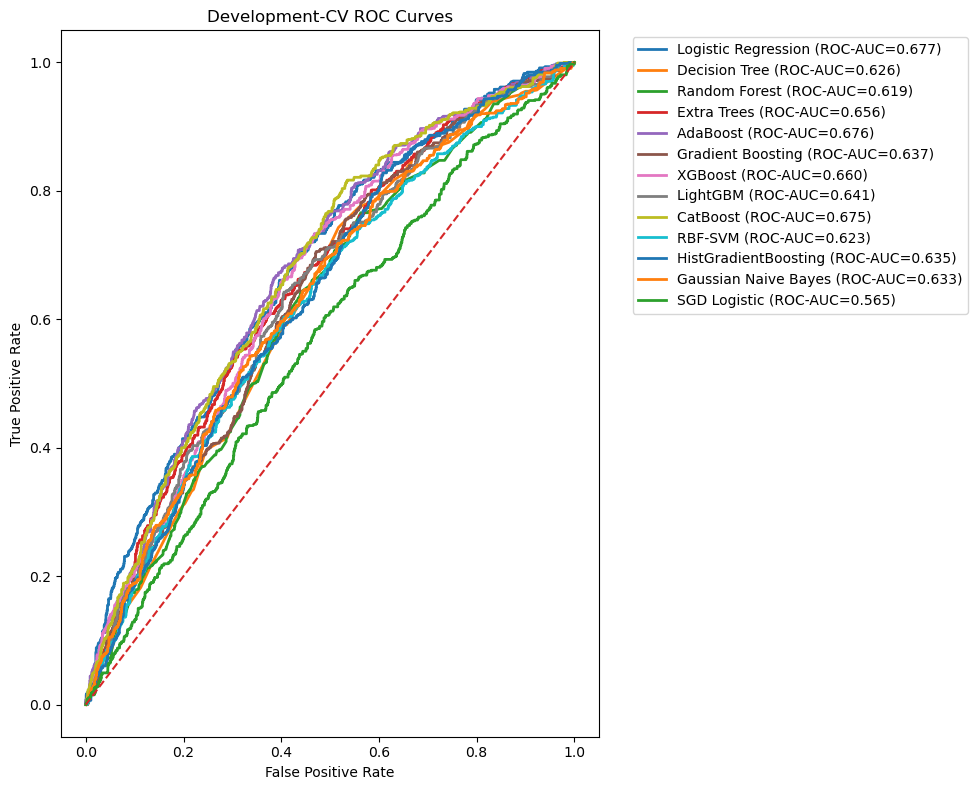


✓ ROC curves are based on PSU-grouped development cross-validation predictions.
✓ Final test data are not used in Step-18.


In [16]:
# ==========================================================
# Step-18 : Development-CV ROC Curves
#           NO FINAL TEST DATA
# ==========================================================

import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    roc_auc_score
)

print("=" * 70)
print("DEVELOPMENT-CV ROC CURVES")
print("=" * 70)


plt.figure(
    figsize=(
        10,
        8
    )
)


for name, probability in default_cv_predictions.items():
    # ------------------------------------------------------
    # Weighted ROC curve
    # ------------------------------------------------------

    fpr, tpr, _ = roc_curve(

        y_train,

        probability,

        sample_weight=
            weights_train
    )


    # ------------------------------------------------------
    # Weighted ROC-AUC
    # ------------------------------------------------------

    roc_auc_value = roc_auc_score(

        y_train,

        probability,

        sample_weight=
            weights_train
    )


    # ------------------------------------------------------
    # Plot
    # ------------------------------------------------------

    plt.plot(

        fpr,

        tpr,

        linewidth=2,

        label=
            f"{name} "
            f"(ROC-AUC={roc_auc_value:.3f})"
    )


# ==========================================================
# Reference diagonal
# ==========================================================

plt.plot(

    [
        0,
        1
    ],

    [
        0,
        1
    ],

    linestyle="--"
)


# ==========================================================
# Figure formatting
# ==========================================================

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "Development-CV ROC Curves"
)

plt.legend(

    bbox_to_anchor=(
        1.05,
        1
    ),

    loc="upper left"
)

plt.tight_layout()

plt.show()


print(
    "\n✓ ROC curves are based on "
    "PSU-grouped development cross-validation predictions."
)

print(
    "✓ Final test data are not used in Step-18."
)

DEVELOPMENT-CV PRECISION-RECALL CURVES


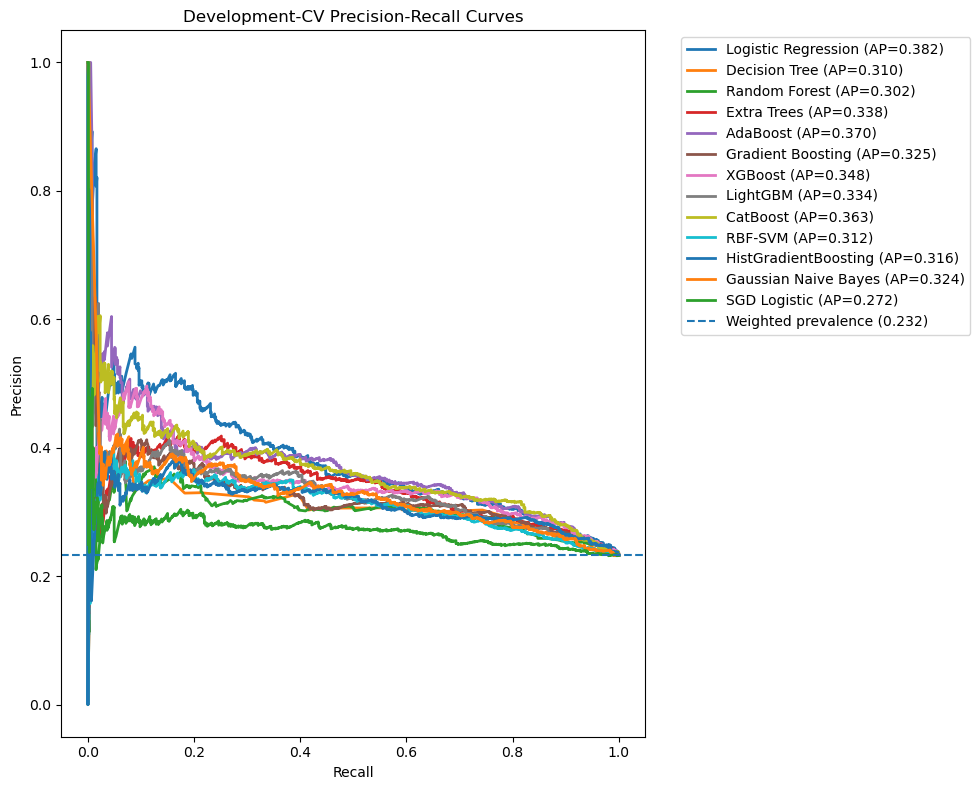


✓ Precision-recall curves are based on PSU-grouped development cross-validation predictions.
✓ Average Precision (AP) is reported.
✓ Final test data are not used in Step-19.


In [17]:
# ==========================================================
# Step-19 : Development-CV Precision-Recall Curves
#           NO FINAL TEST DATA
# ==========================================================

import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

print("=" * 70)
print("DEVELOPMENT-CV PRECISION-RECALL CURVES")
print("=" * 70)


plt.figure(
    figsize=(
        10,
        8
    )
)


for name, probability in default_cv_predictions.items():
    
    # ------------------------------------------------------
    # Weighted Precision-Recall Curve
    # ------------------------------------------------------

    precision, recall, _ = (

        precision_recall_curve(

            y_train,

            probability,

            sample_weight=
                weights_train

        )

    )


    # ------------------------------------------------------
    # Weighted Average Precision
    # ------------------------------------------------------

    ap = average_precision_score(

        y_train,

        probability,

        sample_weight=
            weights_train

    )


    # ------------------------------------------------------
    # Plot
    # ------------------------------------------------------

    plt.plot(

        recall,

        precision,

        linewidth=2,

        label=
            f"{name} "
            f"(AP={ap:.3f})"

    )


# ==========================================================
# Weighted prevalence reference line
# ==========================================================

weighted_prevalence = np.average(

    np.asarray(
        y_train,
        dtype=float
    ),

    weights=
        weights_train

)


plt.axhline(

    weighted_prevalence,

    linestyle="--",

    label=
        f"Weighted prevalence "
        f"({weighted_prevalence:.3f})"

)


# ==========================================================
# Figure formatting
# ==========================================================

plt.xlabel(
    "Recall"
)

plt.ylabel(
    "Precision"
)

plt.title(
    "Development-CV Precision-Recall Curves"
)

plt.legend(

    bbox_to_anchor=(
        1.05,
        1
    ),

    loc="upper left"

)

plt.tight_layout()

plt.show()


print(
    "\n✓ Precision-recall curves are based on "
    "PSU-grouped development cross-validation predictions."
)

print(
    "✓ Average Precision (AP) is reported."
)

print(
    "✓ Final test data are not used in Step-19."
)

In [18]:
# ==========================================================
# Step-20 : Best Model Selection From Development CV Only
#           FIXED MODEL CONFIGURATIONS
#           NO HYPERPARAMETER SEARCH
#           NO CALIBRATION / THRESHOLD / FINAL TEST USE
# ==========================================================

import pandas as pd

print("=" * 70)
print("FINAL MODEL FAMILY LOCKING")
print("=" * 70)


# ==========================================================
# 1. Retain Survey-Weight-Capable Models
# ==========================================================

eligible_ranking_df = (

    default_df[
        default_df[
            "Model"
        ].apply(
            supports_survey_weight
        )
    ]

    .copy()

)


if len(
    eligible_ranking_df
) == 0:

    raise RuntimeError(
        "No survey-weight-capable model is available "
        "for final model selection."
    )


# ==========================================================
# 2. Development-CV Ranking
#
# Keep the CURRENT methodological framework:
# primary ranking = Mean development-CV ROC-AUC
# ==========================================================

ranking_df = (

    eligible_ranking_df

    .sort_values(
        "Mean_Fold_AUC",
        ascending=False
    )

    .reset_index(
        drop=True
    )

)


print(
    "\nDevelopment-CV ranking"
)


display(

    ranking_df[
        [
            "Model",
            "Mean_Fold_AUC",
            "SD_Fold_AUC",
            "Accuracy",
            "Balanced_Accuracy",
            "Precision",
            "Recall",
            "Specificity",
            "F1",
            "Kappa",
            "MCC",
            "AUC",
            "Average_Precision",
            "Brier",
            "LogLoss",
        ]
    ]

    .round(
        4
    )

)


# ==========================================================
# 3. Lock Best Model Family
# ==========================================================

best_model_name = (

    ranking_df.loc[
        0,
        "Model"
    ]

)


best_model_template = (

    models_default[
        best_model_name
    ]

)


best_model_params = (

    best_model_template

    .get_params()

)


print(
    "\nSelected model family:",
    best_model_name
)


print(
    "\nFixed model configuration:"
)


print(
    best_model_params
)


print(
    "\n✓ Model family was locked using "
    "development CV only."
)


print(
    "✓ No hyperparameter-search procedure "
    "is performed in the final pipeline."
)


print(
    "✓ Calibration and threshold selection are NOT "
    "performed in Step-20."
)


print(
    "✓ Final test performance is NOT evaluated "
    "in Step-20."
)

FINAL MODEL FAMILY LOCKING

Development-CV ranking


,Model,Mean_Fold_AUC,SD_Fold_AUC,Accuracy,Balanced_Accuracy,Precision,Recall,Specificity,F1,Kappa,MCC,AUC,Average_Precision,Brier,LogLoss
0,CatBoost,0.6790,0.0321,0.7682,0.5055,0.5425,0.0147,0.9963,0.0286,0.0165,0.0584,0.6749,0.3626,0.1669,0.5086
1,AdaBoost,0.6787,0.0313,0.7687,0.5115,0.5370,0.0310,0.9919,0.0587,0.0342,0.0842,0.6765,0.3702,0.2013,0.5936
2,Logistic Regression,0.6783,0.0175,0.7674,0.5230,0.4957,0.0663,0.9796,0.1170,0.0658,0.1117,0.6766,0.3818,0.1657,0.5061
3,XGBoost,0.6641,0.0268,0.7647,0.5120,0.4320,0.0400,0.9841,0.0732,0.0352,0.0701,0.6605,0.3485,0.1692,0.5149
4,Extra Trees,0.6611,0.0197,0.7635,0.5021,0.3026,0.0136,0.9905,0.0260,0.0062,0.0171,0.6562,0.3378,0.1695,0.5159
5,LightGBM,0.6439,0.0300,0.7508,0.5228,0.3638,0.0969,0.9487,0.1531,0.0613,0.0800,0.6414,0.3337,0.1791,0.5557
6,HistGradientBoosting,0.6412,0.0256,0.7417,0.5270,0.3462,0.1260,0.9280,0.1847,0.0694,0.0819,0.6351,0.3159,0.1901,0.6126
7,Gradient Boosting,0.6390,0.0255,0.7509,0.5310,0.3845,0.1203,0.9417,0.1833,0.0816,0.1009,0.6375,0.3248,0.1778,0.5378
8,RBF-SVM,0.6356,0.0233,0.7633,0.5030,0.3201,0.0167,0.9892,0.0318,0.0089,0.0231,0.6233,0.3121,0.1743,0.5299
9,Gaussian Naive Bayes,0.6336,0.0201,0.6762,0.5710,0.3278,0.3746,0.7675,0.3496,0.1353,0.1359,0.6333,0.3235,0.2590,1.2472



Selected model family: CatBoost

Fixed model configuration:
{'iterations': 200, 'learning_rate': 0.03, 'depth': 4, 'verbose': 0, 'random_state': 42}

✓ Model family was locked using development CV only.
✓ No hyperparameter-search procedure is performed in the final pipeline.
✓ Calibration and threshold selection are NOT performed in Step-20.
✓ Final test performance is NOT evaluated in Step-20.


In [19]:
# ==========================================================
# Step-20B : Separate Calibration / Threshold Development Set
#            + Training-Weight Sensitivity
#            + Final Base-Model Fit
#            + Probability Recalibration
#            + Threshold Locking
#
# NO FINAL TEST PERFORMANCE EVALUATION
# ==========================================================

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    roc_curve,
    roc_auc_score,
    brier_score_loss
)
from sklearn.model_selection import StratifiedGroupKFold


print("=" * 70)
print("SEPARATE CALIBRATION / THRESHOLD DEVELOPMENT")
print("=" * 70)


# ==========================================================
# 1. TRAINING-WEIGHT SENSITIVITY
# ==========================================================

weight_sensitivity_rows = []

weight_sensitivity_cv_predictions = {}


for strategy in WEIGHT_STRATEGIES:

    print(
        "\nEvaluating weighting strategy:",
        strategy
    )


    cv_probabilities = np.full(
        len(y_train),
        np.nan,
        dtype=float
    )


    fold_auc_values = []


    for fold in development_fold_cache:

        model_fold = clone(
            best_model_template
        )


        fold_fit_weights = (
            make_training_fit_weights(

                fold[
                    "y_train"
                ],

                fold[
                    "survey_weight_train"
                ],

                strategy=
                    strategy
            )
        )


        model_fold.fit(

            fold[
                "X_train_scaled"
            ],

            fold[
                "y_train"
            ],

            sample_weight=
                fold_fit_weights
        )


        probability_valid = (

            model_fold

            .predict_proba(

                fold[
                    "X_valid_scaled"
                ]

            )[:, 1]
        )


        local_valid_idx = (

            fold[
                "local_valid_idx"
            ]
        )


        cv_probabilities[
            local_valid_idx
        ] = probability_valid


        fold_auc_values.append(

            roc_auc_score(

                fold[
                    "y_valid"
                ],

                probability_valid,

                sample_weight=
                    fold[
                        "survey_weight_valid"
                    ]
            )
        )


    if np.isnan(
        cv_probabilities
    ).any():

        raise RuntimeError(

            "Missing development-CV probabilities "
            f"for weighting strategy: {strategy}"
        )


    cv_predictions = (

        cv_probabilities
        >=
        0.50

    ).astype(int)


    metrics = weighted_binary_metrics(

        y_true=
            y_train,

        pred=
            cv_predictions,

        prob=
            cv_probabilities,

        sample_weight=
            weights_train
    )


    weight_sensitivity_cv_predictions[
        strategy
    ] = cv_probabilities.copy()


    weight_sensitivity_rows.append({

        "Strategy":
            strategy,

        "Mean_CV_AUC":
            float(
                np.mean(
                    fold_auc_values
                )
            ),

        "SD_CV_AUC":
            float(
                np.std(
                    fold_auc_values,
                    ddof=1
                )
            ),

        "AUC":
            metrics[
                "AUC"
            ],

        "Average_Precision":
            metrics[
                "Average_Precision"
            ],

        "Brier":
            metrics[
                "Brier"
            ],

        "LogLoss":
            metrics[
                "LogLoss"
            ]
    })


weight_sensitivity_df = pd.DataFrame(
    weight_sensitivity_rows
)


print(
    "\nTraining-weight sensitivity"
)


display(

    weight_sensitivity_df[
        [
            "Strategy",
            "Mean_CV_AUC",
            "SD_CV_AUC",
            "AUC",
            "Average_Precision",
            "Brier",
            "LogLoss"
        ]
    ]

    .round(4)
)


# ==========================================================
# 2. LOCK PRIMARY TRAINING-WEIGHT STRATEGY
# ==========================================================

best_weight_strategy = (
    "SurveyWeightOnly"
)


print(
    "\nLocked training-weight strategy:",
    best_weight_strategy
)


# ==========================================================
# 3. FINAL PREPROCESSING
#    FIT USING DEVELOPMENT DATA ONLY
# ==========================================================

calibration_prepared = prepare_spatial_fold(

    global_train_indices=
        np.asarray(
            train_idx,
            dtype=int
        ),

    global_valid_indices=
        np.asarray(
            calibration_idx,
            dtype=int
        ),

    random_state=4242
)


final_test_prepared = prepare_spatial_fold(

    global_train_indices=
        np.asarray(
            train_idx,
            dtype=int
        ),

    global_valid_indices=
        np.asarray(
            test_idx,
            dtype=int
        ),

    random_state=4242
)


if (
    calibration_prepared[
        "model_features"
    ]
    !=
    final_test_prepared[
        "model_features"
    ]
):

    raise RuntimeError(
        "Calibration and final-test preprocessing "
        "produced different feature sets despite "
        "identical training data."
    )


if (
    calibration_prepared[
        "encoded_names"
    ]
    !=
    final_test_prepared[
        "encoded_names"
    ]
):

    raise RuntimeError(
        "Calibration and final-test preprocessing "
        "produced different encoded columns."
    )


# ==========================================================
# 4. FINAL PREPROCESSING OBJECTS
# ==========================================================

selected_vars = (
    final_test_prepared[
        "selected_vars"
    ]
)


model_features = (
    final_test_prepared[
        "model_features"
    ]
)


gb_df = (
    final_test_prepared[
        "importance_df"
    ].copy()
)


onehot_encoder = (
    final_test_prepared[
        "encoder"
    ]
)


encoded_nominal_columns = (
    final_test_prepared[
        "encoded_names"
    ]
)


socio_vars = (
    final_test_prepared[
        "socio_feature_names"
    ]
)


scaler = (
    final_test_prepared[
        "scaler"
    ]
)


# ==========================================================
# 5. DEVELOPMENT MATRICES
# ==========================================================

X_train_raw = (
    final_test_prepared[
        "X_train_raw"
    ].copy()
)


X_train = (
    final_test_prepared[
        "X_train_scaled"
    ]
)


y_train = pd.Series(

    final_test_prepared[
        "y_train"
    ],

    name=target
)


weights_train = np.asarray(

    final_test_prepared[
        "survey_weight_train"
    ],

    dtype=float
)


groups_train = np.asarray(

    final_test_prepared[
        "groups_train"
    ]
)


strata_train = np.asarray(

    final_test_prepared[
        "strata_train"
    ]
)


spatial_clusters_train = np.asarray(

    final_test_prepared[
        "spatial_clusters_train"
    ]
)


# ==========================================================
# 6. RESERVED CALIBRATION MATRICES
# ==========================================================

X_calibration_raw = (
    calibration_prepared[
        "X_valid_raw"
    ].copy()
)


X_calibration = (
    calibration_prepared[
        "X_valid_scaled"
    ]
)


y_calibration = pd.Series(

    calibration_prepared[
        "y_valid"
    ],

    name=target
)


weights_calibration = np.asarray(

    calibration_prepared[
        "survey_weight_valid"
    ],

    dtype=float
)


groups_calibration = np.asarray(

    calibration_prepared[
        "groups_valid"
    ]
)


strata_calibration = np.asarray(

    calibration_prepared[
        "strata_valid"
    ]
)


spatial_clusters_calibration = np.asarray(

    calibration_prepared[
        "spatial_clusters_valid"
    ]
)


# ==========================================================
# 7. FINAL-TEST MATRICES
# ==========================================================

X_test_raw = (
    final_test_prepared[
        "X_valid_raw"
    ].copy()
)


X_test = (
    final_test_prepared[
        "X_valid_scaled"
    ]
)


y_test = pd.Series(

    final_test_prepared[
        "y_valid"
    ],

    name=target
)


weights_test = np.asarray(

    final_test_prepared[
        "survey_weight_valid"
    ],

    dtype=float
)


groups_test = np.asarray(

    final_test_prepared[
        "groups_valid"
    ]
)


strata_test = np.asarray(

    final_test_prepared[
        "strata_valid"
    ]
)


spatial_clusters_test = np.asarray(

    final_test_prepared[
        "spatial_clusters_valid"
    ]
)


# ==========================================================
# 8. COORDINATES
# ==========================================================

coords_train = (

    df.iloc[
        np.asarray(
            train_idx,
            dtype=int
        )
    ][
        ["lon", "lat"]
    ]

    .to_numpy(
        dtype=float
    )
)


coords_calibration = (

    df.iloc[
        np.asarray(
            calibration_idx,
            dtype=int
        )
    ][
        ["lon", "lat"]
    ]

    .to_numpy(
        dtype=float
    )
)


coords_test = (

    df.iloc[
        np.asarray(
            test_idx,
            dtype=int
        )
    ][
        ["lon", "lat"]
    ]

    .to_numpy(
        dtype=float
    )
)


# ==========================================================
# 9. FINAL PREDICTOR-DEFINITION TABLE
# ==========================================================

final_predictor_definition_df = (
    predictor_definition_df.copy()
)


final_predictor_definition_df[
    "Reference_Group"
] = final_predictor_definition_df.apply(

    lambda row:

        (
            "No dropped reference "
            "(full one-hot encoding)"

            if row["Type"]
            !=
            "Continuous/count"

            else
            "Not applicable"
        ),

    axis=1
)


print(
    "\nFinal predictor-definition table"
)


display(
    final_predictor_definition_df
)


print(
    "\nFinal selected predictors:",
    len(
        model_features
    )
)


for index, feature in enumerate(
    model_features,
    start=1
):

    print(
        f"{index:02d}. {feature}"
    )


# ==========================================================
# 10. FIT FINAL BASE MODEL
#     DEVELOPMENT DATA ONLY
# ==========================================================

final_fit_weights = (

    make_training_fit_weights(

        y_train,

        weights_train,

        strategy=
            best_weight_strategy
    )
)


combined_train_weights = (
    final_fit_weights.copy()
)


final_model = clone(
    best_model_template
)


final_model.fit(

    X_train,

    y_train,

    sample_weight=
        final_fit_weights
)


# ==========================================================
# 11. PROBABILITY CALIBRATION
#
# Same overall framework:
#
# Development
#      ↓
# Reserved Calibration
#      ↓
# Final Test
#
# Inside the RESERVED calibration sample,
# PSU-grouped cross-fitting is used only to obtain
# out-of-fold calibrated probabilities for
# threshold development.
# ==========================================================

EPS = 1e-6


def probability_to_logit(
    probability
):

    probability = np.clip(

        np.asarray(
            probability,
            dtype=float
        ),

        EPS,

        1 - EPS
    )


    return np.log(

        probability

        /

        (
            1
            -
            probability
        )
    )


# ----------------------------------------------------------
# Raw probabilities on reserved calibration subset
# ----------------------------------------------------------

calibration_probability_raw = (

    final_model

    .predict_proba(
        X_calibration
    )[:, 1]
)


calibration_y_array = np.asarray(
    y_calibration,
    dtype=int
)


calibration_weight_array = np.asarray(
    weights_calibration,
    dtype=float
)


calibration_group_array = np.asarray(
    groups_calibration
)


# ----------------------------------------------------------
# PSU-grouped cross-fitted calibration probabilities
# ----------------------------------------------------------

N_CALIBRATION_FOLDS = 5


if (
    len(
        np.unique(
            calibration_group_array
        )
    )
    <
    N_CALIBRATION_FOLDS
):

    raise RuntimeError(
        "Not enough calibration PSUs for "
        "the requested cross-fitted "
        "calibration folds."
    )


calibration_cv = StratifiedGroupKFold(

    n_splits=
        N_CALIBRATION_FOLDS,

    shuffle=True,

    random_state=4242
)


calibration_probability_oof = np.full(

    len(
        calibration_y_array
    ),

    np.nan,

    dtype=float
)


for calibration_fold_no, (

    calibration_fit_local_idx,
    calibration_valid_local_idx

) in enumerate(

    calibration_cv.split(

        np.zeros(
            len(
                calibration_y_array
            )
        ),

        calibration_y_array,

        groups=
            calibration_group_array
    ),

    start=1
):


    calibration_fit_local_idx = np.asarray(
        calibration_fit_local_idx,
        dtype=int
    )


    calibration_valid_local_idx = np.asarray(
        calibration_valid_local_idx,
        dtype=int
    )


    shared_calibration_psu = np.intersect1d(

        calibration_group_array[
            calibration_fit_local_idx
        ],

        calibration_group_array[
            calibration_valid_local_idx
        ]
    )


    if len(
        shared_calibration_psu
    ) != 0:

        raise RuntimeError(

            "PSU leakage detected inside "
            "calibration cross-fit fold "

            f"{calibration_fold_no}."
        )


    if np.unique(

        calibration_y_array[
            calibration_fit_local_idx
        ]

    ).size < 2:

        raise RuntimeError(
            "A calibration-training fold "
            "contains only one outcome class."
        )


    fold_calibrator = LogisticRegression(

        C=1e6,

        solver="lbfgs",

        max_iter=2000,

        random_state=42
    )


    fold_calibrator.fit(

        probability_to_logit(

            calibration_probability_raw[
                calibration_fit_local_idx
            ]

        ).reshape(
            -1,
            1
        ),

        calibration_y_array[
            calibration_fit_local_idx
        ],

        sample_weight=
            calibration_weight_array[
                calibration_fit_local_idx
            ]
    )


    calibration_probability_oof[
        calibration_valid_local_idx
    ] = (

        fold_calibrator

        .predict_proba(

            probability_to_logit(

                calibration_probability_raw[
                    calibration_valid_local_idx
                ]

            ).reshape(
                -1,
                1
            )

        )[:, 1]
    )


if np.isnan(
    calibration_probability_oof
).any():

    raise RuntimeError(
        "Missing cross-fitted calibrated probabilities."
    )


# ==========================================================
# 12. CROSS-FITTED BRIER ASSESSMENT
# ==========================================================

raw_brier = brier_score_loss(

    calibration_y_array,

    calibration_probability_raw,

    sample_weight=
        calibration_weight_array
)


calibrated_brier = brier_score_loss(

    calibration_y_array,

    calibration_probability_oof,

    sample_weight=
        calibration_weight_array
)


print(
    "\nCalibration-subset raw Brier:",
    round(
        raw_brier,
        4
    )
)


print(
    "Cross-fitted calibrated Brier:",
    round(
        calibrated_brier,
        4
    )
)


print(
    "Calibration folds:",
    N_CALIBRATION_FOLDS
)


print(
    "✓ Cross-fitted calibration predictions "
    "are PSU-disjoint."
)


# ==========================================================
# 13. MCC-OPTIMAL THRESHOLD
#     RESERVED CALIBRATION DATA ONLY
# ==========================================================

(
    fpr_cal,
    tpr_cal,
    candidate_thresholds

) = roc_curve(

    calibration_y_array,

    calibration_probability_oof,

    sample_weight=
        calibration_weight_array
)


valid_threshold_mask = (

    np.isfinite(
        candidate_thresholds
    )

    &

    (
        candidate_thresholds
        >=
        0
    )

    &

    (
        candidate_thresholds
        <=
        1
    )
)


candidate_thresholds = (

    candidate_thresholds[
        valid_threshold_mask
    ]
)


if len(
    candidate_thresholds
) == 0:

    raise RuntimeError(
        "No valid threshold found on "
        "the reserved calibration subset."
    )


threshold_results = []


for threshold_value in candidate_thresholds:

    calibration_prediction = (

        calibration_probability_oof

        >=

        threshold_value

    ).astype(int)


    weighted_cm = confusion_matrix(

        calibration_y_array,

        calibration_prediction,

        labels=[0, 1],

        sample_weight=
            calibration_weight_array
    )


    tn, fp, fn, tp = (
        weighted_cm.ravel()
    )


    mcc_denominator = np.sqrt(

        (tp + fp)

        *

        (tp + fn)

        *

        (tn + fp)

        *

        (tn + fn)
    )


    if mcc_denominator > 0:

        weighted_mcc = (

            (
                tp * tn
            )

            -

            (
                fp * fn
            )

        ) / mcc_denominator

    else:

        weighted_mcc = np.nan


    sensitivity = (

        tp / (tp + fn)

        if (tp + fn) > 0

        else np.nan
    )


    specificity = (

        tn / (tn + fp)

        if (tn + fp) > 0

        else np.nan
    )


    balanced_accuracy = (

        sensitivity

        +

        specificity

    ) / 2


    threshold_results.append({

        "Threshold":
            float(
                threshold_value
            ),

        "MCC":
            float(
                weighted_mcc
            ),

        "Sensitivity":
            float(
                sensitivity
            ),

        "Specificity":
            float(
                specificity
            ),

        "Balanced_Accuracy":
            float(
                balanced_accuracy
            )
    })


mcc_threshold_df = pd.DataFrame(
    threshold_results
)


mcc_threshold_df = (

    mcc_threshold_df

    .dropna(
        subset=[
            "MCC"
        ]
    )

    .reset_index(
        drop=True
    )
)


if len(
    mcc_threshold_df
) == 0:

    raise RuntimeError(
        "MCC could not be calculated for "
        "any calibration threshold."
    )


best_threshold_row = (

    mcc_threshold_df.loc[

        mcc_threshold_df[
            "MCC"
        ].idxmax()

    ]
)


final_threshold = float(

    best_threshold_row[
        "Threshold"
    ]
)


print(
    "\nLocked MCC-optimal threshold:",
    round(
        final_threshold,
        4
    )
)


print(
    "Cross-fitted calibration weighted MCC:",
    round(
        best_threshold_row[
            "MCC"
        ],
        4
    )
)


print(
    "Calibration sensitivity:",
    round(
        best_threshold_row[
            "Sensitivity"
        ],
        4
    )
)


print(
    "Calibration specificity:",
    round(
        best_threshold_row[
            "Specificity"
        ],
        4
    )
)


print(
    "Calibration balanced accuracy:",
    round(
        best_threshold_row[
            "Balanced_Accuracy"
        ],
        4
    )
)


# ==========================================================
# 14. REFIT FINAL CALIBRATOR USING ENTIRE
#     RESERVED CALIBRATION SUBSET
# ==========================================================

probability_calibrator = LogisticRegression(

    C=1e6,

    solver="lbfgs",

    max_iter=2000,

    random_state=42
)


probability_calibrator.fit(

    probability_to_logit(

        calibration_probability_raw

    ).reshape(
        -1,
        1
    ),

    calibration_y_array,

    sample_weight=
        calibration_weight_array
)


def apply_probability_calibration(
    raw_probability
):

    calibration_input = (

        probability_to_logit(
            raw_probability
        )

        .reshape(
            -1,
            1
        )
    )


    return (

        probability_calibrator

        .predict_proba(
            calibration_input
        )[:, 1]
    )


calibration_probability = (

    apply_probability_calibration(
        calibration_probability_raw
    )
)


# ==========================================================
# 15. AUDIT
# ==========================================================

print(
    "\nFinal base model fitted:",
    best_model_name
)


print(
    "Final weighting strategy:",
    best_weight_strategy
)


print(
    "✓ Development / calibration / final-test "
    "framework is unchanged."
)


print(
    "✓ The calibration subset was reserved before "
    "model tuning and model selection."
)


print(
    "✓ Calibration probabilities used for threshold "
    "selection were generated out-of-fold with "
    "PSU-grouped cross-fitting."
)


print(
    "✓ Final probability calibrator was refitted on "
    "the entire reserved calibration subset only "
    "after the cross-fitted threshold was locked."
)


print(
    "✓ Final test outcomes were not used for model "
    "fitting, feature selection, calibration, "
    "or threshold selection."
)

SEPARATE CALIBRATION / THRESHOLD DEVELOPMENT

Evaluating weighting strategy: SurveyWeightOnly

Evaluating weighting strategy: SurveyWeight_ClassBalanced

Training-weight sensitivity


,Strategy,Mean_CV_AUC,SD_CV_AUC,AUC,Average_Precision,Brier,LogLoss
0,SurveyWeightOnly,0.6790,0.0321,0.6749,0.3626,0.1669,0.5086
1,SurveyWeight_ClassBalanced,0.6766,0.0364,0.6749,0.3647,0.2115,0.6093



Locked training-weight strategy: SurveyWeightOnly

Final predictor-definition table


,Variable,Type,Coding,Reference_Group,Modelling_Treatment
0,Age_,Ordinal categorical,1.0=15-19; 2.0=20-24; 3.0=25-29; 4.0=30-34; 5....,No dropped reference (full one-hot encoding),One-hot encoding
1,Division,Nominal categorical,1.0=Dhaka; 2.0=Chittagong; 3.0=Rajshahi; 4.0=K...,No dropped reference (full one-hot encoding),One-hot encoding
2,Residence,Binary categorical,1.0=Urban; 2.0=Rural,No dropped reference (full one-hot encoding),One-hot encoding
3,Mother_education,Ordinal categorical,0.0=No education; 1.0=Primary; 2.0=Secondary; ...,No dropped reference (full one-hot encoding),One-hot encoding
4,Water_source,Binary categorical,0.0=Unimproved; 1.0=Improved,No dropped reference (full one-hot encoding),One-hot encoding
5,Toilet_facility,Binary categorical,0.0=Unhygienic; 1.0=Hygienic,No dropped reference (full one-hot encoding),One-hot encoding
6,Religion,Nominal categorical,1.0=Muslim; 2.0=Hindu; 3.0=Others,No dropped reference (full one-hot encoding),One-hot encoding
7,Relationship_to_household_head,Nominal categorical,1.0=Husband/Wife; 2.0=Others family member; 3....,No dropped reference (full one-hot encoding),One-hot encoding
8,Wealth,Ordinal categorical,1.0=Poorest; 2.0=Poorer; 3.0=Middle; 4.0=Riche...,No dropped reference (full one-hot encoding),One-hot encoding
9,Contraception,Nominal categorical,1.0=Mother; 2.0=Husband; 3.0=Joint; 4.0=Others,No dropped reference (full one-hot encoding),One-hot encoding



Final selected predictors: 55
01. Maternal_Height
02. lst_celsius
03. slope_degrees
04. Wealth_1.0
05. wx_pdsi_drought_index
06. BMI
07. wx_pop_density
08. wx_slope_degrees
09. wx_lst_celsius
10. pop_density
11. wx_soil_moisture
12. wx_flood_occurrence_pct
13. wx_relative_humidity_pct
14. rainfall_mm_yr
15. elevation_m
16. wx_rainfall_mm_yr
17. flood_occurrence_pct
18. soil_moisture
19. Father_education_3.0
20. relative_humidity_pct
21. ndvi
22. Mother_education_0.0
23. wx_temperature_celsius
24. wx_ndvi
25. wx_pet_mm
26. Relationship_to_household_head_1.0
27. wx_climatic_water_deficit_mm
28. Wealth_5.0
29. wx_elevation_m
30. Fever_1.0
31. Age__1.0
32. Twin_child_1.0
33. climatic_water_deficit_mm
34. Child_sex_1.0
35. pdsi_drought_index
36. Mother_education_1.0
37. Who_make_decision_about_health_4.0
38. Relationship_to_household_head_2.0
39. Wealth_4.0
40. Father_education_1.0
41. Contraception_4.0
42. Mother_Working_1.0
43. Cough_0.0
44. Wealth_2.0
45. pet_mm
46. temperature_celsius


In [20]:
# ==========================================================
# Step-20C : FIRST MODEL-PERFORMANCE EVALUATION
#            ON THE FINAL TEST SET
#            Calibrated Probability
#            + Stratified PSU Bootstrap ROC-AUC CI
# ==========================================================

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
)

print("=" * 70)
print("FIRST MODEL-PERFORMANCE EVALUATION ON THE FINAL TEST SET")
print("=" * 70)

# ==========================================================
# 1. Raw Probability From Locked Final Base Model
# ==========================================================

y_prob_raw = (
    final_model
    .predict_proba(
        X_test
    )[:, 1]
)

# ==========================================================
# 2. Apply Probability Calibration Learned From
#    Separate Calibration / Threshold Subset
# ==========================================================

y_prob = (
    apply_probability_calibration(
        y_prob_raw
    )
)

# ==========================================================
# 3. Final Test ROC-AUC
# ==========================================================

final_test_auc = roc_auc_score(
    y_test,
    y_prob,
    sample_weight=
        weights_test
)

# ==========================================================
# 4. Final Test Average Precision
# ==========================================================

final_test_ap = average_precision_score(
    y_test,
    y_prob,
    sample_weight=
        weights_test
)

# ==========================================================
# 5. Final Test Brier Score
# ==========================================================

final_test_brier = brier_score_loss(
    y_test,
    y_prob,
    sample_weight=
        weights_test
)

# ==========================================================
# 6. Strata-Aware PSU Bootstrap 95% CI
# ==========================================================

(
    final_auc_ci_lower,
    final_auc_ci_upper
) = stratified_psu_bootstrap_auc_ci(
    y_true=
        y_test,
    y_prob=
        y_prob,
    psu=
        groups_test,
    strata=
        strata_test,
    sample_weight=
        weights_test,
    n_bootstrap=
        1000,
    random_state=
        42
)

# ==========================================================
# 7. Results
# ==========================================================

print(
    "Final weighted ROC-AUC:",
    round(
        final_test_auc,
        4
    )
)

print(
    "95% PSU-bootstrap ROC-AUC CI:",
    f"{final_auc_ci_lower:.4f}–"
    f"{final_auc_ci_upper:.4f}"
)

print(
    "Final weighted Average Precision (AP):",
    round(
        final_test_ap,
        4
    )
)

print(
    "Final weighted Brier:",
    round(
        final_test_brier,
        4
    )
)

# ==========================================================
# 8. Audit
# ==========================================================

print(
    "\n✓ This is the first model-performance evaluation "
    "on the final test set."
)

print(
    "✓ Probability calibration and threshold selection "
    "were completed using the separate calibration subset."
)

print(
    "✓ ROC-AUC 95% CI was estimated using "
    "strata-aware PSU bootstrap."
)

FIRST MODEL-PERFORMANCE EVALUATION ON THE FINAL TEST SET
Final weighted ROC-AUC: 0.6634
95% PSU-bootstrap ROC-AUC CI: 0.6161–0.7056
Final weighted Average Precision (AP): 0.3636
Final weighted Brier: 0.1627

✓ This is the first model-performance evaluation on the final test set.
✓ Probability calibration and threshold selection were completed using the separate calibration subset.
✓ ROC-AUC 95% CI was estimated using strata-aware PSU bootstrap.


In [21]:
# ==========================================================
# Step-21 : Final Calibrated Test Prediction
#           + Calibration Assessment
# ==========================================================

import numpy as np
import pandas as pd
import statsmodels.api as sm

print("=" * 70)
print("FINAL TEST PREDICTION")
print("=" * 70)


# ==========================================================
# 1. Apply Locked Calibration-Subset Threshold
# ==========================================================

y_pred = (

    y_prob

    >=

    final_threshold

).astype(int)


# ==========================================================
# 2. Weighted Final Test Performance
# ==========================================================

final_test_metrics = weighted_binary_metrics(

    y_true=
        y_test,

    pred=
        y_pred,

    prob=
        y_prob,

    sample_weight=
        weights_test
)


# ==========================================================
# 3. Calibration Assessment
#
# Final test data are used here for assessment only.
# These calibration statistics are not used to refit
# or modify the final model.
# ==========================================================

prob_safe = np.clip(

    np.asarray(
        y_prob,
        dtype=float
    ),

    1e-6,

    1 - 1e-6
)


logit_prob = np.log(

    prob_safe

    /

    (
        1
        -
        prob_safe
    )
)


X_cal_test = sm.add_constant(
    logit_prob
)


calibration_assessment = sm.GLM(

    np.asarray(
        y_test,
        dtype=float
    ),

    X_cal_test,

    family=
        sm.families.Binomial(),

    freq_weights=
        np.asarray(
            weights_test,
            dtype=float
        )

).fit()


calibration_intercept_test = float(

    calibration_assessment.params[
        0
    ]
)


calibration_slope_test = float(

    calibration_assessment.params[
        1
    ]
)


# ==========================================================
# 4. Final Test Results Table
# ==========================================================

final_test_metrics_df = pd.DataFrame([

    {

        "Model":
            best_model_name,

        "Threshold":
            final_threshold,

        "Accuracy":
            final_test_metrics[
                "Accuracy"
            ],

        "Balanced_Accuracy":
            final_test_metrics[
                "Balanced_Accuracy"
            ],

        "Precision":
            final_test_metrics[
                "Precision"
            ],

        "Recall":
            final_test_metrics[
                "Recall"
            ],

        "Specificity":
            final_test_metrics[
                "Specificity"
            ],

        "F1":
            final_test_metrics[
                "F1"
            ],

        "Kappa":
            final_test_metrics[
                "Kappa"
            ],

        "MCC":
            final_test_metrics[
                "MCC"
            ],

        "AUC":
            final_test_metrics[
                "AUC"
            ],

        "AUC_CI_Lower":
            final_auc_ci_lower,

        "AUC_CI_Upper":
            final_auc_ci_upper,

        "Average_Precision":
            final_test_metrics[
                "Average_Precision"
            ],

        "Brier":
            final_test_metrics[
                "Brier"
            ],

        "LogLoss":
            final_test_metrics[
                "LogLoss"
            ],

        "Calibration_Intercept":
            calibration_intercept_test,

        "Calibration_Slope":
            calibration_slope_test
    }
])


# ==========================================================
# 5. Display Final Results
# ==========================================================

print(
    "Selected model:",
    best_model_name
)


print(
    "Locked threshold:",
    round(
        final_threshold,
        4
    )
)


print(
    "Calibration intercept:",
    round(
        calibration_intercept_test,
        4
    )
)


print(
    "Calibration slope:",
    round(
        calibration_slope_test,
        4
    )
)


print(
    "\nFINAL TEST METRICS"
)


display(

    final_test_metrics_df

    .round(
        4
    )
)


# ==========================================================
# 6. Audit
# ==========================================================

print(
    "\n✓ Locked threshold was determined from the "
    "separate calibration/threshold subset only."
)

print(
    "✓ Test calibration intercept and slope "
    "are assessment statistics only."
)

print(
    "✓ Final test data are not used "
    "to refit or modify the final model."
)

FINAL TEST PREDICTION
Selected model: CatBoost
Locked threshold: 0.2541
Calibration intercept: 0.0621
Calibration slope: 0.9976

FINAL TEST METRICS


,Model,Threshold,Accuracy,Balanced_Accuracy,Precision,Recall,Specificity,F1,Kappa,MCC,AUC,AUC_CI_Lower,AUC_CI_Upper,Average_Precision,Brier,LogLoss,Calibration_Intercept,Calibration_Slope
0,CatBoost,0.2541,0.6879,0.6069,0.3478,0.4611,0.7528,0.3965,0.1916,0.1951,0.6634,0.6161,0.7056,0.3636,0.1627,0.5011,0.0621,0.9976



✓ Locked threshold was determined from the separate calibration/threshold subset only.
✓ Test calibration intercept and slope are assessment statistics only.
✓ Final test data are not used to refit or modify the final model.


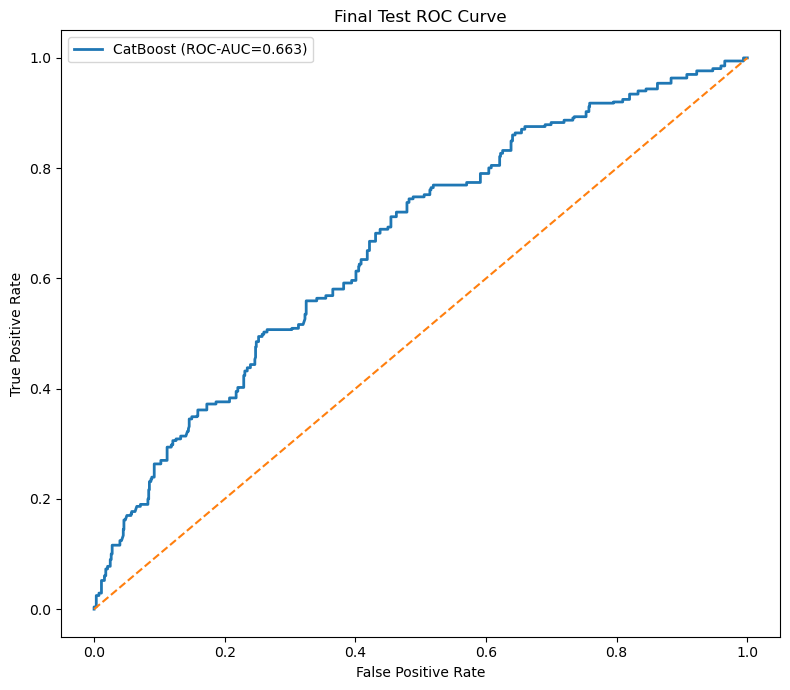

In [22]:
# ==========================================================
# Step-21A : Final Test ROC Curve
# ==========================================================

import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    roc_auc_score
)

fpr_test, tpr_test, _ = roc_curve(

    y_test,

    y_prob,

    sample_weight=
        weights_test
)

roc_auc_test = roc_auc_score(

    y_test,

    y_prob,

    sample_weight=
        weights_test
)

plt.figure(
    figsize=(
        8,
        7
    )
)

plt.plot(

    fpr_test,

    tpr_test,

    linewidth=2,

    label=
        f"{best_model_name} "
        f"(ROC-AUC={roc_auc_test:.3f})"
)

plt.plot(
    [
        0,
        1
    ],
    [
        0,
        1
    ],
    linestyle="--"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "Final Test ROC Curve"
)

plt.legend()

plt.tight_layout()

plt.show()

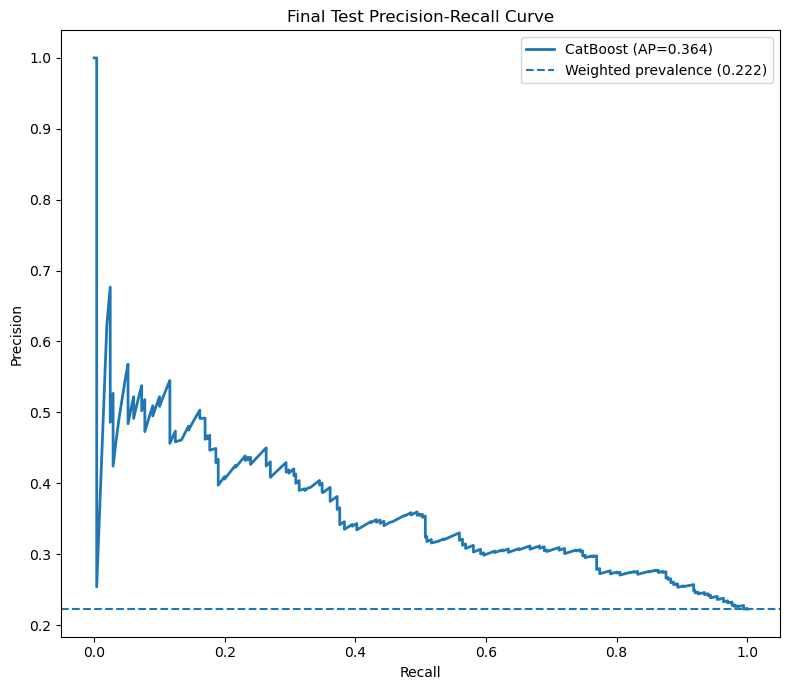

In [23]:
# ==========================================================
# Step-21B : FINAL TEST PRECISION-RECALL CURVE
# ==========================================================

import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

precision_test, recall_test, _ = (

    precision_recall_curve(

        y_test,

        y_prob,

        sample_weight=
            weights_test

    )

)

ap_test = average_precision_score(

    y_test,

    y_prob,

    sample_weight=
        weights_test

)

weighted_test_prevalence = np.average(

    np.asarray(
        y_test,
        dtype=float
    ),

    weights=
        weights_test

)

plt.figure(
    figsize=(
        8,
        7
    )
)

plt.plot(

    recall_test,

    precision_test,

    linewidth=2,

    label=
        f"{best_model_name} "
        f"(AP={ap_test:.3f})"

)

plt.axhline(

    weighted_test_prevalence,

    linestyle="--",

    label=
        f"Weighted prevalence "
        f"({weighted_test_prevalence:.3f})"

)

plt.xlabel(
    "Recall"
)

plt.ylabel(
    "Precision"
)

plt.title(
    "Final Test Precision-Recall Curve"
)

plt.legend()

plt.tight_layout()

plt.show()

In [24]:
# ==========================================================
# Step-21D : Descriptive Residual
#            Spatial-Autocorrelation Diagnostic
# ==========================================================

import numpy as np
import pandas as pd

from libpysal.weights import W
from esda.moran import Moran
from sklearn.neighbors import BallTree


print("=" * 70)
print(
    "DESCRIPTIVE RESIDUAL "
    "SPATIAL-AUTOCORRELATION DIAGNOSTIC"
)
print("=" * 70)


# ==========================================================
# 1. PREDICTION RESIDUALS
# ==========================================================

residuals = (

    np.asarray(
        y_test,
        dtype=float
    )

    -

    np.asarray(
        y_prob,
        dtype=float
    )
)


# ==========================================================
# 2. CHILD-LEVEL TABLE
# ==========================================================

residual_df = pd.DataFrame({

    "dhsclust":
        spatial_clusters_test,

    "lon":
        coords_test[:, 0],

    "lat":
        coords_test[:, 1],

    "residual":
        residuals,

    "survey_weight":
        weights_test
})


# ==========================================================
# 3. SURVEY-WEIGHTED CLUSTER RESIDUAL
# ==========================================================

cluster_rows = []


for cluster_id, group in residual_df.groupby(
    "dhsclust",
    sort=False
):

    residual_values = (
        group[
            "residual"
        ]
        .to_numpy(
            dtype=float
        )
    )


    weight_values = (
        group[
            "survey_weight"
        ]
        .to_numpy(
            dtype=float
        )
    )


    valid_weight_mask = (

        np.isfinite(
            weight_values
        )

        &

        (
            weight_values > 0
        )

        &

        np.isfinite(
            residual_values
        )
    )


    if not np.any(
        valid_weight_mask
    ):

        raise RuntimeError(

            "No valid residual/weight values "
            f"for DHS cluster {cluster_id}."
        )


    group_residual = (

        residual_values[
            valid_weight_mask
        ]
    )


    group_weight = (

        weight_values[
            valid_weight_mask
        ]
    )


    cluster_rows.append({

        "dhsclust":
            cluster_id,

        "lon":
            float(
                group[
                    "lon"
                ].iloc[0]
            ),

        "lat":
            float(
                group[
                    "lat"
                ].iloc[0]
            ),

        "residual":
            float(
                np.average(
                    group_residual,
                    weights=
                        group_weight
                )
            )
    })


cluster_residual = pd.DataFrame(
    cluster_rows
)


# ==========================================================
# 4. HAVERSINE KNN
#
# Same K_NEIGHBORS framework.
# Self-neighbour is explicitly removed by ROW INDEX.
# ==========================================================

if len(
    cluster_residual
) <= K_NEIGHBORS:

    raise RuntimeError(
        "Not enough test DHS clusters for "
        "the requested residual KNN diagnostic."
    )


coords_rad = np.radians(

    cluster_residual[
        [
            "lat",
            "lon"
        ]
    ]

    .to_numpy(
        dtype=float
    )
)


tree = BallTree(
    coords_rad,
    metric="haversine"
)


neighbor_candidates = tree.query(

    coords_rad,

    k=
        K_NEIGHBORS
        +
        1,

    return_distance=False
)


neighbor_idx = []


for row_i, candidate_idx in enumerate(
    neighbor_candidates
):

    valid_neighbors = [

        int(j)

        for j
        in candidate_idx

        if int(j)
        !=
        row_i
    ]


    if len(
        valid_neighbors
    ) < K_NEIGHBORS:

        raise RuntimeError(

            "Unable to identify enough "
            "non-self neighbours for "
            "residual Moran diagnostic."
        )


    neighbor_idx.append(

        valid_neighbors[
            :K_NEIGHBORS
        ]
    )


neighbor_idx = np.asarray(
    neighbor_idx,
    dtype=int
)


neighbors = {

    i:
        neighbor_idx[
            i
        ].tolist()

    for i
    in range(
        len(
            cluster_residual
        )
    )
}


moran_weights_dict = {

    i:
        [
            1.0
        ]
        *
        len(
            neighbors[
                i
            ]
        )

    for i
    in neighbors
}


w_residual = W(

    neighbors,

    moran_weights_dict,

    silence_warnings=True
)


w_residual.transform = "R"


# ==========================================================
# 5. CONNECTIVITY AUDIT
# ==========================================================

n_components = int(
    w_residual.n_components
)


print(
    "DHS clusters in residual diagnostic:",
    len(
        cluster_residual
    )
)


print(
    "K neighbours:",
    K_NEIGHBORS
)


print(
    "Spatial-weight connected components:",
    n_components
)


if n_components > 1:

    print(

        f"NOTE: The KNN spatial-weights graph "
        f"contains {n_components} disconnected "
        "components. Moran's I is retained as "
        "the prespecified descriptive KNN "
        "diagnostic and should be interpreted "
        "with this connectivity limitation "
        "in mind."
    )


# ==========================================================
# 6. MORAN'S I
# ==========================================================

moran_residual = Moran(

    cluster_residual[
        "residual"
    ].to_numpy(
        dtype=float
    ),

    w_residual,

    permutations=999
)


print(
    "\nMoran's I      :",
    round(
        moran_residual.I,
        4
    )
)


print(
    "Expected I     :",
    round(
        moran_residual.EI,
        4
    )
)


print(
    "Permutation p  :",
    round(
        moran_residual.p_sim,
        4
    )
)


alpha = 0.05


if (
    moran_residual.p_sim
    <
    alpha
):

    print(
        "Interpretation : Evidence of residual "
        "spatial autocorrelation at alpha = 0.05."
    )

else:

    print(
        "Interpretation : No statistically "
        "significant evidence of residual "
        "spatial autocorrelation at alpha = 0.05."
    )


print(
    "\n✓ This remains a descriptive residual "
    "spatial-autocorrelation diagnostic."
)


print(
    "✓ Cluster residual aggregation uses "
    "DHS survey weights."
)


print(
    "✓ The same K-neighbour Moran framework "
    "is retained."
)


print(
    "✓ Moran's I permutation inference is a "
    "spatial KNN diagnostic and is not a full "
    "complex-survey variance procedure."
)

DESCRIPTIVE RESIDUAL SPATIAL-AUTOCORRELATION DIAGNOSTIC
DHS clusters in residual diagnostic: 134
K neighbours: 5
Spatial-weight connected components: 2
NOTE: The KNN spatial-weights graph contains 2 disconnected components. Moran's I is retained as the prespecified descriptive KNN diagnostic and should be interpreted with this connectivity limitation in mind.

Moran's I      : 0.0545
Expected I     : -0.0075
Permutation p  : 0.122
Interpretation : No statistically significant evidence of residual spatial autocorrelation at alpha = 0.05.

✓ This remains a descriptive residual spatial-autocorrelation diagnostic.
✓ Cluster residual aggregation uses DHS survey weights.
✓ The same K-neighbour Moran framework is retained.
✓ Moran's I permutation inference is a spatial KNN diagnostic and is not a full complex-survey variance procedure.


In [25]:
# ==========================================================
# Step-21E : Post Hoc Predictor-Domain Ablation
#            SECONDARY DISCRIMINATION SENSITIVITY ONLY
# ==========================================================

import pandas as pd

from sklearn.base import clone
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

print("=" * 70)
print("POST HOC DOMAIN ABLATION — ROC-AUC ONLY")
print("=" * 70)

socio_domain = [
    f
    for f in model_features
    if f in socio_vars
]

env_domain = [
    f
    for f in model_features
    if f in env_vars
]

wx_domain = [
    f
    for f in model_features
    if f in wx_vars
]

coord_domain = [
    f
    for f in [
        "lat",
        "lon"
    ]
    if f in model_features
]

ablation_sets = {

    "Full selected model":
        model_features.copy(),

    "Without socioeconomic":
        [
            f
            for f in model_features
            if f not in socio_domain
        ],

    "Without environmental":
        [
            f
            for f in model_features
            if f not in env_domain
        ],

    "Without WX":
        [
            f
            for f in model_features
            if f not in wx_domain
        ],

    "Without coordinates":
        [
            f
            for f in model_features
            if f not in coord_domain
        ],
}

ablation_results = []

for label, features in ablation_sets.items():

    if len(
        features
    ) == 0:

        continue

    scaler_ab = StandardScaler()

    scaler_ab.fit(
        X_train_raw[
            features
        ],
        sample_weight=
            weights_train
    )

    X_train_ab = (
        scaler_ab
        .transform(
            X_train_raw[
                features
            ]
        )
    )

    X_test_ab = (
        scaler_ab
        .transform(
            X_test_raw[
                features
            ]
        )
    )

    model_ab = clone(
        final_model
    )

    model_ab.fit(
        X_train_ab,
        y_train,
        sample_weight=
            combined_train_weights
    )

    prob_ab = (
        model_ab
        .predict_proba(
            X_test_ab
        )[:, 1]
    )

    ablation_results.append({

        "Analysis":
            label,

        "N_Features":
            len(
                features
            ),

        "ROC_AUC":
            roc_auc_score(
                y_test,
                prob_ab,
                sample_weight=
                    weights_test
            )
    })

ablation_df = pd.DataFrame(
    ablation_results
)

full_auc = float(
    ablation_df.loc[
        ablation_df[
            "Analysis"
        ]
        ==
        "Full selected model",
        "ROC_AUC"
    ]
    .iloc[
        0
    ]
)

ablation_df[
    "Delta_ROC_AUC_vs_Full"
] = (
    ablation_df[
        "ROC_AUC"
    ]
    -
    full_auc
)

print(
    "\nPOST HOC SECONDARY SENSITIVITY ANALYSIS"
)

print(
    "These results are not used for "
    "model selection or redesign."
)

print(
    "Only ROC-AUC discrimination is compared."
)

print(
    "Survey-weighted scaling is used within each ablation fit."
)

display(
    ablation_df.round(
        4
    )
)

POST HOC DOMAIN ABLATION — ROC-AUC ONLY

POST HOC SECONDARY SENSITIVITY ANALYSIS
These results are not used for model selection or redesign.
Only ROC-AUC discrimination is compared.
Survey-weighted scaling is used within each ablation fit.


,Analysis,N_Features,ROC_AUC,Delta_ROC_AUC_vs_Full
0,Full selected model,55,0.6634,0.0000
1,Without socioeconomic,28,0.5740,-0.0894
2,Without environmental,42,0.6591,-0.0043
3,Without WX,42,0.6612,-0.0022
4,Without coordinates,53,0.6615,-0.0020


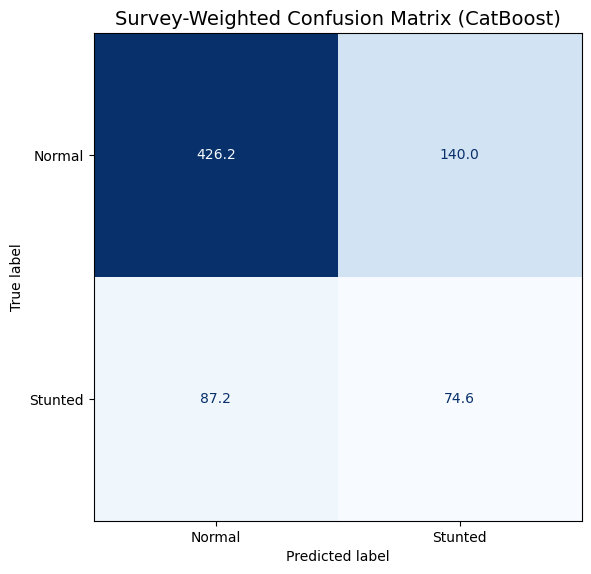

In [26]:
# ==========================================================
# Step-22 : Survey-Weighted Confusion Matrix
# ==========================================================

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

cm = confusion_matrix(

    y_test,

    y_pred,

    labels=[
        0,
        1
    ],

    sample_weight=
        weights_test

)

disp = ConfusionMatrixDisplay(

    confusion_matrix=
        cm,

    display_labels=[
        "Normal",
        "Stunted"
    ]

)

fig, ax = plt.subplots(
    figsize=(6, 6)
)

disp.plot(

    cmap="Blues",

    ax=ax,

    colorbar=False,

    values_format=".1f"

)

plt.title(

    f"Survey-Weighted Confusion Matrix "
    f"({best_model_name})",

    fontsize=14

)

plt.tight_layout()

plt.show()

In [27]:
# ==========================================================
# Step-23 : Survey-Weighted Classification Report
# ==========================================================

from sklearn.metrics import classification_report

print("=" * 70)
print("SURVEY-WEIGHTED CLASSIFICATION REPORT")
print("=" * 70)

print(

    classification_report(

        y_test,

        y_pred,

        target_names=[

            "Normal",

            "Stunted"

        ],

        sample_weight=
            weights_test,

        digits=4,

        zero_division=0

    )

)

SURVEY-WEIGHTED CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal     0.8301    0.7528    0.7895 566.149248999999
     Stunted     0.3478    0.4611    0.3965 161.87757000000002

    accuracy                         0.6879 728.026818999999
   macro avg     0.5889    0.6069    0.5930 728.026818999999
weighted avg     0.7229    0.6879    0.7022 728.026818999999



In [28]:
# ==========================================================
# Step-31 : Save Final Survey-Aware Spatial ML Workspace
#           FIXED MODEL CONFIGURATIONS
#           NO HYPERPARAMETER-TUNING OBJECTS
#           EXPLICIT OBJECT NAMES
# ==========================================================

import os
import shutil
import joblib


print("=" * 70)
print("SAVING FINAL SPATIAL ML WORKSPACE")
print("=" * 70)


save_path = "SpatialML_Saved"


# ==========================================================
# 1. Remove Old Saved Artifacts
# ==========================================================

if os.path.exists(
    save_path
):

    shutil.rmtree(
        save_path
    )


os.makedirs(
    save_path,
    exist_ok=True
)


# ==========================================================
# 2. Explicit Final Prediction-Component Bundle
# ==========================================================

final_prediction_components = {

    # ------------------------------------------------------
    # Final fitted prediction model
    # ------------------------------------------------------

    "final_base_model":
        final_model,


    # ------------------------------------------------------
    # Separate probability calibrator
    # ------------------------------------------------------

    "probability_calibrator":
        probability_calibrator,


    # ------------------------------------------------------
    # Locked operating threshold
    # ------------------------------------------------------

    "final_threshold":
        final_threshold,


    # ------------------------------------------------------
    # Final preprocessing objects
    # ------------------------------------------------------

    "scaler":
        scaler,

    "onehot_encoder":
        onehot_encoder,


    # ------------------------------------------------------
    # Final model features
    # ------------------------------------------------------

    "model_features":
        model_features,

    "selected_variables":
        selected_vars,


    # ------------------------------------------------------
    # Categorical-variable definitions
    # ------------------------------------------------------

    "nominal_socio_vars":
        nominal_socio_vars,

    "encoded_nominal_columns":
        encoded_nominal_columns,


    # ------------------------------------------------------
    # Environmental / spatial variables
    # ------------------------------------------------------

    "environment_variables":
        env_vars,

    "wx_variables":
        wx_vars,

    "K_NEIGHBORS":
        K_NEIGHBORS,


    # ------------------------------------------------------
    # Final weighting strategy
    # ------------------------------------------------------

    "best_weight_strategy":
        best_weight_strategy,
}


# ==========================================================
# 3. Objects to Save
# ==========================================================

objects_to_save = {

    # ======================================================
    # FINAL MODEL
    # ======================================================

    "final_base_model.pkl":
        final_model,

    "best_model_name.pkl":
        best_model_name,


    # ------------------------------------------------------
    # Fixed candidate model templates
    #
    # Hyperparameter-tuning objects are NOT saved because
    # the final pipeline no longer performs parameter search.
    # ------------------------------------------------------

    "fixed_model_templates.pkl":
        models_default,


    # ------------------------------------------------------
    # Final weighting strategy
    # ------------------------------------------------------

    "best_weight_strategy.pkl":
        best_weight_strategy,


    # ------------------------------------------------------
    # Final locked threshold
    # ------------------------------------------------------

    "final_threshold.pkl":
        final_threshold,


    # ------------------------------------------------------
    # Complete prediction bundle
    # ------------------------------------------------------

    "final_prediction_components.pkl":
        final_prediction_components,


    # ======================================================
    # CALIBRATION
    # ======================================================

    "probability_calibrator.pkl":
        probability_calibrator,

    "calibration_probability_raw.pkl":
        calibration_probability_raw,

    "calibration_probability.pkl":
        calibration_probability,


    # ======================================================
    # PREPROCESSING
    # ======================================================

    "final_scaler.pkl":
        scaler,

    "final_onehot_encoder.pkl":
        onehot_encoder,

    "nominal_socio_vars.pkl":
        nominal_socio_vars,

    "encoded_nominal_columns.pkl":
        encoded_nominal_columns,

    "cv.pkl":
        cv,


    # ======================================================
    # FEATURES
    # ======================================================

    "model_features.pkl":
        model_features,

    "selected_variables.pkl":
        selected_vars,

    "gb_importance.pkl":
        gb_df,

    "wx_variables.pkl":
        wx_vars,

    "environment_variables.pkl":
        env_vars,

    "socioeconomic_variables.pkl":
        socio_vars,

    "socioeconomic_variables_raw.pkl":
        socio_vars_raw,

    "predictor_definition.pkl":
        final_predictor_definition_df,


    # ======================================================
    # MODEL-DEVELOPMENT / CALIBRATION / FINAL-TEST MATRICES
    # ======================================================

    "X_model_development_raw.pkl":
        X_train_raw,

    "X_calibration_raw.pkl":
        X_calibration_raw,

    "X_final_test_raw.pkl":
        X_test_raw,


    "X_model_development.pkl":
        X_train,

    "X_calibration.pkl":
        X_calibration,

    "X_final_test.pkl":
        X_test,


    "y_model_development.pkl":
        y_train,

    "y_calibration.pkl":
        y_calibration,

    "y_final_test.pkl":
        y_test,


    # ======================================================
    # SURVEY DESIGN
    # ======================================================

    "groups_model_development.pkl":
        groups_train,

    "groups_calibration.pkl":
        groups_calibration,

    "groups_final_test.pkl":
        groups_test,

    "all_groups.pkl":
        groups,


    "weights_model_development.pkl":
        weights_train,

    "weights_calibration.pkl":
        weights_calibration,

    "weights_final_test.pkl":
        weights_test,

    "final_fit_weights.pkl":
        final_fit_weights,

    "all_survey_weights.pkl":
        survey_weights,


    "strata_model_development.pkl":
        strata_train,

    "strata_calibration.pkl":
        strata_calibration,

    "strata_final_test.pkl":
        strata_test,

    "all_strata.pkl":
        strata,

    "all_strata_v022.pkl":
        strata_v022_all,


    # ======================================================
    # SPATIAL DESIGN
    # ======================================================

    "spatial_clusters_model_development.pkl":
        spatial_clusters_train,

    "spatial_clusters_calibration.pkl":
        spatial_clusters_calibration,

    "spatial_clusters_final_test.pkl":
        spatial_clusters_test,

    "all_spatial_clusters.pkl":
        spatial_clusters,


    "coords_model_development.pkl":
        coords_train,

    "coords_calibration.pkl":
        coords_calibration,

    "coords_final_test.pkl":
        coords_test,

    "all_coordinates.pkl":
        coordinates,


    # ======================================================
    # SPLIT INDICES
    # ======================================================

    "development_pool_idx.pkl":
        development_pool_idx,

    "model_development_idx.pkl":
        train_idx,

    "calibration_idx.pkl":
        calibration_idx,

    "final_test_idx.pkl":
        test_idx,


    # ======================================================
    # FINAL-TEST PREDICTIONS
    # ======================================================

    "y_pred.pkl":
        y_pred,

    "y_prob_calibrated.pkl":
        y_prob,

    "y_prob_raw.pkl":
        y_prob_raw,


    # ======================================================
    # DEVELOPMENT / MODEL-SELECTION RESULTS
    # ======================================================

    "development_cv_results.pkl":
        default_df,

    "ranking_results.pkl":
        ranking_df,

    "weight_sensitivity_results.pkl":
        weight_sensitivity_df,

    "final_test_metrics.pkl":
        final_test_metrics_df,


    # ======================================================
    # DATASET
    # ======================================================

    "final_dataset.pkl":
        df,

    "target_vector.pkl":
        y,


    # ======================================================
    # SETTINGS / DOCUMENTATION
    # ======================================================

    "K_NEIGHBORS.pkl":
        K_NEIGHBORS,

    "target_name.pkl":
        target,

    "spatial_interpretation_note.pkl":
        spatial_interpretation_note,

    "child_age_status.pkl":
        child_age_status,

    "child_age_candidates.pkl":
        child_age_candidates,
}


# ==========================================================
# 4. Save All Objects
# ==========================================================

for filename, obj in objects_to_save.items():

    joblib.dump(

        obj,

        os.path.join(
            save_path,
            filename
        )

    )


# ==========================================================
# 5. Save Audit
# ==========================================================

print(
    "\nAll objects saved successfully."
)

print(
    "Saved folder:",
    save_path
)

print(
    "Total saved objects:",
    len(
        objects_to_save
    )
)


print(
    "\n✓ Old saved artifacts were cleared before saving."
)

print(
    "✓ Fitted final model is saved as "
    "final_base_model.pkl."
)

print(
    "✓ Fixed candidate-model templates are saved as "
    "fixed_model_templates.pkl."
)

print(
    "✓ Development-CV results are saved as "
    "development_cv_results.pkl."
)

print(
    "✓ Hyperparameter-tuning objects are NOT saved."
)

print(
    "✓ The probability calibrator remains a separate "
    "explicitly named saved object."
)

print(
    "✓ The locked classification threshold is saved "
    "separately."
)

print(
    "✓ Development, calibration, and final-test objects "
    "remain explicitly separated."
)

print(
    "✓ Survey-design and spatial-design objects are retained."
)

print(
    "✓ Final-test predictions and metrics are retained."
)

SAVING FINAL SPATIAL ML WORKSPACE

All objects saved successfully.
Saved folder: SpatialML_Saved
Total saved objects: 71

✓ Old saved artifacts were cleared before saving.
✓ Fitted final model is saved as final_base_model.pkl.
✓ Fixed candidate-model templates are saved as fixed_model_templates.pkl.
✓ Development-CV results are saved as development_cv_results.pkl.
✓ Hyperparameter-tuning objects are NOT saved.
✓ The probability calibrator remains a separate explicitly named saved object.
✓ The locked classification threshold is saved separately.
✓ Development, calibration, and final-test objects remain explicitly separated.
✓ Survey-design and spatial-design objects are retained.
✓ Final-test predictions and metrics are retained.


In [29]:
# ==========================================================
# Step-31A : Environment Information
#
# No package installation is performed inside the notebook.
# Exact analysis-environment versions are documented here.
# ==========================================================

import os
import platform
import pandas as pd

from importlib.metadata import (
    version,
    PackageNotFoundError
)


print("=" * 70)
print("ENVIRONMENT INFORMATION")
print("=" * 70)


# ==========================================================
# Python Version
# ==========================================================

python_version = (
    platform.python_version()
)


print(
    "Python Version:",
    python_version
)


# ==========================================================
# Packages Used in the Analysis
# ==========================================================

packages_to_record = [

    "numpy",
    "pandas",
    "matplotlib",
    "statsmodels",
    "scikit-learn",
    "xgboost",
    "lightgbm",
    "catboost",
    "geoshapley",
    "geopandas",
    "libpysal",
    "esda",
    "pyreadstat",
    "joblib",
]


environment_rows = [

    {
        "Package":
            "Python",

        "Version":
            python_version
    }

]


for package_name in packages_to_record:

    try:

        package_version = version(
            package_name
        )

    except PackageNotFoundError:

        package_version = (
            "NOT INSTALLED"
        )


    environment_rows.append({

        "Package":
            package_name,

        "Version":
            package_version,
    })


environment_versions_df = pd.DataFrame(
    environment_rows
)


display(
    environment_versions_df
)


# ==========================================================
# Save Environment Information
# ==========================================================

requirements_file = os.path.join(

    save_path,

    "environment_versions.csv"
)


environment_versions_df.to_csv(

    requirements_file,

    index=False
)


print(
    "\nEnvironment versions saved to:",
    requirements_file
)


print(
    "✓ Python version is documented."
)


print(
    "✓ matplotlib and statsmodels versions are documented."
)


print(
    "✓ No package installation command is embedded "
    "in this notebook."
)

ENVIRONMENT INFORMATION
Python Version: 3.13.9


,Package,Version
0,Python,3.13.9
1,numpy,2.3.5
2,pandas,2.3.3
3,matplotlib,3.10.6
4,statsmodels,0.14.5
5,scikit-learn,1.7.2
6,xgboost,3.2.0
7,lightgbm,4.6.0
8,catboost,1.2.10
9,geoshapley,0.2.0.0



Environment versions saved to: SpatialML_Saved\environment_versions.csv
✓ Python version is documented.
✓ matplotlib and statsmodels versions are documented.
✓ No package installation command is embedded in this notebook.


In [30]:
# ==========================================================
# Restore Final Survey-Aware Spatial ML Workspace
# FIXED MODEL CONFIGURATIONS
# NO HYPERPARAMETER-TUNING OBJECTS
# ==========================================================

import os
import joblib
import numpy as np

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
)


print("=" * 70)
print("RESTORING FINAL SPATIAL ML WORKSPACE")
print("=" * 70)


save_path = "SpatialML_Saved"


# ==========================================================
# Helper Function
# ==========================================================

def load_saved(
    filename
):

    filepath = os.path.join(
        save_path,
        filename
    )

    if not os.path.exists(
        filepath
    ):

        raise FileNotFoundError(
            f"Missing saved object: {filepath}"
        )

    return joblib.load(
        filepath
    )


# ==========================================================
# 1. Final Fitted Model + Fixed Model Templates
# ==========================================================

final_model = load_saved(
    "final_base_model.pkl"
)


best_model_name = load_saved(
    "best_model_name.pkl"
)


# ----------------------------------------------------------
# Fixed candidate-model templates
# No tuned model templates are restored.
# ----------------------------------------------------------

models_default = load_saved(
    "fixed_model_templates.pkl"
)


best_weight_strategy = load_saved(
    "best_weight_strategy.pkl"
)


final_threshold = load_saved(
    "final_threshold.pkl"
)


final_prediction_components = load_saved(
    "final_prediction_components.pkl"
)


# ==========================================================
# 2. Calibration
# ==========================================================

probability_calibrator = load_saved(
    "probability_calibrator.pkl"
)


calibration_probability_raw = load_saved(
    "calibration_probability_raw.pkl"
)


calibration_probability = load_saved(
    "calibration_probability.pkl"
)


# ==========================================================
# 3. Preprocessing
# ==========================================================

scaler = load_saved(
    "final_scaler.pkl"
)


onehot_encoder = load_saved(
    "final_onehot_encoder.pkl"
)


nominal_socio_vars = load_saved(
    "nominal_socio_vars.pkl"
)


encoded_nominal_columns = load_saved(
    "encoded_nominal_columns.pkl"
)


cv = load_saved(
    "cv.pkl"
)


# ==========================================================
# 4. Features
# ==========================================================

model_features = load_saved(
    "model_features.pkl"
)


selected_vars = load_saved(
    "selected_variables.pkl"
)


gb_df = load_saved(
    "gb_importance.pkl"
)


wx_vars = load_saved(
    "wx_variables.pkl"
)


env_vars = load_saved(
    "environment_variables.pkl"
)


socio_vars = load_saved(
    "socioeconomic_variables.pkl"
)


socio_vars_raw = load_saved(
    "socioeconomic_variables_raw.pkl"
)


final_predictor_definition_df = load_saved(
    "predictor_definition.pkl"
)


# ==========================================================
# 5. Model-Development / Calibration / Final-Test Matrices
# ==========================================================

X_train_raw = load_saved(
    "X_model_development_raw.pkl"
)


X_calibration_raw = load_saved(
    "X_calibration_raw.pkl"
)


X_test_raw = load_saved(
    "X_final_test_raw.pkl"
)


X_train = load_saved(
    "X_model_development.pkl"
)


X_calibration = load_saved(
    "X_calibration.pkl"
)


X_test = load_saved(
    "X_final_test.pkl"
)


y_train = load_saved(
    "y_model_development.pkl"
)


y_calibration = load_saved(
    "y_calibration.pkl"
)


y_test = load_saved(
    "y_final_test.pkl"
)


# ==========================================================
# 6. Survey Design
# ==========================================================

groups_train = load_saved(
    "groups_model_development.pkl"
)


groups_calibration = load_saved(
    "groups_calibration.pkl"
)


groups_test = load_saved(
    "groups_final_test.pkl"
)


groups = load_saved(
    "all_groups.pkl"
)


weights_train = load_saved(
    "weights_model_development.pkl"
)


weights_calibration = load_saved(
    "weights_calibration.pkl"
)


weights_test = load_saved(
    "weights_final_test.pkl"
)


final_fit_weights = load_saved(
    "final_fit_weights.pkl"
)


# ----------------------------------------------------------
# Recreate training weights used by later cells
# ----------------------------------------------------------

combined_train_weights = np.asarray(
    final_fit_weights,
    dtype=float
).copy()


survey_weights = load_saved(
    "all_survey_weights.pkl"
)


strata_train = load_saved(
    "strata_model_development.pkl"
)


strata_calibration = load_saved(
    "strata_calibration.pkl"
)


strata_test = load_saved(
    "strata_final_test.pkl"
)


strata = load_saved(
    "all_strata.pkl"
)


strata_v022_all = load_saved(
    "all_strata_v022.pkl"
)


# ==========================================================
# 7. Spatial Design
# ==========================================================

spatial_clusters_train = load_saved(
    "spatial_clusters_model_development.pkl"
)


spatial_clusters_calibration = load_saved(
    "spatial_clusters_calibration.pkl"
)


spatial_clusters_test = load_saved(
    "spatial_clusters_final_test.pkl"
)


spatial_clusters = load_saved(
    "all_spatial_clusters.pkl"
)


coords_train = load_saved(
    "coords_model_development.pkl"
)


coords_calibration = load_saved(
    "coords_calibration.pkl"
)


coords_test = load_saved(
    "coords_final_test.pkl"
)


coordinates = load_saved(
    "all_coordinates.pkl"
)


# ==========================================================
# 8. Split Indices
# ==========================================================

development_pool_idx = load_saved(
    "development_pool_idx.pkl"
)


train_idx = load_saved(
    "model_development_idx.pkl"
)


calibration_idx = load_saved(
    "calibration_idx.pkl"
)


test_idx = load_saved(
    "final_test_idx.pkl"
)


# ==========================================================
# 9. Final-Test Predictions
# ==========================================================

y_pred = load_saved(
    "y_pred.pkl"
)


y_prob = load_saved(
    "y_prob_calibrated.pkl"
)


y_prob_raw = load_saved(
    "y_prob_raw.pkl"
)


# ==========================================================
# 10. Development / Model-Selection Results
# ==========================================================

# ----------------------------------------------------------
# Development-CV results
# This replaces the old:
# default_results.pkl + tuned_results.pkl structure.
# ----------------------------------------------------------

default_df = load_saved(
    "development_cv_results.pkl"
)


ranking_df = load_saved(
    "ranking_results.pkl"
)


weight_sensitivity_df = load_saved(
    "weight_sensitivity_results.pkl"
)


final_test_metrics_df = load_saved(
    "final_test_metrics.pkl"
)


# ==========================================================
# 11. Data / Settings / Documentation
# ==========================================================

df = load_saved(
    "final_dataset.pkl"
)


y = load_saved(
    "target_vector.pkl"
)


K_NEIGHBORS = load_saved(
    "K_NEIGHBORS.pkl"
)


target = load_saved(
    "target_name.pkl"
)


spatial_interpretation_note = load_saved(
    "spatial_interpretation_note.pkl"
)


child_age_status = load_saved(
    "child_age_status.pkl"
)


child_age_candidates = load_saved(
    "child_age_candidates.pkl"
)


# ==========================================================
# 12. Recreate Probability-Calibration Functions
# ==========================================================

EPS = 1e-6


def probability_to_logit(
    probability
):

    probability = np.clip(
        np.asarray(
            probability,
            dtype=float
        ),
        EPS,
        1 - EPS
    )

    return np.log(
        probability
        /
        (
            1 - probability
        )
    )


def apply_probability_calibration(
    raw_probability
):

    calibration_input = (
        probability_to_logit(
            raw_probability
        )
        .reshape(
            -1,
            1
        )
    )

    return (
        probability_calibrator
        .predict_proba(
            calibration_input
        )[:, 1]
    )


# ==========================================================
# 13. Recreate Final-Test Statistics
# ==========================================================

final_test_auc = roc_auc_score(
    y_test,
    y_prob,
    sample_weight=
        weights_test
)


final_test_ap = average_precision_score(
    y_test,
    y_prob,
    sample_weight=
        weights_test
)


final_test_brier = brier_score_loss(
    y_test,
    y_prob,
    sample_weight=
        weights_test
)


final_auc_ci_lower = float(
    final_test_metrics_df.loc[
        0,
        "AUC_CI_Lower"
    ]
)


final_auc_ci_upper = float(
    final_test_metrics_df.loc[
        0,
        "AUC_CI_Upper"
    ]
)


# ==========================================================
# 14. Integrity Checks
# ==========================================================

if len(
    X_train
) != len(
    y_train
):

    raise RuntimeError(
        "Restored model-development X/y lengths do not match."
    )


if len(
    X_calibration
) != len(
    y_calibration
):

    raise RuntimeError(
        "Restored calibration X/y lengths do not match."
    )


if len(
    X_test
) != len(
    y_test
):

    raise RuntimeError(
        "Restored final-test X/y lengths do not match."
    )


if len(
    y_prob
) != len(
    y_test
):

    raise RuntimeError(
        "Restored final-test probabilities do not match y_test."
    )


if len(
    weights_test
) != len(
    y_test
):

    raise RuntimeError(
        "Restored final-test weights do not match y_test."
    )


if len(
    model_features
) != X_train.shape[1]:

    raise RuntimeError(
        "Restored model-feature count does not match "
        "the development matrix."
    )


# ==========================================================
# 15. Final Restore Audit
# ==========================================================

print(
    "\nModel:",
    best_model_name
)


print(
    "Training weighting strategy:",
    best_weight_strategy
)


print(
    "Candidate fixed models:",
    len(
        models_default
    )
)


print(
    "Model-development observations:",
    len(
        y_train
    )
)


print(
    "Calibration observations:",
    len(
        y_calibration
    )
)


print(
    "Final-test observations:",
    len(
        y_test
    )
)


print(
    "Features:",
    len(
        model_features
    )
)


print(
    "Locked MCC-based threshold:",
    round(
        final_threshold,
        4
    )
)


print(
    "Test ROC-AUC:",
    round(
        final_test_auc,
        4
    )
)


print(
    "95% PSU-bootstrap ROC-AUC CI:",
    f"{final_auc_ci_lower:.4f}–"
    f"{final_auc_ci_upper:.4f}"
)


print(
    "Test Average Precision (AP):",
    round(
        final_test_ap,
        4
    )
)


print(
    "Test Brier:",
    round(
        final_test_brier,
        4
    )
)


print(
    "\n✓ Final workspace restored successfully."
)


print(
    "✓ Fixed candidate-model configurations restored."
)


print(
    "✓ No hyperparameter-tuning objects were restored."
)


print(
    "✓ Development, calibration and final-test "
    "partitions remain separate."
)


print(
    "✓ Survey and spatial-design information restored."
)


print(
    "✓ GeoShapley-related downstream analysis can "
    "continue from the restored workspace."
)

RESTORING FINAL SPATIAL ML WORKSPACE

Model: CatBoost
Training weighting strategy: SurveyWeightOnly
Candidate fixed models: 13
Model-development observations: 2340
Calibration observations: 564
Final-test observations: 716
Features: 55
Locked MCC-based threshold: 0.2541
Test ROC-AUC: 0.6634
95% PSU-bootstrap ROC-AUC CI: 0.6161–0.7056
Test Average Precision (AP): 0.3636
Test Brier: 0.1627

✓ Final workspace restored successfully.
✓ Fixed candidate-model configurations restored.
✓ No hyperparameter-tuning objects were restored.
✓ Development, calibration and final-test partitions remain separate.
✓ Survey and spatial-design information restored.
✓ GeoShapley-related downstream analysis can continue from the restored workspace.


In [31]:
# ==========================================================
# Step-32 : Reduced Explanatory Model for GeoShapley
#
# IMPORTANT:
# This is NOT the full final predictive model.
#
# GeoShapley model:
#   Top 10 TRAINING-derived GB predictors
#   + latitude
#   + longitude
# ==========================================================

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score


print("=" * 70)
print("REDUCED EXPLANATORY MODEL FOR GEOSHAPLEY")
print("=" * 70)


N_TOP_FEATURES = 10


coord_cols = [
    "lat",
    "lon"
]


# ==========================================================
# Final Training-Derived GB Ranking
# ==========================================================

top_features = [

    feature

    for feature
    in gb_df[
        "Feature"
    ].tolist()

    if (
        feature
        in model_features

        and

        feature
        not in coord_cols
    )

][
    :N_TOP_FEATURES
]


geo_feature_list = (

    top_features

    +

    coord_cols
)


print(
    "GeoShapley Features:"
)


print(
    geo_feature_list
)


print(
    "Total Features:",
    len(
        geo_feature_list
    )
)


# ==========================================================
# Reduced Model Matrices
# ==========================================================

X_train_geo = (

    X_train_raw[
        geo_feature_list
    ]

    .copy()
)


X_test_geo = (

    X_test_raw[
        geo_feature_list
    ]

    .copy()
)


# ==========================================================
# Reduced Explanatory Model
# ==========================================================

reduced_geo_pipeline = Pipeline([

    (
        "scaler",
        StandardScaler()
    ),

    (
        "model",
        clone(
            final_model
        )
    )
])


reduced_geo_pipeline.fit(

    X_train_geo,

    y_train,

    scaler__sample_weight=
        weights_train,

    model__sample_weight=
        combined_train_weights
)


# ==========================================================
# Post-Hoc Descriptive Discrimination Comparison
# ==========================================================

geo_test_prob = (

    reduced_geo_pipeline

    .predict_proba(
        X_test_geo
    )[:, 1]
)


geo_test_auc = roc_auc_score(

    y_test,

    geo_test_prob,

    sample_weight=
        weights_test
)


auc_gap = (

    geo_test_auc

    -

    final_test_auc
)


print(
    "\nFull Final Model ROC-AUC:",
    round(
        final_test_auc,
        4
    )
)


print(
    "Reduced GeoShapley Model ROC-AUC:",
    round(
        geo_test_auc,
        4
    )
)


print(
    "ROC-AUC difference "
    "(Reduced - Full):",
    round(
        auc_gap,
        4
    )
)


# ==========================================================
# Real Coordinates
# ==========================================================

X_train_real_coords = pd.DataFrame({

    "real_lat":
        coords_train[
            :,
            1
        ],

    "real_lon":
        coords_train[
            :,
            0
        ]
})


X_test_real_coords = pd.DataFrame({

    "real_lat":
        coords_test[
            :,
            1
        ],

    "real_lon":
        coords_test[
            :,
            0
        ]
})


# ==========================================================
# Survey-Weighted GeoShapley Background
# ==========================================================

background = (

    X_train_geo

    .sample(

        n=min(
            30,
            len(
                X_train_geo
            )
        ),

        weights=
            np.asarray(
                weights_train,
                dtype=float
            ),

        random_state=42
    )

    .to_numpy()
)


print(
    "Background Shape:",
    background.shape
)


# ==========================================================
# Audit
# ==========================================================

print(
    "\n✓ GeoShapley explains the "
    "REDUCED explanatory model."
)


print(
    "✓ GeoShapley background observations are sampled "
    "using model-development DHS survey weights."
)


print(
    "✓ Reduced-model test ROC-AUC comparison is post-hoc "
    "explanatory only and is not used for model selection, "
    "feature selection, redesign, or replacement of the "
    "locked final model."
)


print(
    "✓ Locked final predictive model remains:",
    best_model_name
)


print(
    "✓ Reduced-model scaling is survey-weighted."
)


print(
    "✓ Spatial interpretation uses displaced DHS cluster "
    "coordinates and must not be interpreted as exact "
    "location effects."
)

REDUCED EXPLANATORY MODEL FOR GEOSHAPLEY
GeoShapley Features:
['Maternal_Height', 'lst_celsius', 'slope_degrees', 'Wealth_1.0', 'wx_pdsi_drought_index', 'BMI', 'wx_pop_density', 'wx_slope_degrees', 'wx_lst_celsius', 'pop_density', 'lat', 'lon']
Total Features: 12

Full Final Model ROC-AUC: 0.6634
Reduced GeoShapley Model ROC-AUC: 0.6597
ROC-AUC difference (Reduced - Full): -0.0037
Background Shape: (30, 12)

✓ GeoShapley explains the REDUCED explanatory model.
✓ GeoShapley background observations are sampled using model-development DHS survey weights.
✓ Reduced-model test ROC-AUC comparison is post-hoc explanatory only and is not used for model selection, feature selection, redesign, or replacement of the locked final model.
✓ Locked final predictive model remains: CatBoost
✓ Reduced-model scaling is survey-weighted.
✓ Spatial interpretation uses displaced DHS cluster coordinates and must not be interpreted as exact location effects.


In [32]:
# ==========================================================
# Step-33 : Reduced-Model GeoShapley Explainer
# ==========================================================

from geoshapley import GeoShapleyExplainer

print("=" * 70)
print("BUILDING REDUCED-MODEL GEOSHAPLEY EXPLAINER")
print("=" * 70)

def predict_probability(data):

    if isinstance(
        data,
        np.ndarray
    ):

        data = pd.DataFrame(
            data,
            columns=geo_feature_list
        )

    return (

        reduced_geo_pipeline

        .predict_proba(
            data[geo_feature_list]
        )[:, 1]

    )


geo_explainer = GeoShapleyExplainer(

    predict_f=predict_probability,

    background=background,

    g=2,

    exact=False
)

print(
    "GeoShapley Explainer created successfully."
)

BUILDING REDUCED-MODEL GEOSHAPLEY EXPLAINER
GeoShapley Explainer created successfully.


In [33]:
# ==========================================================
# Step-34 : Compute GeoShapley Values
# ==========================================================

print("=" * 70)
print("COMPUTING GEOSHAPLEY VALUES")
print("=" * 70)

X_geo_sample = (

    X_test_geo

    .reset_index(
        drop=True
    )

    .copy()

)

real_coords_sample = (

    X_test_real_coords

    .reset_index(
        drop=True
    )

    .copy()

)

# IMPORTANT:
# GeoShapley mapping uses DHS spatial cluster,
# NOT PSU grouping variable.

cluster_ids_sample = pd.Series(

    spatial_clusters_test

).reset_index(
    drop=True
)

print(
    "Sample Size :",
    len(
        X_geo_sample
    )
)

print(
    "Feature Count :",
    X_geo_sample.shape[1]
)

print(
    "Unique Spatial Clusters :",
    cluster_ids_sample.nunique()
)

geo_results = geo_explainer.explain(

    X_geo_sample,

    n_jobs=1

)

print(
    "\nGeoShapley completed successfully."
)

COMPUTING GEOSHAPLEY VALUES
Sample Size : 716
Feature Count : 12
Unique Spatial Clusters : 134


  0%|          | 0/716 [00:00<?, ?it/s]


GeoShapley completed successfully.


In [34]:
# ==========================================================
# Step-35 : Inspect GeoShapley Results
# ==========================================================

print("=" * 70)
print("GEOSHAPLEY RESULTS")
print("=" * 70)

print(type(geo_results))

print("\nAvailable Attributes:\n")

print(dir(geo_results))

GEOSHAPLEY RESULTS
<class 'geoshapley.geoshapley.GeoShapleyResults'>

Available Attributes:

['M', 'X_geo', '__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__firstlineno__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__static_attributes__', '__str__', '__subclasshook__', '__weakref__', 'background', 'base_value', 'check_additivity', 'contribution_bar_plot', 'explainer', 'g', 'geo', 'geo_intera', 'geoshap_to_shap', 'get_svc', 'partial_dependence_plots', 'predict_f', 'primary', 'summary_plot', 'summary_statistics']


GEOSHAPLEY SUMMARY PLOT


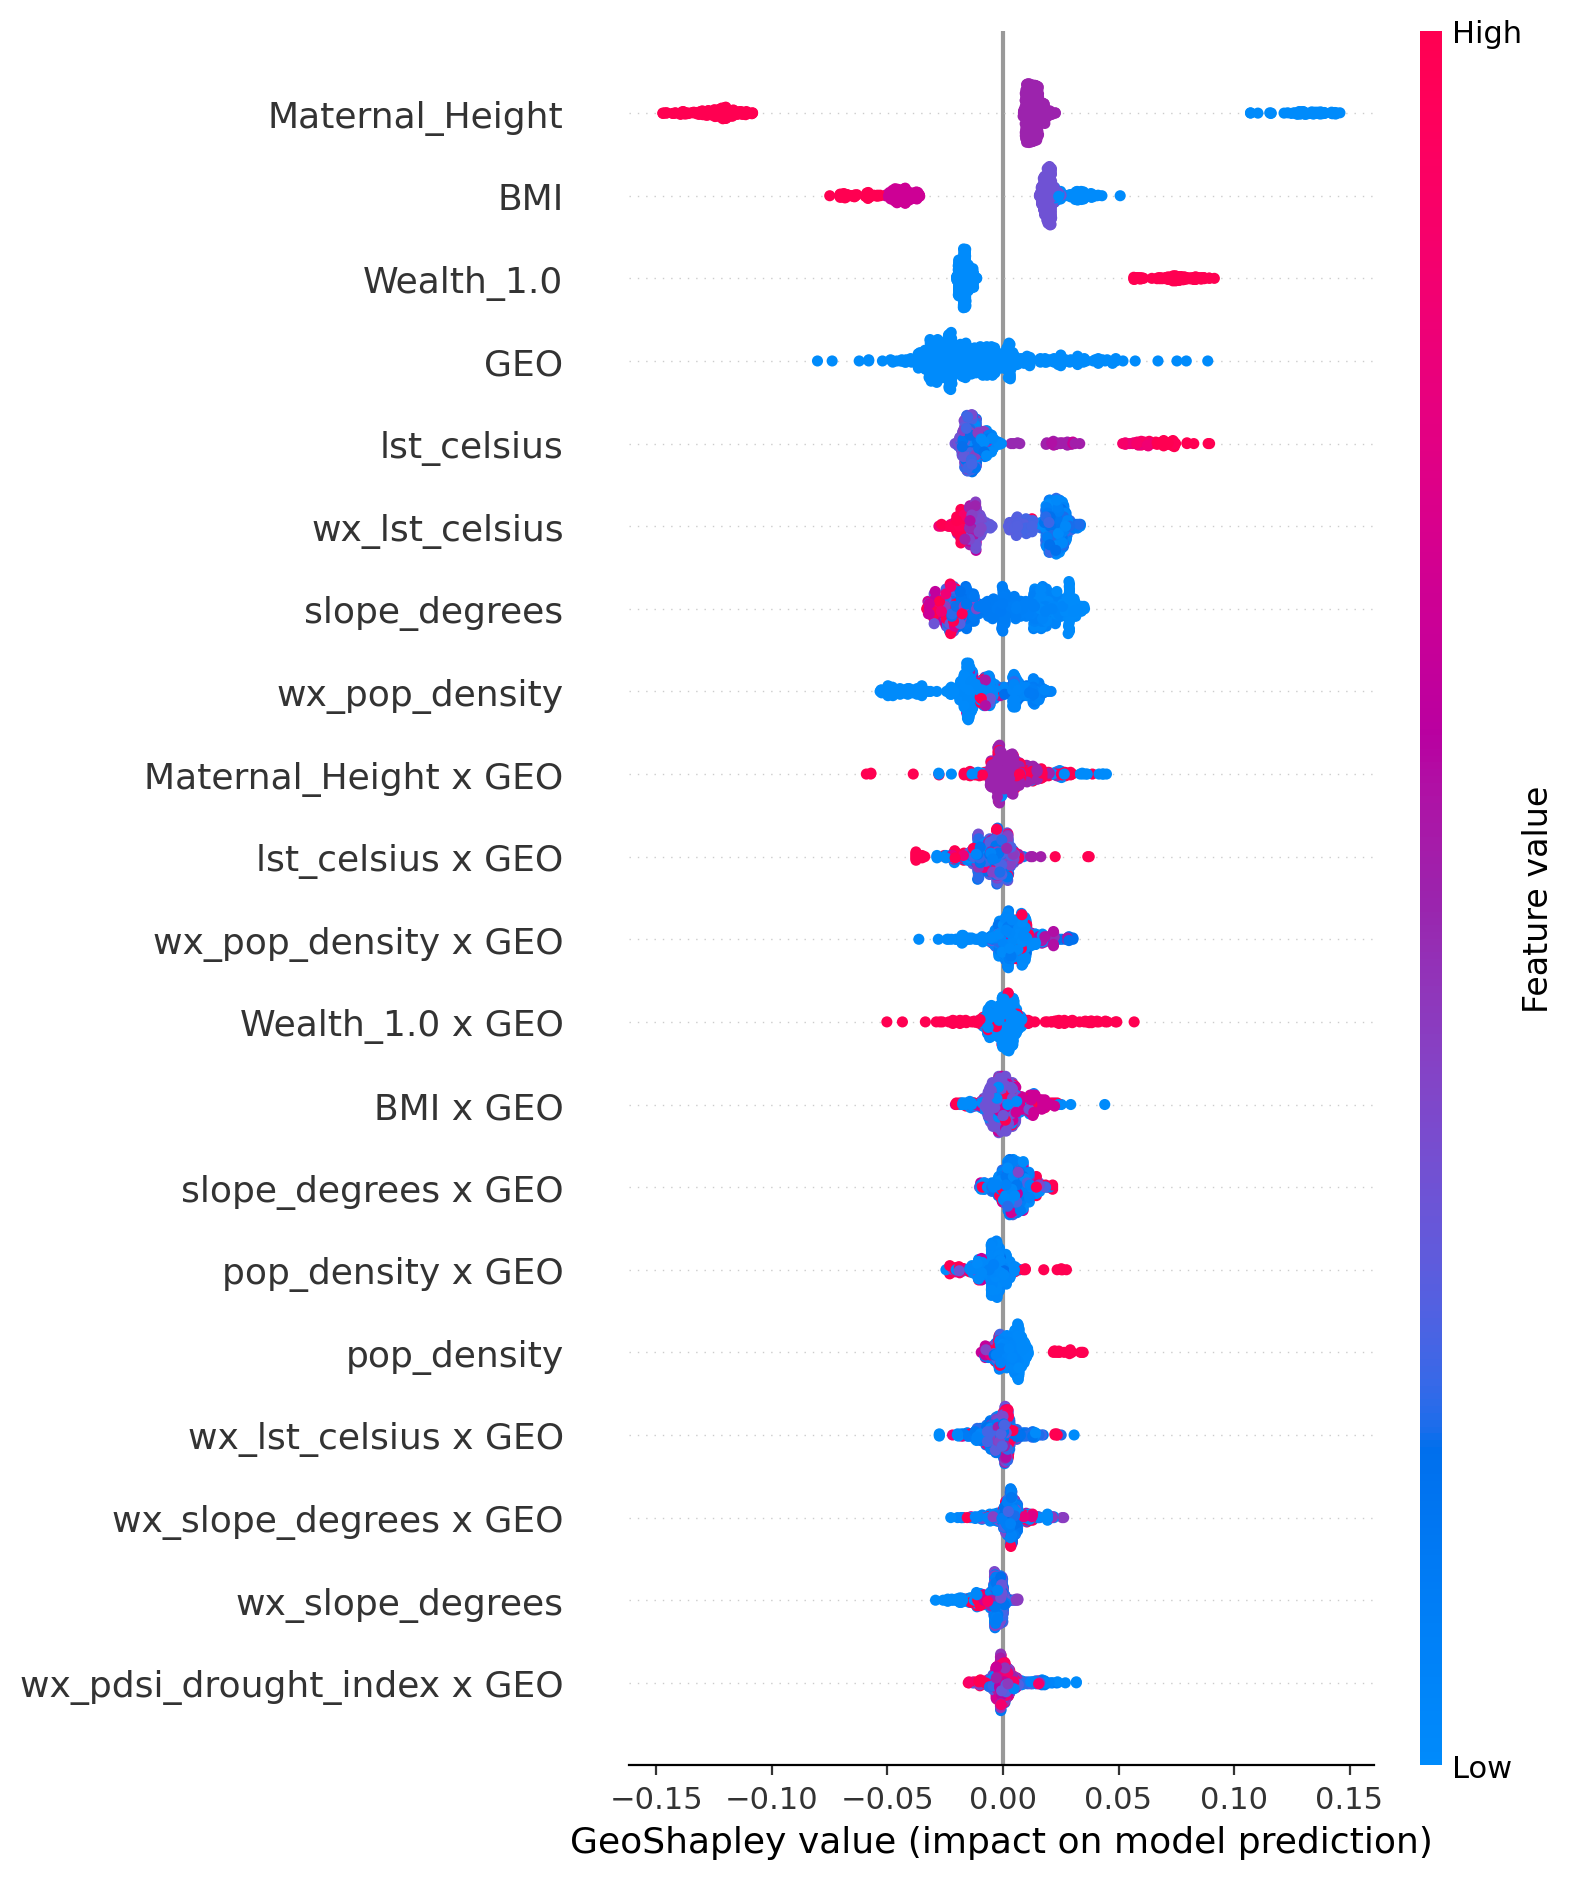

In [35]:
# ==========================================================
# Step-36 : GeoShapley Summary Plot
# ==========================================================

print("=" * 70)
print("GEOSHAPLEY SUMMARY PLOT")
print("=" * 70)

geo_results.summary_plot()

GEOSHAPLEY CONTRIBUTION BAR PLOT


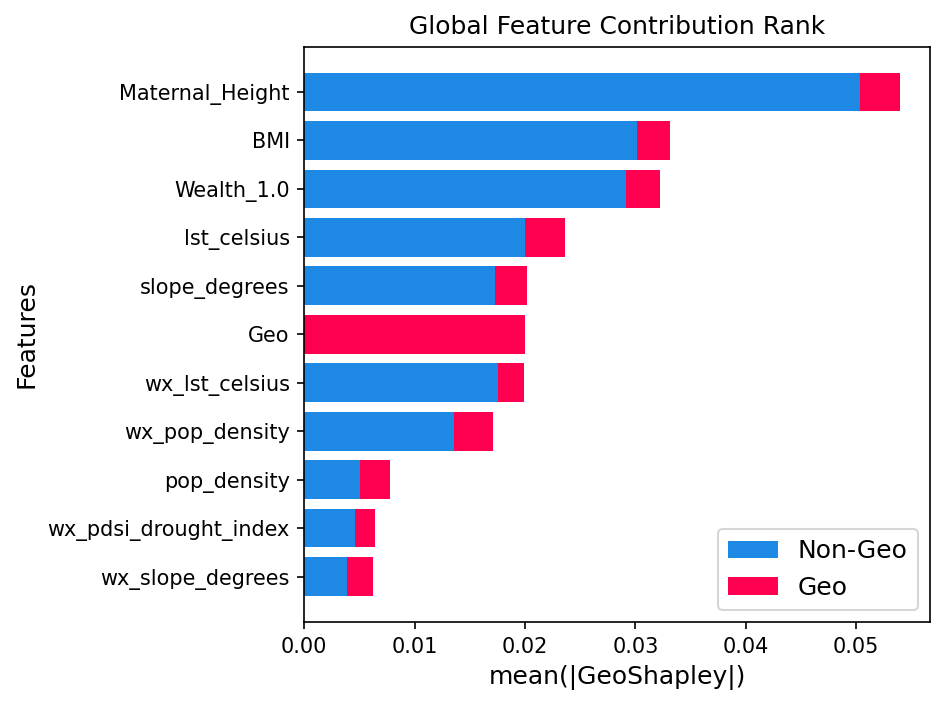

In [36]:
# ==========================================================
# Step-37 : GeoShapley Ranked Contribution Bar Plot
# ==========================================================

print("=" * 70)
print("GEOSHAPLEY CONTRIBUTION BAR PLOT")
print("=" * 70)

geo_results.contribution_bar_plot()

PARTIAL DEPENDENCE PLOTS (NON-SPATIAL)


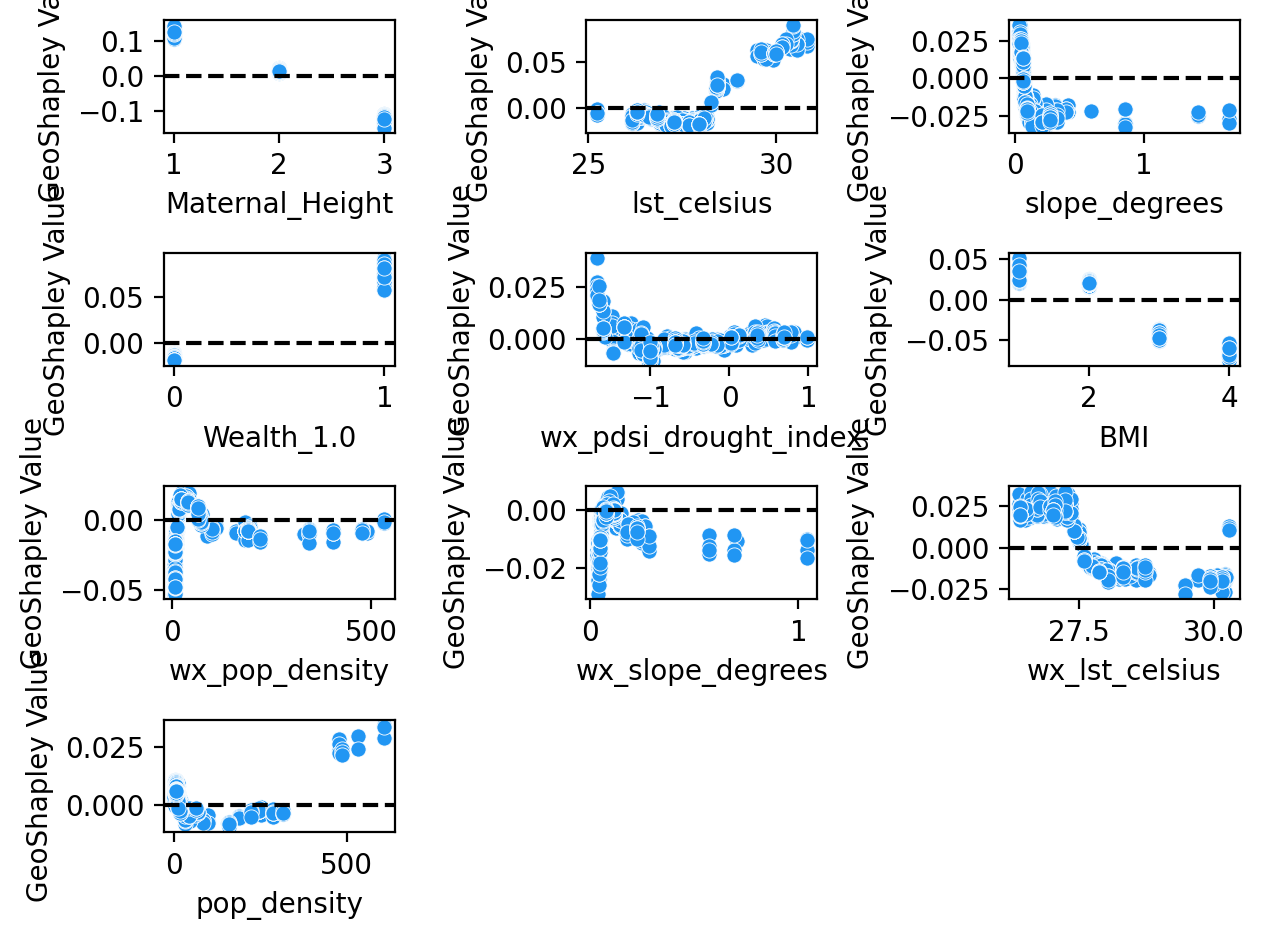

In [37]:
# ==========================================================
# Step-38 : Partial Dependence Plots (Primary / Non-spatial Effects)
# ==========================================================

print("=" * 70)
print("PARTIAL DEPENDENCE PLOTS (NON-SPATIAL)")
print("=" * 70)

geo_results.partial_dependence_plots()

In [ ]:
# ==========================================================
# Step-39 : Spatially Varying Coefficients (SVC)
#           Top GeoShapley Features
# ==========================================================

import numpy as np
import pandas as pd


print("=" * 70)
print("SPATIALLY VARYING COEFFICIENTS (TOP FEATURES)")
print("=" * 70)


# ==========================================================
# 1. IDENTIFY NON-COORDINATE TOP FEATURES
# ==========================================================

svc_features = [
    f
    for f in top_features
    if f not in coord_cols
]


feature_names_geo = list(
    X_geo_sample.columns[
        :-len(coord_cols)
    ]
)


if len(svc_features) == 0:
    raise RuntimeError(
        "No non-coordinate GeoShapley features "
        "are available for SVC calculation."
    )


missing_svc_features = [
    feature
    for feature in svc_features
    if feature not in feature_names_geo
]


if missing_svc_features:
    raise RuntimeError(
        "SVC feature(s) not found in "
        "GeoShapley feature matrix: "
        f"{missing_svc_features}"
    )


print("Computing SVC for features:")
print(svc_features)


# ==========================================================
# 2. OBTAIN CHILD-LEVEL SVC VALUES
# ==========================================================

svc_dict = {}


for feat in svc_features:

    idx = feature_names_geo.index(
        feat
    )

    svc_values = geo_results.get_svc(
        [idx],
        coef_type="gwr"
    )

    svc_values = np.asarray(
        svc_values,
        dtype=float
    ).ravel()


    if len(svc_values) != len(X_geo_sample):

        raise RuntimeError(
            "SVC length mismatch "
            f"for feature: {feat}"
        )


    svc_dict[feat] = svc_values


# ==========================================================
# 3. ALIGNMENT AUDIT
# ==========================================================

if not (
    len(X_geo_sample)
    ==
    len(cluster_ids_sample)
    ==
    len(real_coords_sample)
    ==
    len(weights_test)
):

    raise RuntimeError(
        "GeoShapley rows, DHS clusters, "
        "coordinates, and survey weights "
        "are not aligned."
    )


print(
    "\nGeoShapley observations:",
    len(X_geo_sample)
)

print(
    "DHS cluster IDs:",
    len(cluster_ids_sample)
)

print(
    "Survey weights:",
    len(weights_test)
)


# ==========================================================
# 4. CHILD-LEVEL SVC TABLE
# ==========================================================

cluster_geo_child = pd.DataFrame({

    "dhsclust":
        np.asarray(
            cluster_ids_sample
        ),

    "lat":
        real_coords_sample[
            "real_lat"
        ].to_numpy(
            dtype=float
        ),

    "lon":
        real_coords_sample[
            "real_lon"
        ].to_numpy(
            dtype=float
        ),

    "survey_weight":
        np.asarray(
            weights_test,
            dtype=float
        )
})


for feat in svc_features:

    cluster_geo_child[
        feat
    ] = svc_dict[
        feat
    ]


# ==========================================================
# 5. BASIC CHILD-LEVEL AUDIT
# ==========================================================

if (
    cluster_geo_child[
        ["lat", "lon"]
    ]
    .isna()
    .any()
    .any()
):

    raise RuntimeError(
        "Missing GeoShapley coordinates detected."
    )


if (
    cluster_geo_child[
        "survey_weight"
    ]
    .isna()
    .any()
):

    raise RuntimeError(
        "Missing survey weights detected "
        "in GeoShapley sample."
    )


if (
    cluster_geo_child[
        "survey_weight"
    ]
    <= 0
).any():

    raise RuntimeError(
        "Non-positive survey weights detected "
        "in GeoShapley sample."
    )


# ==========================================================
# 6. SAFE SURVEY-WEIGHTED MEAN
# ==========================================================

def weighted_mean_safe(
    values,
    weights
):

    values = np.asarray(
        values,
        dtype=float
    )

    weights = np.asarray(
        weights,
        dtype=float
    )


    valid = (
        np.isfinite(values)
        &
        np.isfinite(weights)
        &
        (weights > 0)
    )


    if not np.any(valid):
        return np.nan


    return float(
        np.average(
            values[valid],
            weights=weights[valid]
        )
    )


# ==========================================================
# 7. SURVEY-WEIGHTED DHS-CLUSTER AGGREGATION
# ==========================================================

cluster_rows = []


for cluster_id, group in (
    cluster_geo_child
    .groupby(
        "dhsclust",
        sort=False
    )
):


    # ------------------------------------------------------
    # GPS coordinate consistency check
    # ------------------------------------------------------

    coordinate_pairs = (
        group[
            ["lat", "lon"]
        ]
        .drop_duplicates()
    )


    if len(coordinate_pairs) != 1:

        raise RuntimeError(
            "More than one coordinate pair found "
            "within DHS cluster "
            f"{cluster_id}."
        )


    # ------------------------------------------------------
    # Cluster-level row
    # ------------------------------------------------------

    row = {

        "dhsclust":
            cluster_id,

        "lat":
            float(
                group[
                    "lat"
                ].iloc[0]
            ),

        "lon":
            float(
                group[
                    "lon"
                ].iloc[0]
            ),

        "n_children":
            int(
                len(group)
            ),

        "cluster_survey_weight":
            float(
                np.sum(
                    group[
                        "survey_weight"
                    ].to_numpy(
                        dtype=float
                    )
                )
            )
    }


    # ------------------------------------------------------
    # Survey-weighted SVC mean
    # ------------------------------------------------------

    for feat in svc_features:

        row[feat] = weighted_mean_safe(

            group[
                feat
            ].to_numpy(
                dtype=float
            ),

            group[
                "survey_weight"
            ].to_numpy(
                dtype=float
            )
        )


    cluster_rows.append(
        row
    )


cluster_geo = pd.DataFrame(
    cluster_rows
)


# ==========================================================
# 8. FINAL CLUSTER-LEVEL AUDIT
# ==========================================================

if (
    cluster_geo[
        "dhsclust"
    ]
    .duplicated()
    .any()
):

    raise RuntimeError(
        "Duplicate DHS clusters remain "
        "after SVC aggregation."
    )


if (
    cluster_geo[
        svc_features
    ]
    .isna()
    .all(
        axis=1
    )
    .any()
):

    raise RuntimeError(
        "At least one DHS cluster has "
        "no valid SVC values."
    )


# ==========================================================
# 9. SUMMARY
# ==========================================================

print(
    "\nCluster-level SVC table:"
)

display(
    cluster_geo.head()
)


print(
    "\nChild-level GeoShapley rows:",
    len(
        cluster_geo_child
    )
)


print(
    "Unique DHS clusters:",
    cluster_geo[
        "dhsclust"
    ].nunique()
)


print(
    "Cluster-level rows:",
    len(
        cluster_geo
    )
)


print(
    "\nChildren per DHS cluster:"
)

display(
    cluster_geo[
        "n_children"
    ].describe()
)


print(
    "\nCluster survey-weight summary:"
)

display(
    cluster_geo[
        "cluster_survey_weight"
    ].describe()
)


print(
    "\nCoordinate summary:"
)

display(
    cluster_geo[
        ["lat", "lon"]
    ].describe()
)


# ==========================================================
# 10. FINAL AUDIT MESSAGE
# ==========================================================

print(
    "\n✓ Same GeoShapley SVC framework retained."
)

print(
    "✓ Same GeoShapley child-level SVC values retained."
)

print(
    "✓ No model retraining or feature-selection "
    "change was made."
)

print(
    "✓ Child-level SVC values were aggregated "
    "to DHS-cluster level using DHS survey weights."
)

print(
    "✓ One unique row now represents each "
    "DHS cluster."
)

SPATIALLY VARYING COEFFICIENTS (TOP FEATURES)
Computing SVC for features:
['Maternal_Height', 'lst_celsius', 'slope_degrees', 'Wealth_1.0', 'wx_pdsi_drought_index', 'BMI', 'wx_pop_density', 'wx_slope_degrees', 'wx_lst_celsius', 'pop_density']


GEOSHAPLEY-DERIVED SVC MAPS


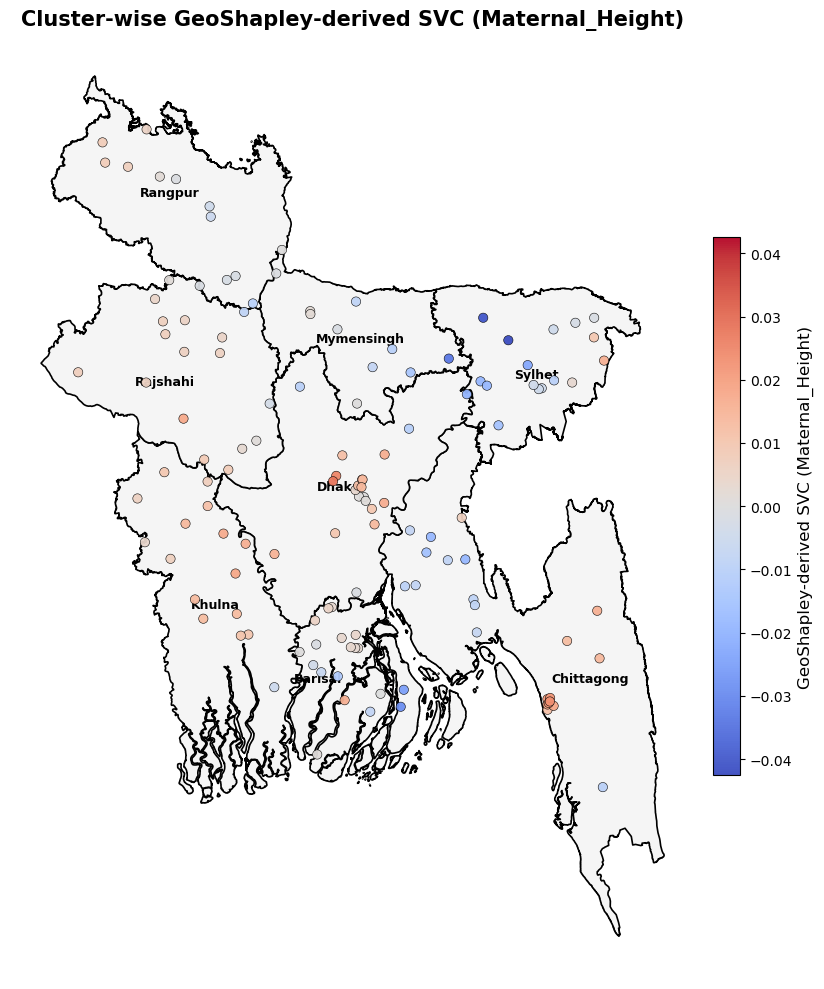

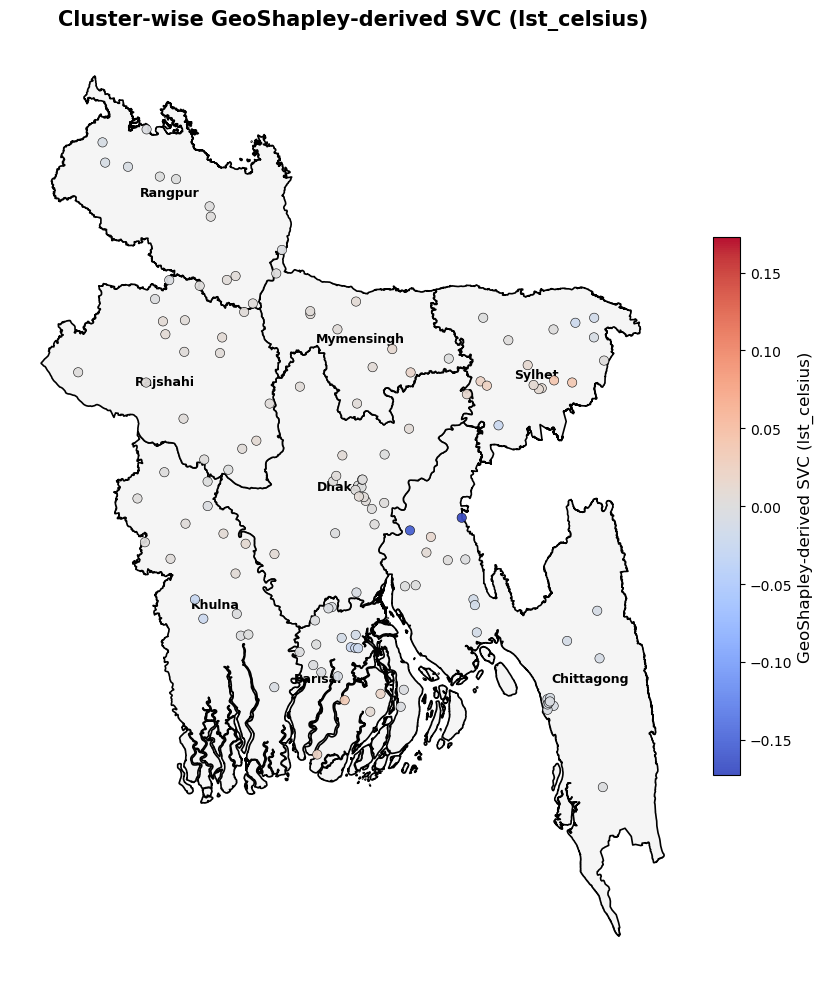

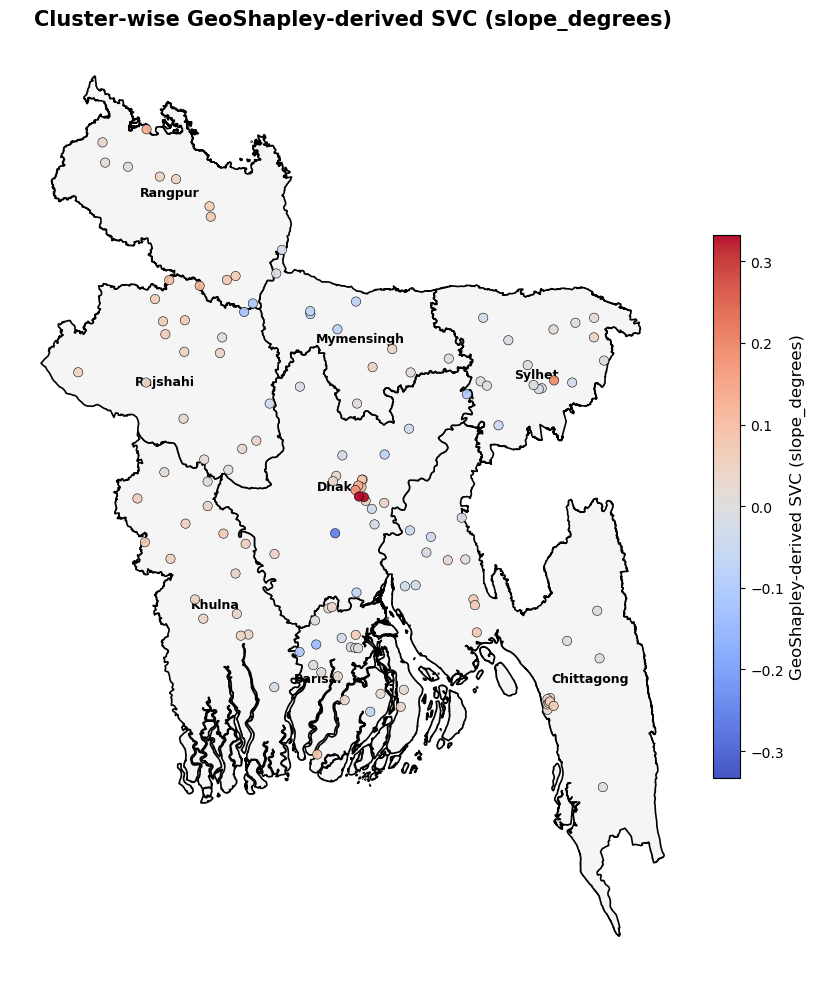

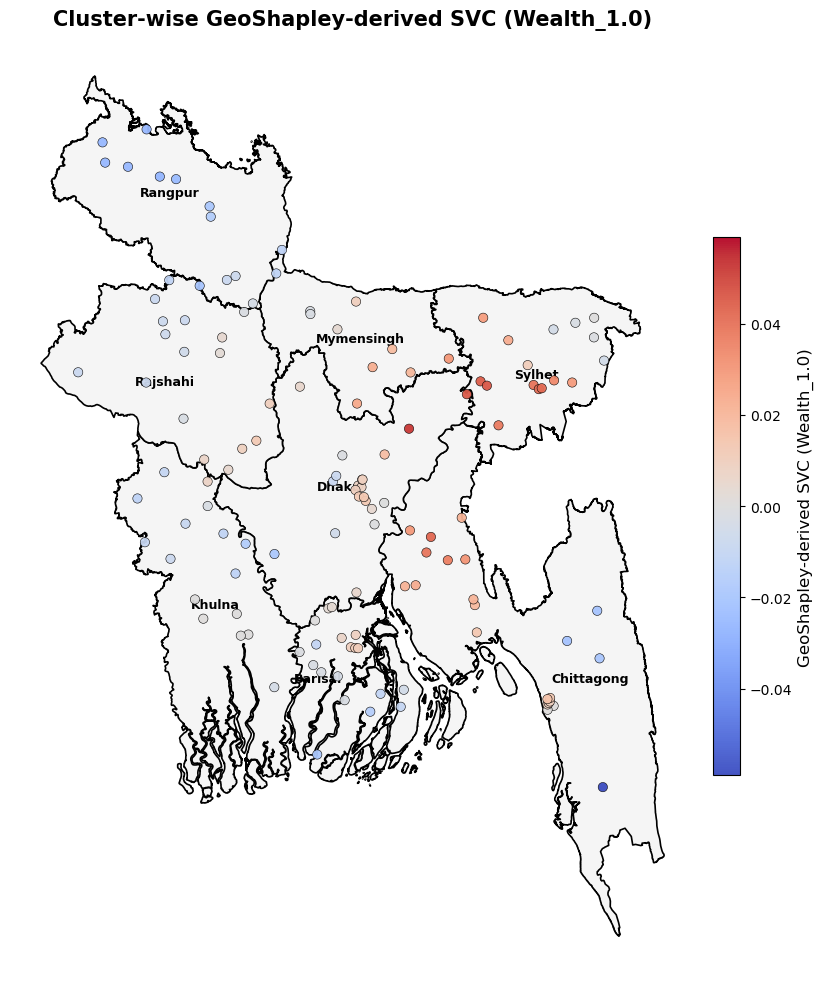

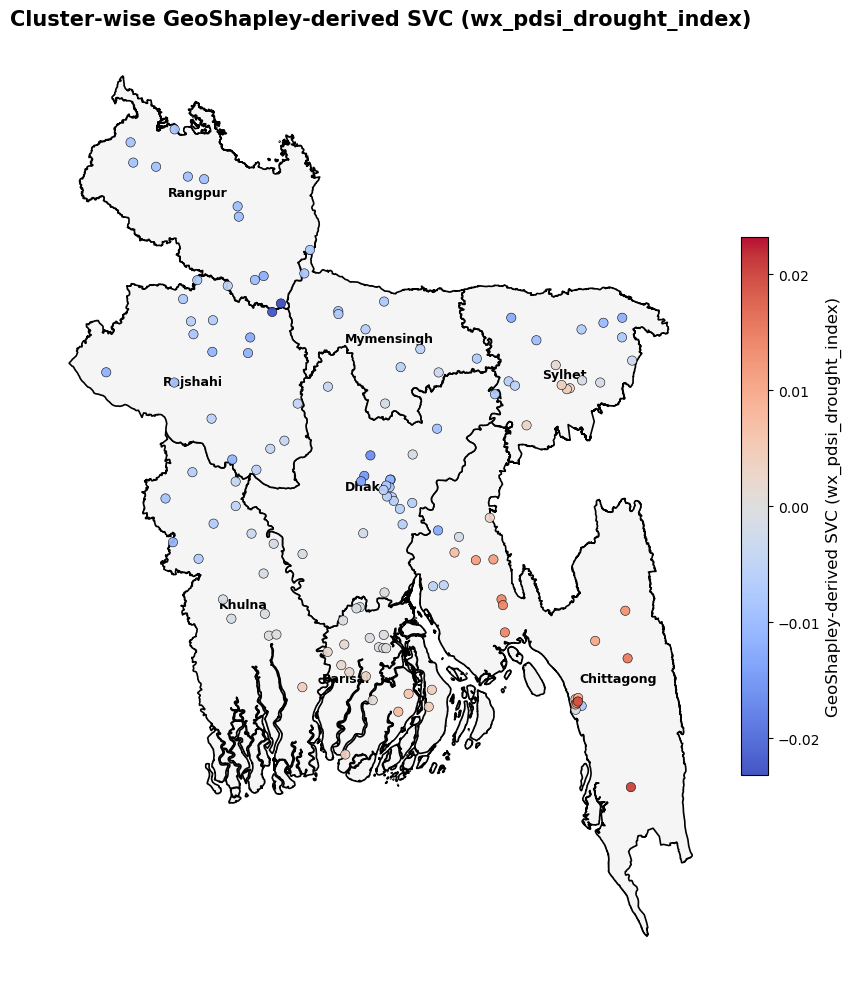

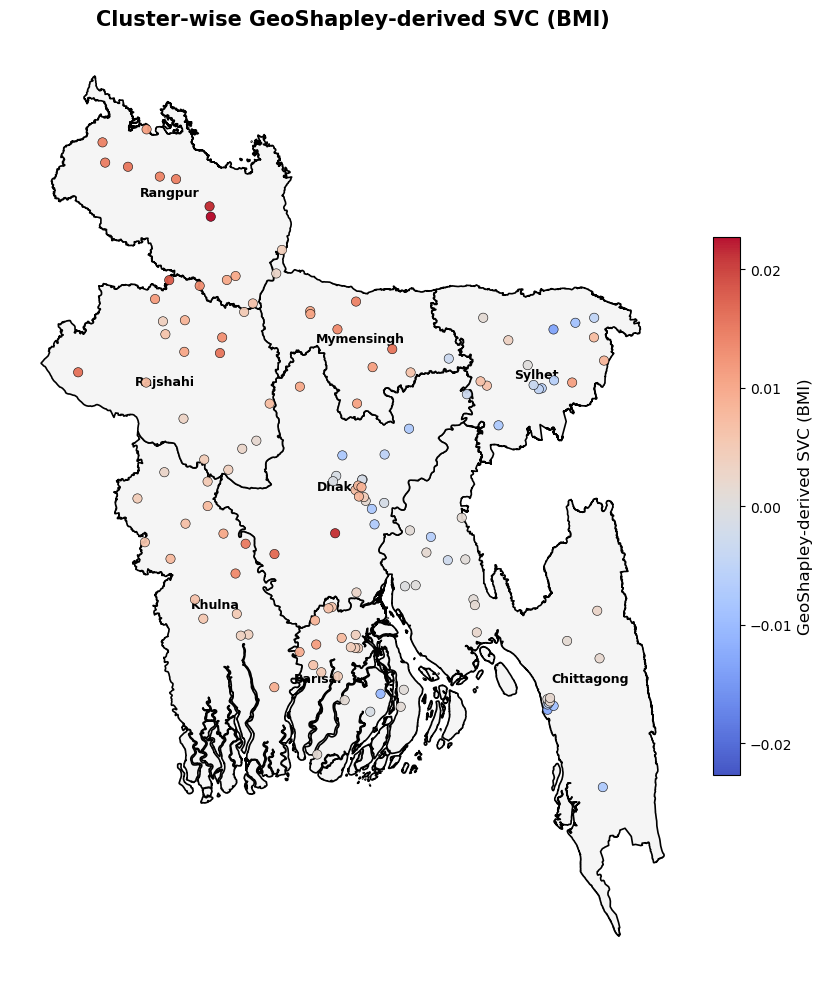

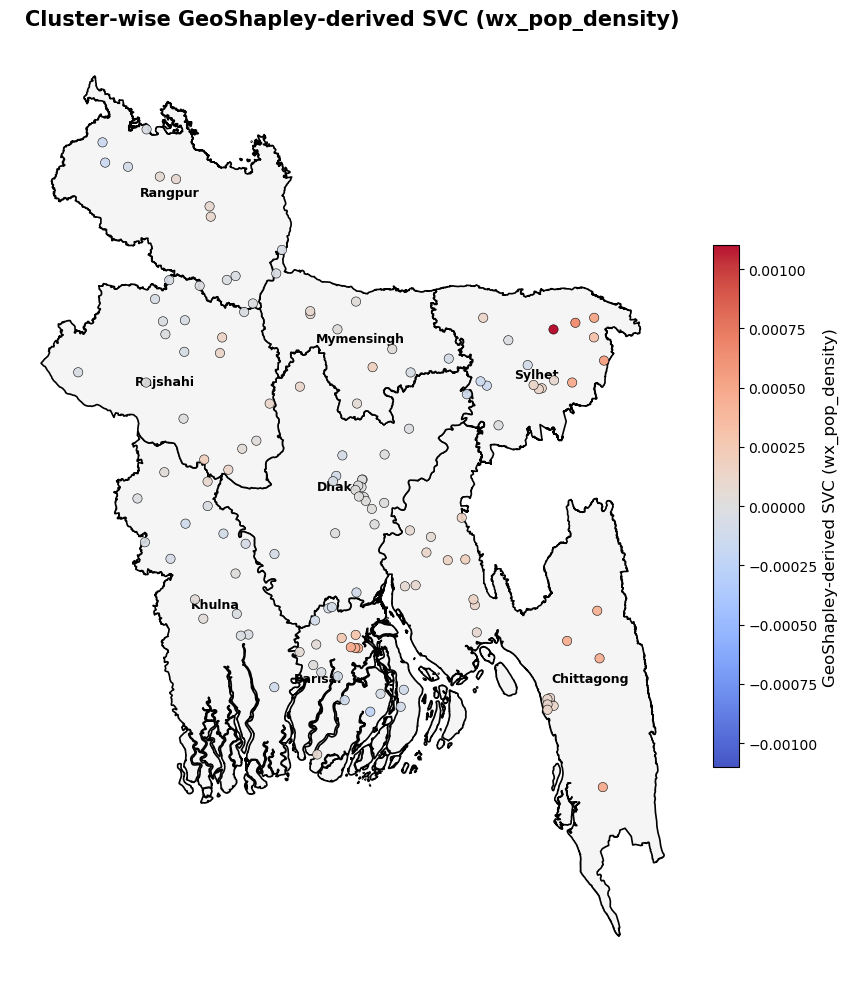

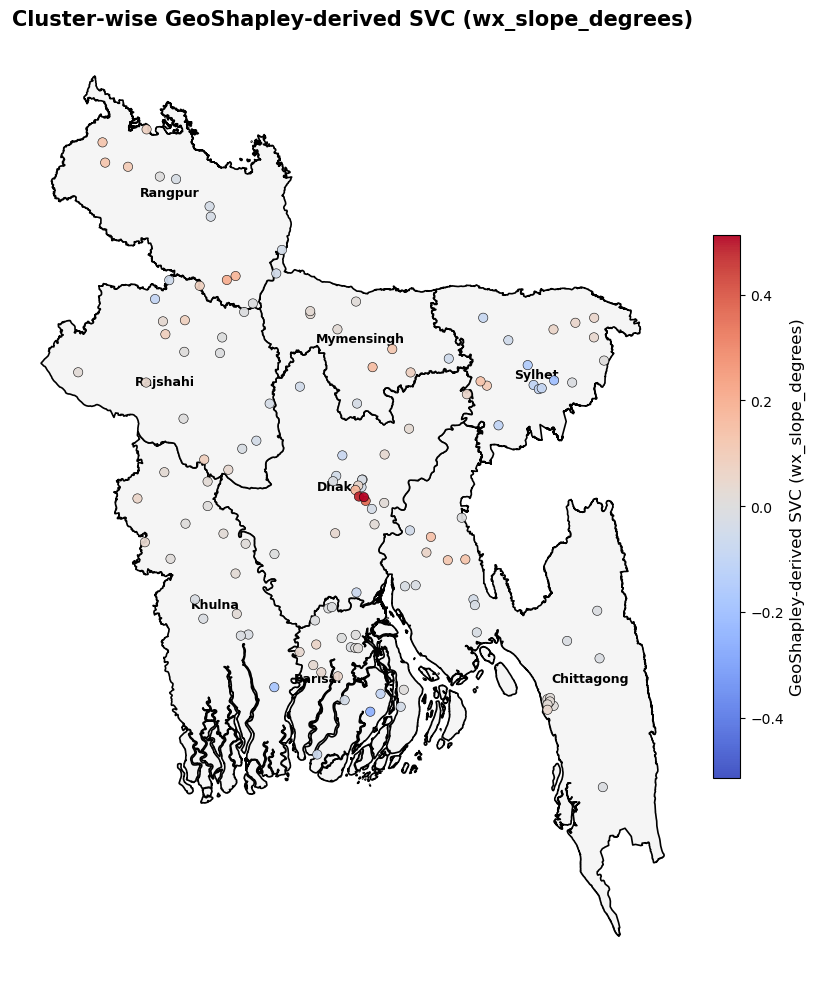

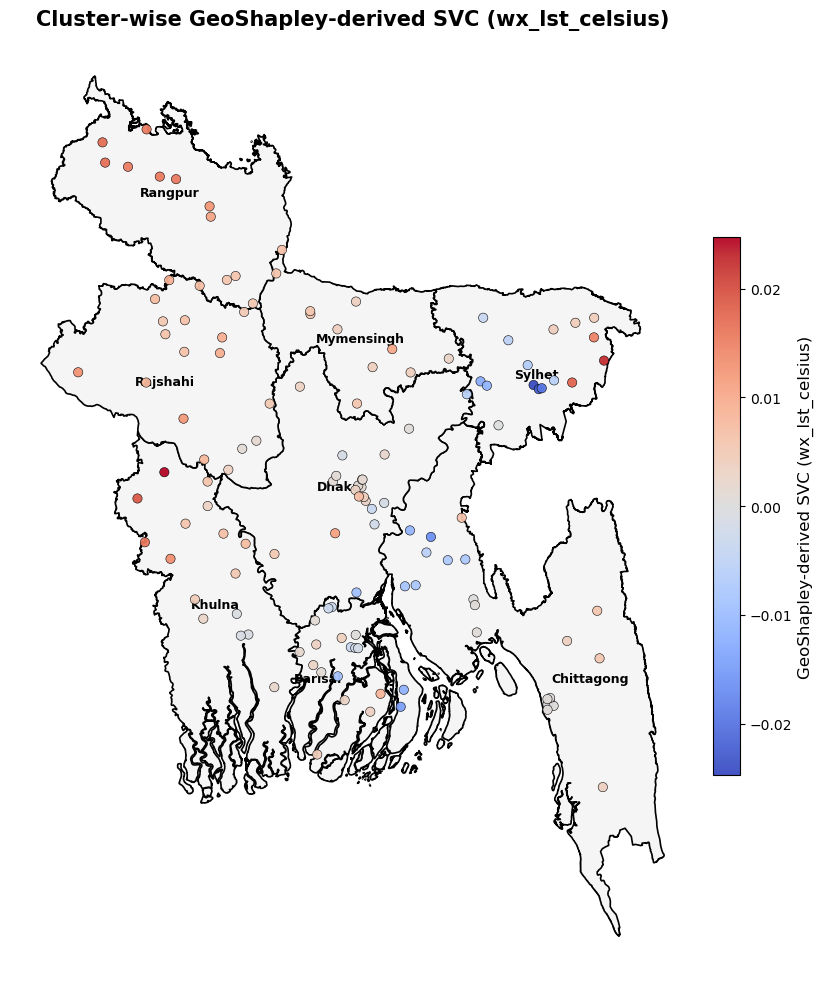

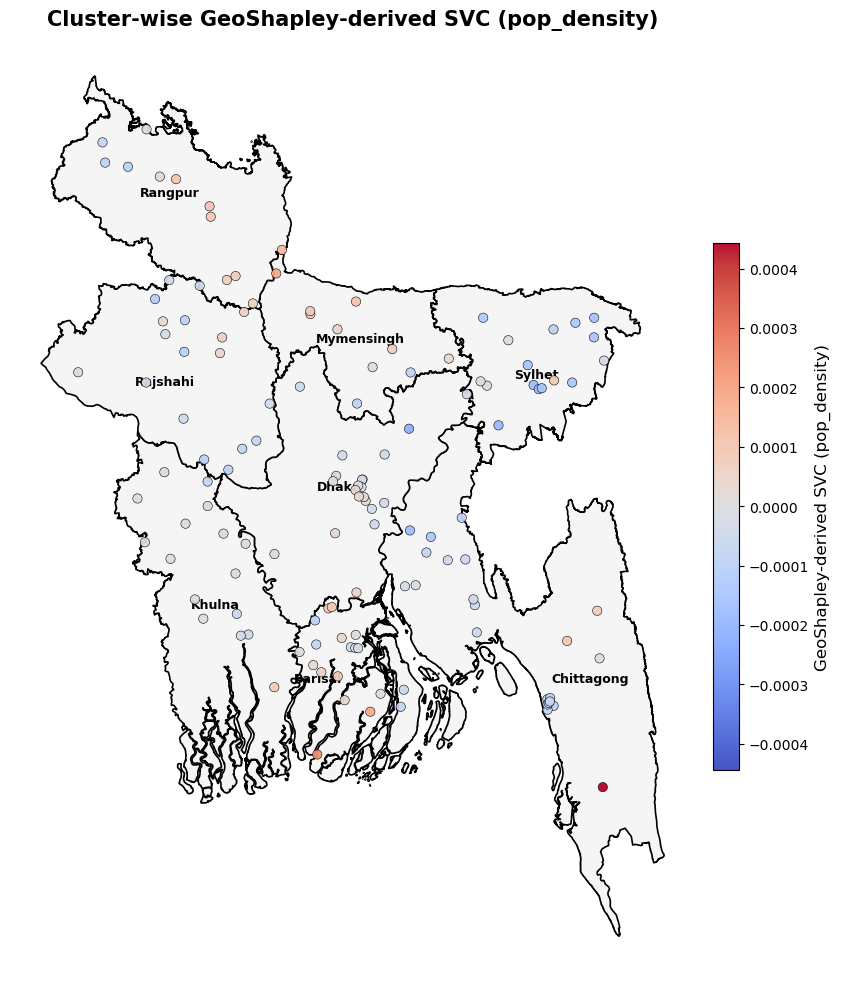


✓ Same GeoShapley SVC values are mapped; only plotting robustness and terminology were cleaned.


In [43]:
# ==========================================================
# Step-40 : Cluster-wise GeoShapley-Derived
#           Spatially Varying Coefficient (SVC) Maps
# ==========================================================

import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt


print("=" * 70)
print("GEOSHAPLEY-DERIVED SVC MAPS")
print("=" * 70)


# ==========================================================
# 1. LOAD BANGLADESH DIVISION BOUNDARY
# ==========================================================

divisions = gpd.read_file(

    r"F:\Thesis\GPS DATA\Division\gadm41_BGD_shp\gadm41_BGD_1.shp"
)


if divisions.crs is None:

    divisions = divisions.set_crs(

        "EPSG:4326",

        allow_override=True
    )

else:

    divisions = divisions.to_crs(
        "EPSG:4326"
    )


name_col = "NAME_1"


if name_col not in divisions.columns:

    raise RuntimeError(

        "Division-name column not found: "
        f"{name_col}"
    )


# ==========================================================
# 2. ONE SVC MAP PER FEATURE
# ==========================================================

for best_feature in svc_features:

    vals = (

        cluster_geo[
            best_feature
        ]

        .astype(
            float
        )

        .replace(
            [
                np.inf,
                -np.inf
            ],
            np.nan
        )
    )


    valid_vals = vals.dropna()


    if len(
        valid_vals
    ) == 0:

        abs_max = 1.0

    else:

        abs_max = max(

            abs(
                valid_vals.min()
            ),

            abs(
                valid_vals.max()
            )
        )


    if (
        not np.isfinite(
            abs_max
        )
        or
        abs_max <= 0
    ):

        abs_max = 1.0


    cluster_geo_sorted = (

        cluster_geo

        .sort_values(
            by=best_feature
        )

        .copy()
    )


    fig, ax = plt.subplots(
        figsize=(
            10,
            10
        )
    )


    divisions.plot(

        ax=ax,

        color="#f5f5f5",

        edgecolor="black",

        linewidth=1.2,

        zorder=1
    )


    sc = ax.scatter(

        cluster_geo_sorted[
            "lon"
        ],

        cluster_geo_sorted[
            "lat"
        ],

        c=
            cluster_geo_sorted[
                best_feature
            ],

        cmap="coolwarm",

        s=45,

        edgecolor="black",

        linewidth=0.4,

        alpha=0.95,

        vmin=
            -abs_max,

        vmax=
            abs_max,

        zorder=3
    )


    cb = plt.colorbar(

        sc,

        ax=ax,

        fraction=0.03,

        pad=0.02
    )


    cb.set_label(

        "GeoShapley-derived SVC "
        f"({best_feature})",

        fontsize=12
    )


    for _, row in divisions.iterrows():

        label_point = (
            row.geometry
            .representative_point()
        )


        ax.text(

            label_point.x,

            label_point.y,

            row[
                name_col
            ],

            ha="center",

            va="center",

            fontsize=9,

            fontweight="bold",

            zorder=2
        )


    ax.set_title(

        "Cluster-wise GeoShapley-derived SVC "
        f"({best_feature})",

        fontsize=15,

        fontweight="bold"
    )


    ax.set_xticks(
        []
    )

    ax.set_yticks(
        []
    )


    for spine in ax.spines.values():

        spine.set_visible(
            False
        )


    plt.tight_layout()


    safe_feature_name = (

        str(
            best_feature
        )

        .replace(
            "/",
            "_"
        )

        .replace(
            "\\",
            "_"
        )
    )


    plt.savefig(

        f"geoshapley_svc_map_"
        f"{safe_feature_name}.png",

        dpi=300,

        bbox_inches="tight"
    )


    plt.show()


print(
    "\n✓ Same GeoShapley SVC values are mapped; "
    "only plotting robustness and terminology "
    "were cleaned."
)

COMBINED GEOSHAPLEY-DERIVED SVC MAP
SVC features included: 10
Features: ['Maternal_Height', 'lst_celsius', 'slope_degrees', 'Wealth_1.0', 'wx_pdsi_drought_index', 'BMI', 'wx_pop_density', 'wx_slope_degrees', 'wx_lst_celsius', 'pop_density']
Figure layout: 4 rows × 3 columns


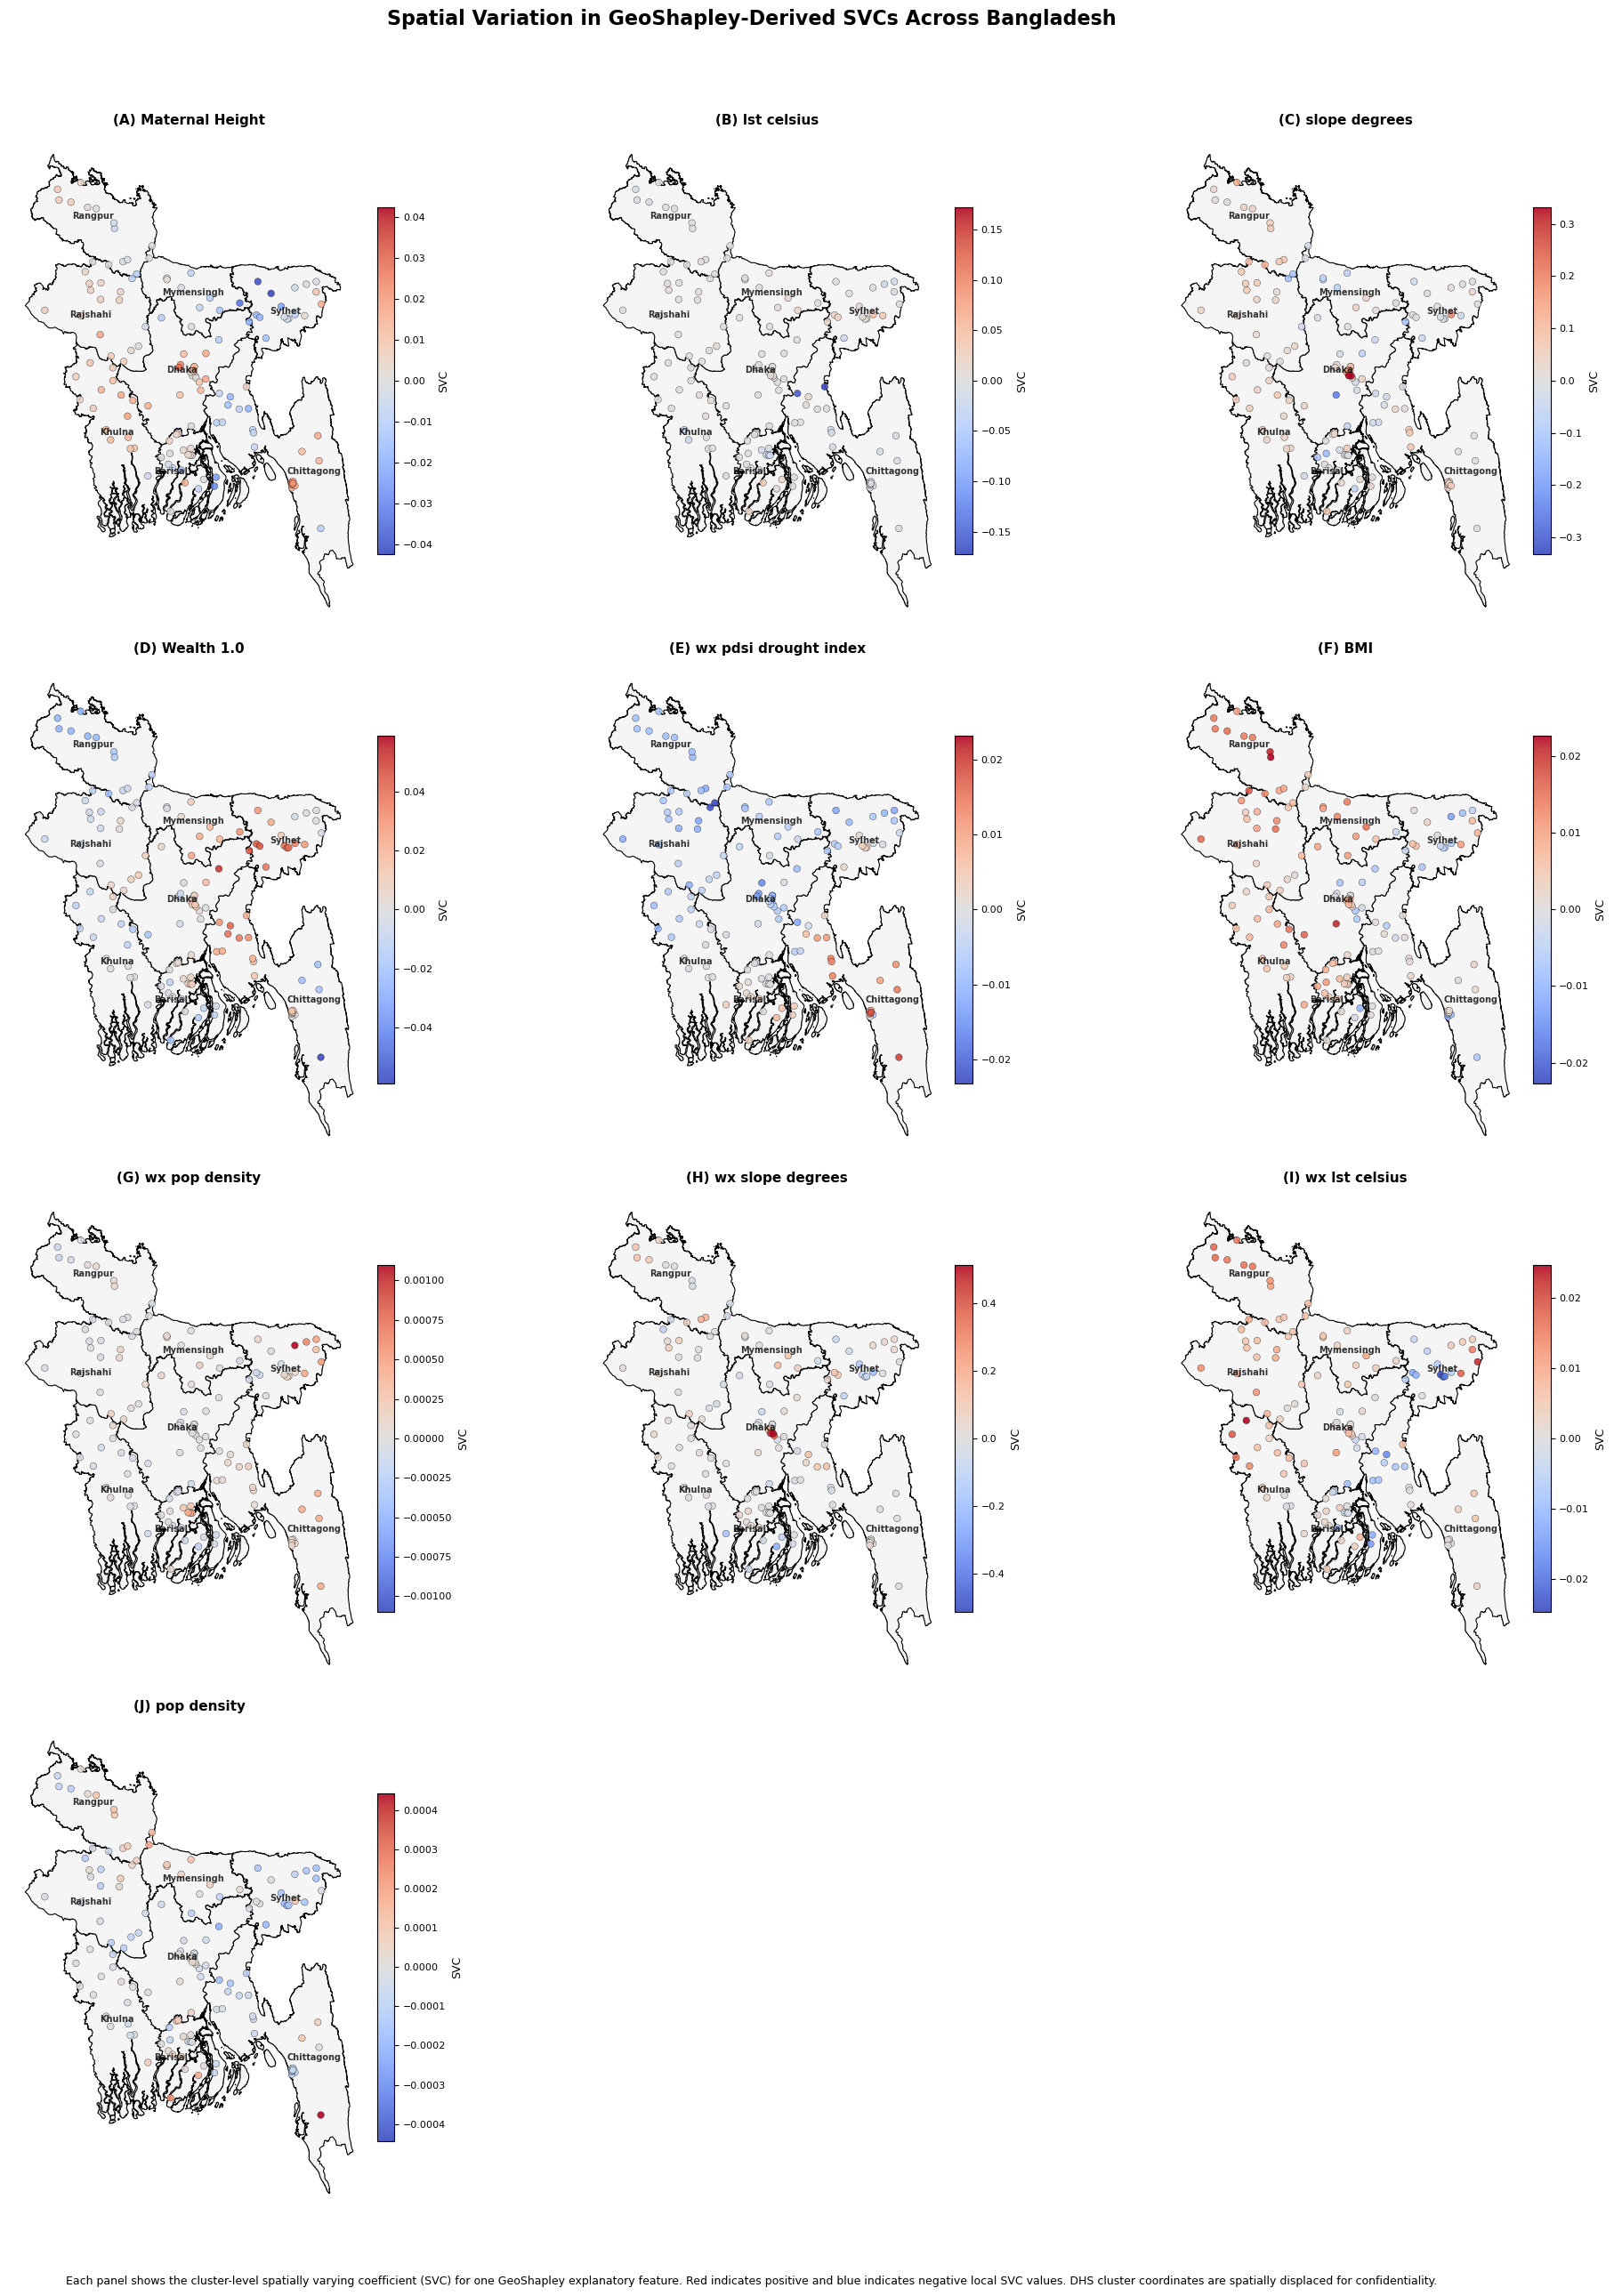


✓ All GeoShapley-derived SVC features are included.
✓ Only ONE combined map figure was generated.
✓ No SVC features were removed from the figure.
✓ Each feature retains its own symmetric SVC scale.
✓ Positive and negative SVC values remain visible.
✓ DHS displaced coordinates are interpreted only as cluster-level spatial approximations.

Saved figure:
geoshapley_combined_svc_map.png


In [44]:
# ==========================================================
# Step-40 : Combined GeoShapley-Derived SVC Map
#           ALL SVC FEATURES IN ONE FIGURE
# ==========================================================

import math
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt


print("=" * 70)
print("COMBINED GEOSHAPLEY-DERIVED SVC MAP")
print("=" * 70)


# ==========================================================
# 1. LOAD BANGLADESH DIVISION BOUNDARY
# ==========================================================

divisions = gpd.read_file(

    r"F:\Thesis\GPS DATA\Division\gadm41_BGD_shp\gadm41_BGD_1.shp"
)


if divisions.crs is None:

    divisions = divisions.set_crs(

        "EPSG:4326",

        allow_override=True
    )

else:

    divisions = divisions.to_crs(
        "EPSG:4326"
    )


name_col = "NAME_1"


if name_col not in divisions.columns:

    raise RuntimeError(

        "Division-name column not found: "
        f"{name_col}"
    )


# ==========================================================
# 2. FIGURE LAYOUT
# ==========================================================

n_features = len(
    svc_features
)


if n_features == 0:

    raise RuntimeError(
        "No SVC features are available for mapping."
    )


if n_features == 1:

    ncols = 1

elif n_features <= 4:

    ncols = 2

else:

    ncols = 3


nrows = math.ceil(

    n_features

    /

    ncols
)


print(
    "SVC features included:",
    n_features
)


print(
    "Features:",
    svc_features
)


print(
    "Figure layout:",
    f"{nrows} rows × {ncols} columns"
)


# ==========================================================
# 3. CREATE FIGURE
# ==========================================================

fig, axes = plt.subplots(

    nrows=nrows,

    ncols=ncols,

    figsize=(
        6.5 * ncols,
        6.5 * nrows
    )
)


axes = np.atleast_1d(
    axes
).ravel()


# ==========================================================
# 4. PLOT ALL SVC FEATURES
# ==========================================================

for panel_idx, best_feature in enumerate(
    svc_features
):

    ax = axes[
        panel_idx
    ]


    vals = (

        cluster_geo[
            best_feature
        ]

        .astype(
            float
        )

        .replace(
            [
                np.inf,
                -np.inf
            ],
            np.nan
        )
    )


    valid_vals = vals.dropna()


    if len(
        valid_vals
    ) == 0:

        abs_max = 1.0

    else:

        abs_max = max(

            abs(
                valid_vals.min()
            ),

            abs(
                valid_vals.max()
            )
        )


    if (
        not np.isfinite(
            abs_max
        )
        or
        abs_max == 0
    ):

        abs_max = 1.0


    cluster_geo_sorted = (

        cluster_geo

        .sort_values(
            by=best_feature
        )

        .copy()
    )


    divisions.plot(

        ax=ax,

        color="#f5f5f5",

        edgecolor="black",

        linewidth=0.8
    )


    sc = ax.scatter(

        cluster_geo_sorted[
            "lon"
        ],

        cluster_geo_sorted[
            "lat"
        ],

        c=
            cluster_geo_sorted[
                best_feature
            ],

        cmap="coolwarm",

        s=30,

        edgecolor="black",

        linewidth=0.25,

        alpha=0.9,

        vmin=
            -abs_max,

        vmax=
            abs_max
    )


    cb = fig.colorbar(

        sc,

        ax=ax,

        fraction=0.035,

        pad=0.015
    )


    cb.set_label(

        "SVC",

        fontsize=9
    )


    cb.ax.tick_params(
        labelsize=8
    )


    for _, row in divisions.iterrows():

        label_point = (

            row.geometry

            .representative_point()
        )


        ax.text(

            label_point.x,

            label_point.y,

            row[
                name_col
            ],

            ha="center",

            va="center",

            fontsize=7,

            fontweight="bold",

            alpha=0.8
        )


    panel_letter = chr(
        65 + panel_idx
    )


    clean_feature_name = (

        str(
            best_feature
        )

        .replace(
            "_",
            " "
        )
    )


    ax.set_title(

        f"({panel_letter}) "
        f"{clean_feature_name}",

        fontsize=11,

        fontweight="bold"
    )


    ax.set_xticks(
        []
    )

    ax.set_yticks(
        []
    )


    for spine in ax.spines.values():

        spine.set_visible(
            False
        )


# ==========================================================
# 5. REMOVE EMPTY PANELS
# ==========================================================

for empty_idx in range(

    n_features,

    len(
        axes
    )
):

    axes[
        empty_idx
    ].axis(
        "off"
    )


# ==========================================================
# 6. TITLE
# ==========================================================

fig.suptitle(

    "Spatial Variation in GeoShapley-Derived "
    "SVCs Across Bangladesh",

    fontsize=16,

    fontweight="bold",

    y=0.995
)


# ==========================================================
# 7. FIGURE NOTE
# ==========================================================

fig.text(

    0.5,

    0.01,

    (
        "Each panel shows the cluster-level "
        "spatially varying coefficient (SVC) "
        "for one GeoShapley explanatory feature. "
        "Red indicates positive and blue indicates "
        "negative local SVC values. DHS cluster "
        "coordinates are spatially displaced "
        "for confidentiality."
    ),

    ha="center",

    va="bottom",

    fontsize=9,

    wrap=True
)


plt.tight_layout(

    rect=[
        0,
        0.035,
        1,
        0.97
    ]
)


plt.savefig(

    "geoshapley_combined_svc_map.png",

    dpi=300,

    bbox_inches="tight"
)


plt.show()


# ==========================================================
# 8. AUDIT
# ==========================================================

print(
    "\n✓ All GeoShapley-derived SVC "
    "features are included."
)

print(
    "✓ Only ONE combined map figure "
    "was generated."
)

print(
    "✓ No SVC features were removed "
    "from the figure."
)

print(
    "✓ Each feature retains its own "
    "symmetric SVC scale."
)

print(
    "✓ Positive and negative SVC values "
    "remain visible."
)

print(
    "✓ DHS displaced coordinates are "
    "interpreted only as cluster-level "
    "spatial approximations."
)

print(
    "\nSaved figure:"
)

print(
    "geoshapley_combined_svc_map.png"
)

ONE READABLE GEOSHAPLEY SVC MAP


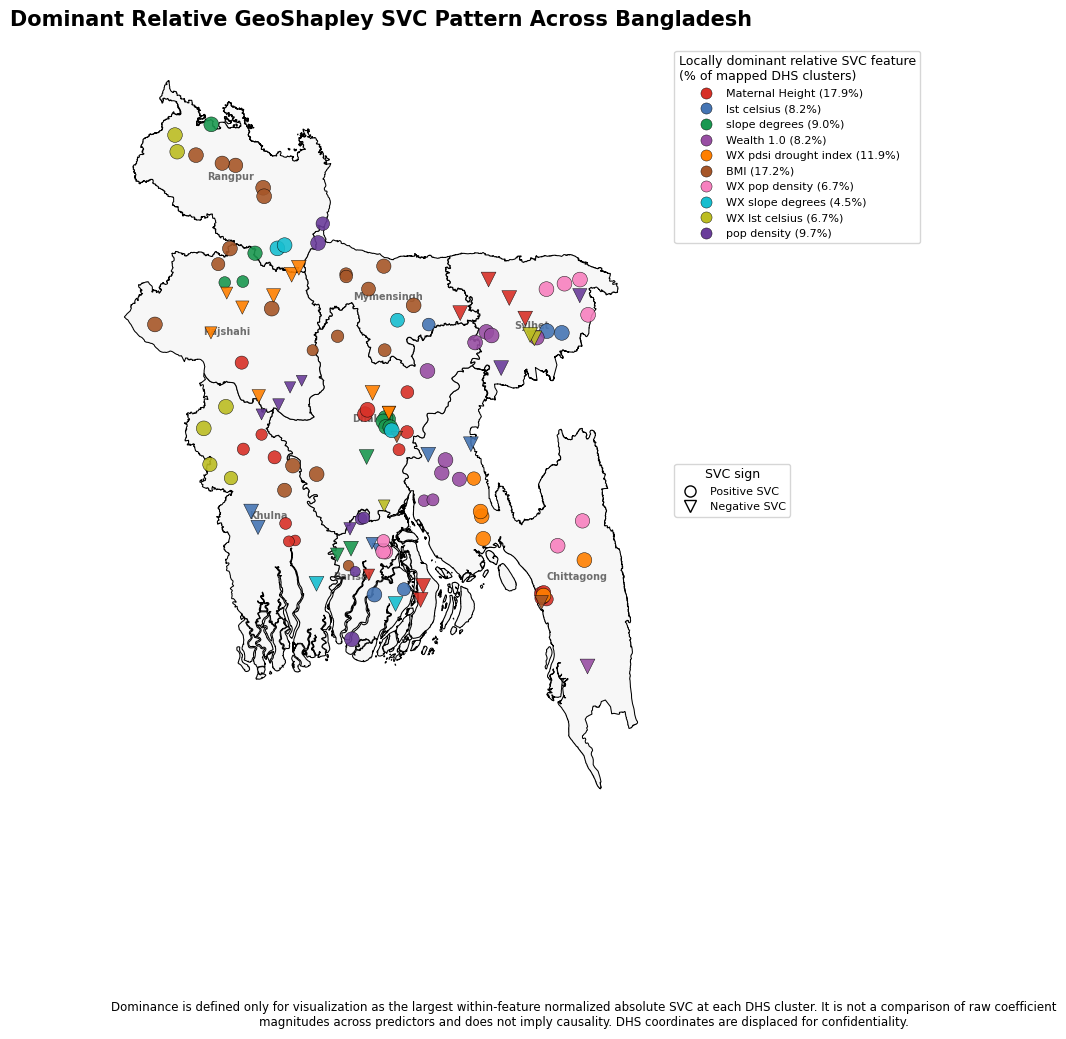


✓ Every SVC feature participates in the relative within-feature comparison.
✓ Raw SVC values are unchanged.
✓ One marker is plotted per DHS cluster.
✓ Map terminology describes a relative SVC pattern, not a causal effect or raw cross-feature ranking.

Saved figure:
geoshapley_dominant_relative_svc_map.png


In [45]:
# ==========================================================
# Step-40 : ONE READABLE GeoShapley Map
#           Dominant Relative GeoShapley SVC Pattern
#           by DHS Cluster
#
# ALL svc_features are included.
#
# Colour = locally dominant relative SVC feature
# Shape  = sign of raw SVC
# Size   = within-feature relative |SVC| strength
#
# IMPORTANT:
# This is a visualization summary.
# It is NOT a causal ranking and does NOT compare
# raw coefficient magnitudes across predictors.
# ==========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.lines import Line2D


print("=" * 75)
print("ONE READABLE GEOSHAPLEY SVC MAP")
print("=" * 75)


# ==========================================================
# 1. CHECKS
# ==========================================================

if "svc_features" not in globals():

    raise RuntimeError(
        "svc_features not found. Run Step-39 first."
    )


if "cluster_geo" not in globals():

    raise RuntimeError(
        "cluster_geo not found. Run Step-39 first."
    )


if "divisions" not in globals():

    raise RuntimeError(
        "divisions not found. "
        "Run the SVC map step first."
    )


if len(
    svc_features
) == 0:

    raise RuntimeError(
        "No GeoShapley SVC features are available."
    )


for col in [
    "lon",
    "lat"
]:

    if col not in cluster_geo.columns:

        raise RuntimeError(
            f"Missing coordinate column: {col}"
        )


for feature in svc_features:

    if feature not in cluster_geo.columns:

        raise RuntimeError(
            "SVC feature missing from cluster_geo: "
            f"{feature}"
        )


# ==========================================================
# 2. FEATURE COLOURS
# ==========================================================

feature_colors = [

    "#D73027",
    "#4575B4",
    "#1A9850",
    "#984EA3",
    "#FF7F00",
    "#A65628",
    "#F781BF",
    "#17BECF",
    "#BCBD22",
    "#6A3D9A",
    "#1B9E77",
    "#E7298A",
    "#7570B3",
    "#66A61E"
]


if len(
    svc_features
) > len(
    feature_colors
):

    raise RuntimeError(
        "More SVC features than available colours."
    )


feature_color_map = {

    feature:
        feature_colors[
            i
        ]

    for i, feature
    in enumerate(
        svc_features
    )
}


# ==========================================================
# 3. RAW SVC MATRIX
# ==========================================================

svc_raw = (

    cluster_geo[
        svc_features
    ]

    .astype(
        float
    )

    .replace(
        [
            np.inf,
            -np.inf
        ],
        np.nan
    )
)


# ==========================================================
# 4. WITHIN-FEATURE RELATIVE STRENGTH
#
# |SVC| / 95th percentile |SVC|
#
# Capped at 1.
#
# This normalization is ONLY for map visualization.
# Raw SVC values remain unchanged.
# ==========================================================

relative_strength = pd.DataFrame(

    index=
        cluster_geo.index,

    columns=
        svc_features,

    dtype=float
)


feature_scale = {}


for feature in svc_features:

    abs_values = (

        svc_raw[
            feature
        ].abs()
    )


    valid_values = (

        abs_values[
            np.isfinite(
                abs_values
            )
        ]
    )


    if len(
        valid_values
    ) == 0:

        scale = 1.0

    else:

        scale = float(

            np.nanpercentile(
                valid_values,
                95
            )
        )


    if (
        not np.isfinite(
            scale
        )
        or
        scale <= 0
    ):

        if len(
            valid_values
        ) > 0:

            scale = float(

                np.nanmax(
                    valid_values
                )
            )


    if (
        not np.isfinite(
            scale
        )
        or
        scale <= 0
    ):

        scale = 1.0


    feature_scale[
        feature
    ] = scale


    relative_strength[
        feature
    ] = (

        abs_values

        /

        scale

    ).clip(
        lower=0,
        upper=1
    )


# ==========================================================
# 5. LOCALLY DOMINANT RELATIVE SVC FEATURE
# ==========================================================

valid_row = (

    relative_strength

    .notna()

    .any(
        axis=1
    )
)


dominant_feature = pd.Series(

    index=
        cluster_geo.index,

    dtype="object"
)


dominant_feature.loc[
    valid_row
] = (

    relative_strength

    .loc[
        valid_row
    ]

    .idxmax(
        axis=1
    )
)


dominant_raw_svc = pd.Series(

    np.nan,

    index=
        cluster_geo.index,

    dtype=float
)


dominant_strength = pd.Series(

    np.nan,

    index=
        cluster_geo.index,

    dtype=float
)


for idx in cluster_geo.index:

    feature = (
        dominant_feature.loc[
            idx
        ]
    )


    if pd.isna(
        feature
    ):

        continue


    dominant_raw_svc.loc[
        idx
    ] = (

        svc_raw.loc[
            idx,
            feature
        ]
    )


    dominant_strength.loc[
        idx
    ] = (

        relative_strength.loc[
            idx,
            feature
        ]
    )


dominant_direction = pd.Series(

    np.nan,

    index=
        cluster_geo.index,

    dtype="object"
)


dominant_direction.loc[
    dominant_raw_svc
    >=
    0
] = "Positive"


dominant_direction.loc[
    dominant_raw_svc
    <
    0
] = "Negative"


# ==========================================================
# 6. SAVE MAPPING VARIABLES
# ==========================================================

cluster_geo[
    "dominant_svc_feature"
] = dominant_feature


cluster_geo[
    "dominant_svc_value"
] = dominant_raw_svc


cluster_geo[
    "dominant_relative_strength"
] = dominant_strength


cluster_geo[
    "dominant_direction"
] = dominant_direction


marker_sizes = (

    24

    +

    90
    *
    dominant_strength
    .fillna(0)
    .to_numpy()
)


# ==========================================================
# 7. MAP
# ==========================================================

fig, ax = plt.subplots(

    figsize=(
        10,
        12
    )
)


divisions.plot(

    ax=ax,

    color="#F7F7F7",

    edgecolor="black",

    linewidth=0.75,

    zorder=1
)


for feature in svc_features:

    feature_color = (

        feature_color_map[
            feature
        ]
    )


    # Positive SVC
    mask_positive = (

        (
            dominant_feature
            ==
            feature
        )

        &

        (
            dominant_direction
            ==
            "Positive"
        )
    )


    if (
        mask_positive.sum()
        >
        0
    ):

        ax.scatter(

            cluster_geo.loc[
                mask_positive,
                "lon"
            ],

            cluster_geo.loc[
                mask_positive,
                "lat"
            ],

            s=
                marker_sizes[
                    mask_positive.to_numpy()
                ],

            marker="o",

            facecolor=
                feature_color,

            edgecolor="black",

            linewidth=0.35,

            alpha=0.9,

            zorder=4
        )


    # Negative SVC
    mask_negative = (

        (
            dominant_feature
            ==
            feature
        )

        &

        (
            dominant_direction
            ==
            "Negative"
        )
    )


    if (
        mask_negative.sum()
        >
        0
    ):

        ax.scatter(

            cluster_geo.loc[
                mask_negative,
                "lon"
            ],

            cluster_geo.loc[
                mask_negative,
                "lat"
            ],

            s=
                marker_sizes[
                    mask_negative.to_numpy()
                ],

            marker="v",

            facecolor=
                feature_color,

            edgecolor="black",

            linewidth=0.35,

            alpha=0.9,

            zorder=4
        )


# ==========================================================
# 8. DIVISION LABELS
# ==========================================================

if "NAME_1" in divisions.columns:

    for _, row in divisions.iterrows():

        p = (
            row.geometry
            .representative_point()
        )


        ax.text(

            p.x,

            p.y,

            row[
                "NAME_1"
            ],

            fontsize=7,

            fontweight="bold",

            ha="center",

            va="center",

            color="#333333",

            alpha=0.7,

            zorder=2
        )


# ==========================================================
# 9. LEGENDS
# ==========================================================

def clean_feature_name(
    feature
):

    name = (

        str(
            feature
        )

        .replace(
            "_",
            " "
        )
    )


    if name.lower().startswith(
        "wx "
    ):

        name = (
            "WX "
            +
            name[3:]
        )


    return name


valid_dominant = (
    dominant_feature
    .dropna()
)


feature_percentages = (

    valid_dominant

    .value_counts(
        normalize=True
    )

    *
    100
)


feature_handles = []


for feature in svc_features:

    percentage = (

        feature_percentages

        .get(
            feature,
            0.0
        )
    )


    feature_handles.append(

        Line2D(

            [0],
            [0],

            marker="o",

            linestyle="None",

            markerfacecolor=
                feature_color_map[
                    feature
                ],

            markeredgecolor="black",

            markeredgewidth=0.3,

            markersize=8,

            label=(
                f"{clean_feature_name(feature)} "
                f"({percentage:.1f}%)"
            )
        )
    )


feature_legend = ax.legend(

    handles=
        feature_handles,

    title=(
        "Locally dominant relative SVC feature\n"
        "(% of mapped DHS clusters)"
    ),

    loc="upper left",

    bbox_to_anchor=(
        1.01,
        1.0
    ),

    frameon=True,

    fontsize=8,

    title_fontsize=9
)


ax.add_artist(
    feature_legend
)


direction_handles = [

    Line2D(

        [0],
        [0],

        marker="o",

        linestyle="None",

        markerfacecolor="white",

        markeredgecolor="black",

        markersize=8,

        label="Positive SVC"
    ),

    Line2D(

        [0],
        [0],

        marker="v",

        linestyle="None",

        markerfacecolor="white",

        markeredgecolor="black",

        markersize=8,

        label="Negative SVC"
    )
]


ax.legend(

    handles=
        direction_handles,

    title=
        "SVC sign",

    loc=
        "upper left",

    bbox_to_anchor=(
        1.01,
        0.47
    ),

    frameon=True,

    fontsize=8,

    title_fontsize=9
)


# ==========================================================
# 10. FINAL STYLING
# ==========================================================

ax.set_title(

    "Dominant Relative GeoShapley SVC Pattern "
    "Across Bangladesh",

    fontsize=15,

    fontweight="bold",

    pad=14
)


ax.set_xticks(
    []
)

ax.set_yticks(
    []
)


for spine in ax.spines.values():

    spine.set_visible(
        False
    )


fig.text(

    0.5,

    0.02,

    (
        "Dominance is defined only for visualization "
        "as the largest within-feature normalized "
        "absolute SVC at each DHS cluster. It is not "
        "a comparison of raw coefficient magnitudes "
        "across predictors and does not imply causality. "
        "DHS coordinates are displaced for confidentiality."
    ),

    ha="center",

    va="bottom",

    fontsize=8.5,

    wrap=True
)


plt.tight_layout(

    rect=[
        0,
        0.06,
        0.80,
        1
    ]
)


plt.savefig(

    "geoshapley_dominant_relative_svc_map.png",

    dpi=300,

    bbox_inches="tight"
)


plt.show()


# ==========================================================
# 11. AUDIT
# ==========================================================

print(
    "\n✓ Every SVC feature participates in "
    "the relative within-feature comparison."
)


print(
    "✓ Raw SVC values are unchanged."
)


print(
    "✓ One marker is plotted per DHS cluster."
)


print(
    "✓ Map terminology describes a relative "
    "SVC pattern, not a causal effect or raw "
    "cross-feature ranking."
)


print(
    "\nSaved figure:"
)


print(
    "geoshapley_dominant_relative_svc_map.png"
)

In [47]:
# ============================================================
# REVIEWER UPDATE STEP — GB/CatBoost PIPELINE
#
# Addresses:
# Comment 12 — complete classifier performance table
# Comment 3  — export standardized held-out comparison bundle
#
# Run AFTER the entire original GB notebook.
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
import joblib


# ============================================================
# 1. OUTPUT DIRECTORY
# ============================================================

REVIEWER_DIR = Path(
    r"F:\Thesis\Reviewer_Additional_Analyses"
)

REVIEWER_DIR.mkdir(
    parents=True,
    exist_ok=True
)


print("=" * 80)
print("GB/CatBoost — REVIEWER UPDATE")
print("=" * 80)


# ============================================================
# 2. REQUIRED OBJECTS
# ============================================================

required_objects = [
    "default_df",
    "test_idx",
    "y_test",
    "groups_test",
    "strata_test",
    "weights_test",
    "y_prob"
]

missing_objects = [
    x
    for x in required_objects
    if x not in globals()
]


if missing_objects:

    raise RuntimeError(
        "Missing required object(s):\n"
        + "\n".join(missing_objects)
        + "\n\nRun the complete GB notebook first."
    )


# ============================================================
# PART A
# COMMENT 12 — COMPLETE CLASSIFIER PERFORMANCE
# ============================================================

print("\n" + "=" * 80)
print("COMMENT 12 — COMPLETE CLASSIFIER PERFORMANCE")
print("=" * 80)


desired_columns = [
    "Model",
    "Mean_Fold_AUC",
    "SD_Fold_AUC",
    "Accuracy",
    "Balanced_Accuracy",
    "Precision",
    "Recall",
    "Specificity",
    "F1",
    "Kappa",
    "MCC",
    "AUC",
    "AUC_CI_Lower",
    "AUC_CI_Upper",
    "Average_Precision",
    "Brier",
    "LogLoss"
]


available_columns = [
    c
    for c in desired_columns
    if c in default_df.columns
]


gb_classifier_table = (
    default_df[
        available_columns
    ]
    .copy()
    .reset_index(drop=True)
)


if "Recall" in gb_classifier_table.columns:

    gb_classifier_table = (
        gb_classifier_table.rename(
            columns={
                "Recall": "Sensitivity"
            }
        )
    )


gb_classifier_table.insert(
    0,
    "Predictive_Pipeline",
    "GB/CatBoost predictive pipeline"
)


if "Mean_Fold_AUC" in gb_classifier_table.columns:

    gb_classifier_table = (
        gb_classifier_table
        .sort_values(
            "Mean_Fold_AUC",
            ascending=False
        )
        .reset_index(drop=True)
    )


gb_classifier_table.insert(
    1,
    "Development_CV_Rank",
    np.arange(
        1,
        len(gb_classifier_table) + 1
    )
)


display(
    gb_classifier_table.round(4)
)


print(
    "\nNumber of classifier rows:",
    len(gb_classifier_table)
)


comment12_file = (
    REVIEWER_DIR
    /
    "Comment12_GB_CatBoost_full_classifier_performance.csv"
)


gb_classifier_table.to_csv(
    comment12_file,
    index=False
)


print("\nSaved:")
print(comment12_file)


# ============================================================
# PART B
# COMMENT 3 — STANDARDIZED PIPELINE COMPARISON BUNDLE
# ============================================================

print("\n" + "=" * 80)
print("COMMENT 3 — EXPORT GB COMPARISON BUNDLE")
print("=" * 80)


gb_bundle = {

    "pipeline":
        "GB/CatBoost",

    "test_idx":
        np.asarray(
            test_idx
        ).copy(),

    "y":
        np.asarray(
            y_test,
            dtype=int
        ).copy(),

    "psu":
        np.asarray(
            groups_test
        ).copy(),

    "strata":
        np.asarray(
            strata_test
        ).copy(),

    "weights":
        np.asarray(
            weights_test,
            dtype=float
        ).copy(),

    "prob":
        np.asarray(
            y_prob,
            dtype=float
        ).copy()
}


n = len(
    gb_bundle["y"]
)


for key in [
    "test_idx",
    "psu",
    "strata",
    "weights",
    "prob"
]:

    if len(
        gb_bundle[key]
    ) != n:

        raise RuntimeError(
            f"Length mismatch for {key}."
        )


if not np.isfinite(
    gb_bundle["weights"]
).all():

    raise RuntimeError(
        "Non-finite survey weights detected."
    )


if not np.isfinite(
    gb_bundle["prob"]
).all():

    raise RuntimeError(
        "Non-finite probabilities detected."
    )


gb_bundle_file = (
    REVIEWER_DIR
    /
    "Comment3_GB_CatBoost_comparison_bundle.pkl"
)


joblib.dump(
    gb_bundle,
    gb_bundle_file
)


print(
    "Held-out comparative-test N:",
    n
)

print(
    "Positive cases:",
    int(
        np.sum(
            gb_bundle["y"] == 1
        )
    )
)

print(
    "Unique PSUs:",
    len(
        np.unique(
            gb_bundle["psu"]
        )
    )
)

print(
    "Survey strata:",
    len(
        np.unique(
            gb_bundle["strata"]
        )
    )
)


print("\nSaved:")
print(gb_bundle_file)


print("\n" + "=" * 80)
print("GB REVIEWER UPDATE COMPLETE")
print("=" * 80)

print(
    "✓ Comment 12 table exported."
)

print(
    "✓ Comment 3 comparison bundle exported."
)

print(
    "✓ No model was retrained."
)

print(
    "✓ Existing held-out comparative-test predictions unchanged."
)

GB/CatBoost — REVIEWER UPDATE

COMMENT 12 — COMPLETE CLASSIFIER PERFORMANCE


,Predictive_Pipeline,Development_CV_Rank,Model,Mean_Fold_AUC,SD_Fold_AUC,Accuracy,Balanced_Accuracy,Precision,Sensitivity,Specificity,F1,Kappa,MCC,AUC,AUC_CI_Lower,AUC_CI_Upper,Average_Precision,Brier,LogLoss
0,GB/CatBoost predictive pipeline,1,CatBoost,0.6790,0.0321,0.7682,0.5055,0.5425,0.0147,0.9963,0.0286,0.0165,0.0584,0.6749,0.6462,0.7048,0.3626,0.1669,0.5086
1,GB/CatBoost predictive pipeline,2,AdaBoost,0.6787,0.0313,0.7687,0.5115,0.5370,0.0310,0.9919,0.0587,0.0342,0.0842,0.6765,0.6443,0.7095,0.3702,0.2013,0.5936
2,GB/CatBoost predictive pipeline,3,Logistic Regression,0.6783,0.0175,0.7674,0.5230,0.4957,0.0663,0.9796,0.1170,0.0658,0.1117,0.6766,0.6460,0.7059,0.3818,0.1657,0.5061
3,GB/CatBoost predictive pipeline,4,XGBoost,0.6641,0.0268,0.7647,0.5120,0.4320,0.0400,0.9841,0.0732,0.0352,0.0701,0.6605,0.6313,0.6911,0.3485,0.1692,0.5149
4,GB/CatBoost predictive pipeline,5,Extra Trees,0.6611,0.0197,0.7635,0.5021,0.3026,0.0136,0.9905,0.0260,0.0062,0.0171,0.6562,0.6272,0.6886,0.3378,0.1695,0.5159
5,GB/CatBoost predictive pipeline,6,LightGBM,0.6439,0.0300,0.7508,0.5228,0.3638,0.0969,0.9487,0.1531,0.0613,0.0800,0.6414,0.6081,0.6727,0.3337,0.1791,0.5557
6,GB/CatBoost predictive pipeline,7,HistGradientBoosting,0.6412,0.0256,0.7417,0.5270,0.3462,0.1260,0.9280,0.1847,0.0694,0.0819,0.6351,0.6024,0.6657,0.3159,0.1901,0.6126
7,GB/CatBoost predictive pipeline,8,Gradient Boosting,0.6390,0.0255,0.7509,0.5310,0.3845,0.1203,0.9417,0.1833,0.0816,0.1009,0.6375,0.6052,0.6705,0.3248,0.1778,0.5378
8,GB/CatBoost predictive pipeline,9,RBF-SVM,0.6356,0.0233,0.7633,0.5030,0.3201,0.0167,0.9892,0.0318,0.0089,0.0231,0.6233,0.5916,0.6534,0.3121,0.1743,0.5299
9,GB/CatBoost predictive pipeline,10,Gaussian Naive Bayes,0.6336,0.0201,0.6762,0.5710,0.3278,0.3746,0.7675,0.3496,0.1353,0.1359,0.6333,0.6016,0.6627,0.3235,0.2590,1.2472



Number of classifier rows: 13

Saved:
F:\Thesis\Reviewer_Additional_Analyses\Comment12_GB_CatBoost_full_classifier_performance.csv

COMMENT 3 — EXPORT GB COMPARISON BUNDLE
Held-out comparative-test N: 716
Positive cases: 163
Unique PSUs: 134
Survey strata: 16

Saved:
F:\Thesis\Reviewer_Additional_Analyses\Comment3_GB_CatBoost_comparison_bundle.pkl

GB REVIEWER UPDATE COMPLETE
✓ Comment 12 table exported.
✓ Comment 3 comparison bundle exported.
✓ No model was retrained.
✓ Existing held-out comparative-test predictions unchanged.


In [48]:

from pathlib import Path
import shutil

# Existing reviewer analysis folder
SOURCE = Path(r"F:\Thesis\Reviewer_Additional_Analyses")

# Final manuscript supplementary folder
DESTINATION = Path(r"F:\Thesis\Suplementary files")
DESTINATION.mkdir(parents=True, exist_ok=True)

# ONLY confirmed supplementary submission files
SUPPLEMENTARY_FILES = [
    "Supplementary_Table_S1_Final.xlsx",
]

copied = []
missing = []

for filename in SUPPLEMENTARY_FILES:
    src = SOURCE / filename
    dst = DESTINATION / filename

    if src.is_file():
        shutil.copy2(src, dst)
        copied.append(filename)
        print(f"COPIED: {filename}")
    else:
        missing.append(filename)
        print(f"NOT FOUND: {filename}")

print("\n--- Supplementary File Summary ---")
print("Copied:", len(copied))
print("Missing:", len(missing))
print("Location:", DESTINATION)

if missing:
    print("\nFiles requiring attention:")
    for filename in missing:
        print("-", filename)


COPIED: Supplementary_Table_S1_Final.xlsx

--- Supplementary File Summary ---
Copied: 1
Missing: 0
Location: F:\Thesis\Suplementary files
